# CiViBe Pupillometry -- Pipeline (all outcomes)

This notebook runs the full analysis pipeline for the CiViBe pupillometry study: pupillary light responses to 0.4 Hz silent-substitution stimuli in five conditions (flux, Mel, S, L-M, LMS), recorded in 11 blocks during a 40-hour ultra-short sleep-wake protocol. Twelve participants completed the protocol; after quality control and the six-block rule, eight are analysed (seven for L-M).

**How to read this notebook.** Each step says what it does, what it reads and what it writes. Steps 4b-5c repeat once per outcome. Only `amplitude` and `tonic_min` enter the manuscript's circadian models; they are *revised* outcomes, not the protocol's confirmatory one (see `si_pipeline.ipynb` for the protocol outcome). The other outcomes (`baseline`, `log_amplitude_2f`, `phase`, `phase_2f`) are exploratory.

| Step | Description | In -> Out |
|------|-------------|-----------|
| 0 | Extract participant demographics | screening exports in `data/raw/screening/` -> `results/tables/participant_info/` |
| 1 | Average trials into one trace per participant, condition and block | `data/retinawise_results/final/` -> `data/aggregated/data.csv` |
| 2 | Descriptive pupil metrics | `data/aggregated/data.csv` -> `results/descriptives/` |
| 3 | 2-step decomposition: tonic (low-pass) + phasic (bi-harmonic cosinor) | `data/aggregated/data.csv` -> `results/tables/pupil_cosinor/pupil_cosinor_2step_param.csv` |
| 3b | Visualise the decomposition | Step 3 CSV -> `results/figures/pupil_cosinor/` |
| 3c | Diagnose the decomposition | Step 3 CSV -> `results/figures/pupil_cosinor_diagnostics/` |
| 4 | Saliva cosinor: participant-specific period tau | `data/raw/clean_saliva_data.csv` -> `results/tables/saliva_cosinor/` |
| 4b | Inspect outcome distributions | Steps 3 + 4 -> `results/figures/circadian_cosinor/` |
| 5 | Circadian models (M0 vs M1, SMC) | Steps 3 + 4 -> `results/tables/circadian_cosinor/<outcome>/`, `data/derivatives/circadian_cosinor/<outcome>/` |
| 5b | Diagnose circadian models | Step 5 fits -> `results/{tables,figures}/circadian_cosinor_diagnostics/<outcome>/` |
| 5c | Visualise circadian fits | Step 5 fits -> `results/figures/circadian_cosinor/<outcome>/` |

## Config

Step 5 flags:

- Default (`FORCE = False`, `DRY_RUN = False`): load saved fits; sample only conditions whose files are missing.
- `FORCE = True`: always re-run SMC sampling, even if saved fits exist (slow).
- `DRY_RUN = True`: build the models only, no fitting or loading.

Keep `SMC_DRAWS` at 10000: fewer particles bias the evidence towards the constant-level model.

In [1]:
%matplotlib inline

FORCE     = False  # True -> always re-run SMC sampling (slow)
DRY_RUN   = False  # True -> build/compile models only, no fitting or loading
SMC_DRAWS = 10000  # do not lower: too few particles bias log Z towards the null model
SEED      = 1072

## Step 0 -- Extract participant demographics

Loads demographic and questionnaire data from REDCap exports (lab and online screening) and session info. Computes derived variables: age at study entry, BMI, PSQI total score, and MCTq-based chronotype (MSF_sc).

**In:** screening exports in `data/raw/screening/group/`
**Out:** `results/tables/participant_info/` (CSV, LaTeX tables and `vars_` macros)

In [2]:
from civibeplr.get_participant_info import main as get_participant_info

df_demographics = get_participant_info()
df_demographics

Saved CSV: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/participant_info/participant_demographics.csv
Saved LaTeX table: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/participant_info/tab_participant_demographics.tex
Saved summary CSV: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/participant_info/participant_demographics_summary.csv
Saved summary LaTeX table: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/participant_info/tab_participant_demographics_summary.tex
Saved summary LaTeX variables: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/participant_info/vars_participant_demographics_summary.tex
Saved LaTeX variables: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/participant_info/vars_participant_demographics.tex


,participant_id,sex,height_cm,weight_kg,bmi,dominant_hand,dominant_eye,gender,health_self_rated,smoker,ess_score,audit_score,srq_revised_score,psqi_total,msf_sc_h,age_years
0,200,male,171.5,74.0,25.2,right,right,man,excellent,no,3.0,3.0,19.0,3.0,5.43,30.5
1,201,female,170.0,59.0,20.4,right,right,feman,excellent,no,1.0,2.0,19.0,1.0,2.50,23.1
2,202,male,180.0,68.0,21.0,right,right,man,excellent,no,6.0,NaN,20.0,2.0,3.33,24.4
3,204,female,162.0,55.3,21.1,right,left,feman,excellent,no,3.0,NaN,20.0,2.0,3.00,22.9
4,206,male,190.0,98.0,27.1,left,left,man,excellent,no,4.0,2.0,18.0,4.0,4.25,23.6
5,211,female,157.0,54.0,21.9,right,NaN,feman,excellent,no,4.0,2.0,22.0,2.0,4.25,26.0
6,212,male,166.0,57.0,20.7,right,left,feman,excellent,no,4.0,2.0,20.0,3.0,5.00,24.7
7,213,male,173.0,64.5,21.6,right,NaN,man,excellent,no,4.0,4.0,23.0,3.0,3.08,30.1


In [3]:
from IPython.display import display, Markdown

n = len(df_demographics)
n_female = (df_demographics["sex"] == "female").sum()
n_male = (df_demographics["sex"] == "male").sum()
age_mean = df_demographics["age_years"].mean()
age_sd = df_demographics["age_years"].std()
age_min = df_demographics["age_years"].min()
age_max = df_demographics["age_years"].max()

display(Markdown(
    f"**Sample:** {n} participants ({n_female} female, {n_male} male). "
    f"Mean age {age_mean:.1f} +/- {age_sd:.1f} years (range {age_min:.1f}-{age_max:.1f})."
))

**Sample:** 8 participants (3 female, 5 male). Mean age 25.7 +/- 3.0 years (range 22.9-30.5).

## Step 1 -- Aggregate pupil traces

Reads the per-participant preprocessed files (output of the external `civibe_pupilprep` pipeline) and **averages all trials and both test repetitions** into one trace per participant, condition and block. The averaged trace is baseline-corrected (`rel_size_mm`) against its `"pre-stim"` phase. Series with fewer than six blocks per participant and condition are dropped (six-block rule).

Each row of the output is one time point of one averaged trace.

**In:** `data/retinawise_results/final/<ID>_final_data.csv`
**Out:** `data/aggregated/data.csv`

Processing all participants and generating aggregate plots...

Filtering participants with insufficient block coverage...
  Excluding 19 participant-condition pairs with < 6 blocks:
    participant 205, condition 'flux': 4 block(s)
    participant 207, condition 'flux': 4 block(s)
    participant 209, condition 'flux': 1 block(s)
    participant 210, condition 'flux': 3 block(s)
    participant 205, condition 'l-m': 3 block(s)
    participant 207, condition 'l-m': 4 block(s)
    participant 209, condition 'l-m': 1 block(s)
    participant 210, condition 'l-m': 3 block(s)
    participant 213, condition 'l-m': 4 block(s)
    participant 205, condition 'lms': 4 block(s)
    participant 207, condition 'lms': 4 block(s)
    participant 209, condition 'lms': 1 block(s)
    participant 210, condition 'lms': 3 block(s)
    participant 205, condition 'mel': 3 block(s)
    participant 207, condition 'mel': 3 block(s)
    participant 210, condition 'mel': 3 block(s)
    participant 205, condition

,Participant id,Trial type,Block,Trial time Sec,Trial phase,pupil_mean,pupil_std,n,baseline_mm,rel_size_mm,change_size_pct
0,200,flux,0,-1.000000,pre-stim,6.506109,0.439765,9,6.360998,0.145111,2.281262
1,200,flux,0,-0.966667,pre-stim,6.425967,0.477442,10,6.360998,0.064969,1.021367
2,200,flux,0,-0.933334,pre-stim,6.433746,0.494656,9,6.360998,0.072748,1.143652
3,200,flux,0,-0.900000,pre-stim,6.410898,0.465809,10,6.360998,0.049900,0.784470
4,200,flux,0,-0.866667,pre-stim,6.287584,0.409785,8,6.360998,-0.073414,-1.154129


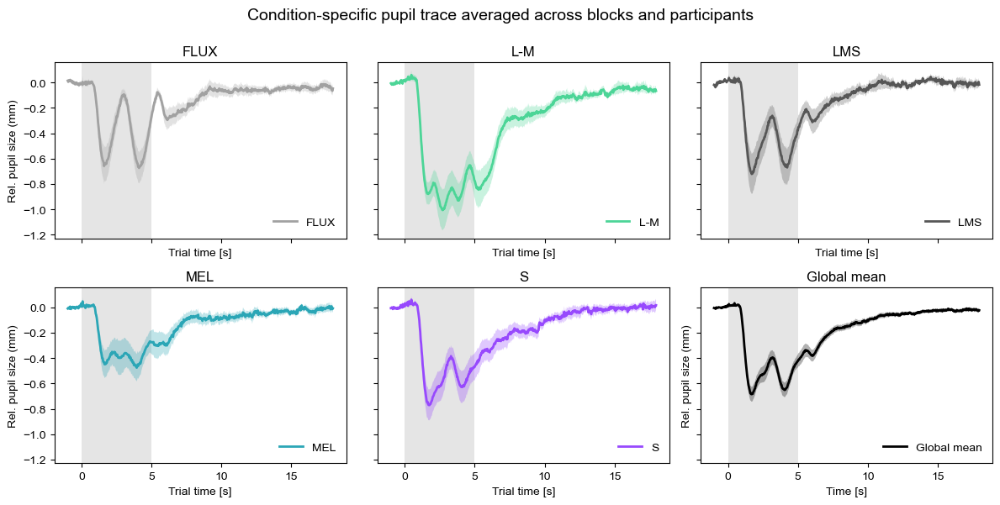

In [4]:
from civibeplr.aggregate_pupil_traces import main_all as aggregate

df_aggregated = aggregate(plot_by_participant=False, plot_by_condition=False)
df_aggregated.head()

In [5]:
n_rows, n_cols = df_aggregated.shape
n_participants = df_aggregated["Participant id"].nunique()
conditions = sorted(df_aggregated["Trial type"].unique())
n_blocks = df_aggregated["Block"].nunique()

display(Markdown(
    f"**Aggregated dataset:** {n_rows:,} rows x {n_cols} columns across "
    f"{n_participants} participants, {len(conditions)} conditions "
    f"({', '.join(conditions)}), up to {n_blocks} blocks per participant-condition."
))

**Aggregated dataset:** 226,860 rows x 11 columns across 8 participants, 5 conditions (flux, l-m, lms, mel, s), up to 11 blocks per participant-condition.

## Step 2 -- Calculate pupil metrics

Computes descriptive statistics for each participant x condition x block trace. Metrics cover the pre-stimulus, stimulus, and post-stimulus windows and include means, standard deviations, percentage changes relative to baseline, area under the curve (AUC), and peak-to-peak amplitude. Descriptive only; no later step uses them.

**In:** `data/aggregated/data.csv`
**Out:** `results/descriptives/` (`pupil_metrics_metadata.csv`, LaTeX tables)

In [6]:
from civibeplr.calculcate_descriptive_pupil_metrices import main as calculate_metrics

df_metrics = calculate_metrics()
df_metrics.head()

Loaded aggregated data: 226860 rows, 11 columns
Participants: 8
Conditions: ['flux', 'l-m', 'lms', 'mel', 's']

Calculating pupil metrics...

Calculated metrics for 398 participant × condition × block combinations.

Metrics summary:
       Participant id       Block  prestim_mean   stim_mean  poststim_mean  \
count      398.000000  398.000000    398.000000  398.000000     398.000000   
mean       205.788945    5.105528      5.683684    5.270842       5.571331   
std          4.823920    3.120408      0.876702    0.821262       0.834042   
min        200.000000    0.000000      3.858292    3.820446       4.026671   
25%        201.000000    2.000000      4.939094    4.607909       4.856998   
50%        204.000000    5.000000      5.757960    5.292725       5.642010   
75%        211.000000    8.000000      6.195973    5.766967       6.106743   
max        213.000000   10.000000      7.957798    7.518493       7.618832   

       prestim_std    stim_std  poststim_std  prestim_mean_pct  

,Participant id,Trial type,Block,prestim_mean,stim_mean,poststim_mean,prestim_std,stim_std,poststim_std,prestim_mean_pct,stim_mean_pct,poststim_mean_pct,prestim_std_pct,stim_std_pct,poststim_std_pct,stim_minus_prestim,amplitude_stim,auc_stim,auc_poststim_early,auc_poststim_late
0,200,flux,0,6.360998,6.072193,6.126648,0.048110,0.253814,0.098836,1.872576e-15,-4.540249,-3.684168,0.756320,3.990160,1.553774,-0.288805,-0.125316,-1.451687,-0.881888,-1.781507
1,200,flux,1,6.291743,5.956783,6.123103,0.060160,0.234404,0.111472,-9.029814e-16,-5.323796,-2.680338,0.956177,3.725577,1.771718,-0.334960,-0.154957,-1.679545,-1.302772,-0.641229
2,200,flux,2,5.783043,5.681796,6.070483,0.060601,0.231450,0.142217,-1.027326e-14,-1.750757,4.970399,1.047913,4.002212,2.459211,-0.101247,0.096056,-0.509019,0.697581,2.665368
3,200,flux,3,6.019932,5.703399,6.018687,0.028823,0.292404,0.075824,-9.336976e-15,-5.258078,-0.020685,0.478787,4.857264,1.259555,-0.316533,-0.077676,-1.592245,-0.242945,0.211985
4,200,flux,4,6.012127,5.658538,5.829409,0.034525,0.255545,0.108209,-9.621933e-16,-5.881278,-3.039158,0.574248,4.250486,1.799838,-0.353590,-0.092773,-1.774950,-0.637348,-1.585527


In [7]:
df_metrics.describe()

,Participant id,Block,prestim_mean,stim_mean,poststim_mean,prestim_std,stim_std,poststim_std,prestim_mean_pct,stim_mean_pct,poststim_mean_pct,prestim_std_pct,stim_std_pct,poststim_std_pct,stim_minus_prestim,amplitude_stim,auc_stim,auc_poststim_early,auc_poststim_late
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,3.980000e+02,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,396.000000,390.000000,387.000000
mean,205.788945,5.105528,5.683684,5.270842,5.571331,0.077486,0.287749,0.199352,-4.992640e-16,-7.133062,-1.824307,1.416600,5.061853,3.598254,-0.412841,-0.213229,-2.066960,-1.138963,-0.250890
std,4.823920,3.120408,0.876702,0.821262,0.834042,0.043559,0.138374,0.088373,6.734961e-15,5.094682,3.942930,0.907552,2.275494,1.738231,0.305990,0.184593,1.536842,1.392154,1.504000
min,200.000000,0.000000,3.858292,3.820446,4.026671,0.013183,0.038874,0.053819,-1.467715e-14,-22.572084,-17.317413,0.225744,0.536213,1.169559,-1.289731,-1.167299,-6.467229,-6.522713,-5.810901
25%,201.000000,2.000000,4.939094,4.607909,4.856998,0.049611,0.182013,0.132422,-5.606395e-15,-10.521832,-4.230284,0.847615,3.397682,2.271657,-0.609417,-0.301653,-3.063740,-1.877665,-1.159078
50%,204.000000,5.000000,5.757960,5.292725,5.642010,0.067449,0.258934,0.179993,-8.030613e-16,-6.678382,-1.855085,1.197264,4.836707,3.248790,-0.354803,-0.178329,-1.765459,-1.052358,-0.217337
75%,211.000000,8.000000,6.195973,5.766967,6.106743,0.091873,0.374343,0.246204,3.796500e-15,-3.403412,0.490148,1.691839,6.567729,4.411982,-0.190344,-0.088993,-0.951038,-0.227951,0.651816
max,213.000000,10.000000,7.957798,7.518493,7.618832,0.368165,0.742832,0.503367,1.586879e-14,7.934659,11.307469,8.436142,12.930622,10.514469,0.432849,0.160819,2.161209,3.119197,4.594834


In [8]:
n_combos = len(df_metrics)
stim_pct_mean = df_metrics["stim_mean_pct"].mean()
stim_pct_sd = df_metrics["stim_mean_pct"].std()
amp_mean = df_metrics["amplitude_stim"].mean()
amp_sd = df_metrics["amplitude_stim"].std()
prestim_mean_mm = df_metrics["prestim_mean"].mean()

display(Markdown(
    f"**Descriptive metrics:** {n_combos} participant x condition x block combinations. "
    f"Mean pre-stimulus pupil size: {prestim_mean_mm:.2f} mm. "
    f"Mean stimulus-period constriction: {stim_pct_mean:.1f}% +/- {stim_pct_sd:.1f}% relative to baseline. "
    f"Mean peak-to-peak amplitude during stimulus: {amp_mean:.3f} +/- {amp_sd:.3f} mm. "
    f"All conditions show net pupil constriction during stimulation (negative `stim_mean_pct`)."
))

**Descriptive metrics:** 398 participant x condition x block combinations. Mean pre-stimulus pupil size: 5.68 mm. Mean stimulus-period constriction: -7.1% +/- 5.1% relative to baseline. Mean peak-to-peak amplitude during stimulus: -0.213 +/- 0.185 mm. All conditions show net pupil constriction during stimulation (negative `stim_mean_pct`).

## Step 3 -- Fit 2-step cosinor model (pupil)

Decomposes each averaged trace into a tonic (slow) and a phasic (oscillatory) component:

1. **Tonic component:** a low-pass Butterworth filter (cutoff 0.2 Hz, order 2, applied forward and backward for zero phase) extracts the slow constriction. The tonic minimum and its latency are taken from this component.
2. **Phasic component:** the residual (raw trace minus tonic component) is fitted with a bi-harmonic cosinor: the stimulus frequency (0.4 Hz, the fundamental) plus the second harmonic (0.8 Hz, `_2f`). This yields amplitude and phase per harmonic, R-squared and fit indices (AIC, BIC).

The fit window is the stimulus period only (0-5 s). Each of the 398 participant x condition x block traces is fitted once.

**In:** `data/aggregated/data.csv`
**Out:** `results/tables/pupil_cosinor/` (`pupil_cosinor_2step_param.csv`, LaTeX tables), `results/tex/pupil_cosinor/` (`vars_` macros)

In [9]:
from civibeplr.fit_pupil_trace_2step_cosinor_model import main as fit_cosinor

df_cosinor = fit_cosinor(df_aggregated)
df_cosinor.head()

TWO-STEP COSINOR ANALYSIS
  Low-pass cutoff: 0.2 Hz  |  Filter order: 2
  Cosinor frequency: 0.4 Hz  |  Stim window: 0.0-5.0 s  |  Fit window: stimulus window only
  flux: 83/83 valid fits
  l-m: 74/74 valid fits
  lms: 80/80 valid fits
  mel: 80/80 valid fits
  s: 81/81 valid fits

Total: 398 fits  |  Valid: 398
Median R² (cosinor on residual): 0.6205
Median tonic min: -0.5025 mm after 3.350 sec.
Median sinusoidal amplitude: 0.1491 mm

Saved decomposition settings to /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/metadata/pupil_cosinor_2step_settings.json

Saved CSV: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/pupil_cosinor/pupil_cosinor_2step_param.csv
Saved LaTeX table: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/pupil_cosinor/tab_pupil_cosinor_2step_tonic.tex
Saved LaTeX table: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/pupil_cosinor/tab_pupil_cosinor_2step_phasic.tex
Saved CSV: /

,Participant id,Trial type,Block,baseline_mean,tonic_min,tonic_min_time,tonic_mean,beta_intercept,beta_sin,beta_cos,...,beta_cos2_ci_hi,amplitude_2f,phase_2f_rad,amplitude_ratio,r_squared,adj_r_squared,aic,bic,rmse,n_obs
0,200,flux,0,6.360998,-0.375475,2.066666,-0.279915,-0.009264,0.268579,0.068004,...,0.001276,0.043192,-1.843753,6.414491,0.925625,0.923588,-431.795696,-416.709297,0.056983,151
1,200,flux,1,6.291743,-0.412030,4.100000,-0.306547,-0.029125,0.217467,0.120408,...,0.002942,0.063713,-1.773615,3.901482,0.875056,0.871633,-371.486144,-356.399745,0.069578,151
2,200,flux,2,5.783043,-0.225616,4.200000,-0.087803,-0.013958,0.208945,0.091800,...,0.001501,0.020761,-2.327439,10.993029,0.848420,0.844267,-371.923541,-356.837142,0.069478,151
3,200,flux,3,6.019932,-0.400459,2.133333,-0.298376,-0.018953,0.313514,0.116264,...,0.017680,0.028445,-1.431041,11.755373,0.940583,0.938955,-413.690034,-398.603634,0.060504,151
4,200,flux,4,6.012127,-0.424740,2.333333,-0.339466,-0.014524,0.264977,0.045260,...,0.028831,0.034331,-1.113264,7.830081,0.912210,0.909805,-414.834347,-399.747948,0.060275,151


In [10]:
valid = df_cosinor["r_squared"].notna()
df_valid = df_cosinor.loc[valid]

n_fits = len(df_valid)
median_r2 = df_valid["r_squared"].median()
median_amp = df_valid["amplitude"].median()
median_tonic_min = df_valid["tonic_min"].median()
median_tonic_min_time = df_valid["tonic_min_time"].median()

display(Markdown(
    f"**Cosinor fit summary:** {n_fits} valid fits. "
    f"Median cosinor R-squared: {median_r2:.3f} -- models explain the majority of phasic variance. "
    f"Median sinusoidal amplitude: {median_amp:.4f} mm. "
    f"Median tonic minimum: {median_tonic_min:.4f} mm, occurring at {median_tonic_min_time:.2f} s after stimulus onset. "
    f"The tonic constriction peaks well within the 5 s stimulus window."
))

**Cosinor fit summary:** 398 valid fits. Median cosinor R-squared: 0.620 -- models explain the majority of phasic variance. Median sinusoidal amplitude: 0.1491 mm. Median tonic minimum: -0.5025 mm, occurring at 3.35 s after stimulus onset. The tonic constriction peaks well within the 5 s stimulus window.

## Step 3b -- Visualise pupil cosinor fits

Generates two sets of figures: (1) parameter plots summarising tonic and phasic parameters across conditions and participants, and (2) decomposition plots overlaying the raw trace, tonic component, and cosinor fit for each condition. Individual participant plots are disabled here for brevity (`plot_individual_participants=False`).

**In:** Step 3 results
**Out:** `results/figures/pupil_cosinor/`

Loaded results: 398 rows from /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/pupil_cosinor/pupil_cosinor_2step_param.csv
Saved Figure in: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/pupil_cosinor/fig_pupil_cosinor_parameters_single.png
Saved Figure in: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/pupil_cosinor/fig_pupil_cosinor_parameters.png
Saved Figure in: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/pupil_cosinor/fig_raincloud_parameters.png
Saved Figure in: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/pupil_cosinor/fig_param_changes_baseline_mean.png
Saved Figure in: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/pupil_cosinor/fig_param_changes_tonic_mean.png
Saved Figure in: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/pupil_cosinor/fig_param_changes_amplitude.png
Saved Figure in: /Users/hhe

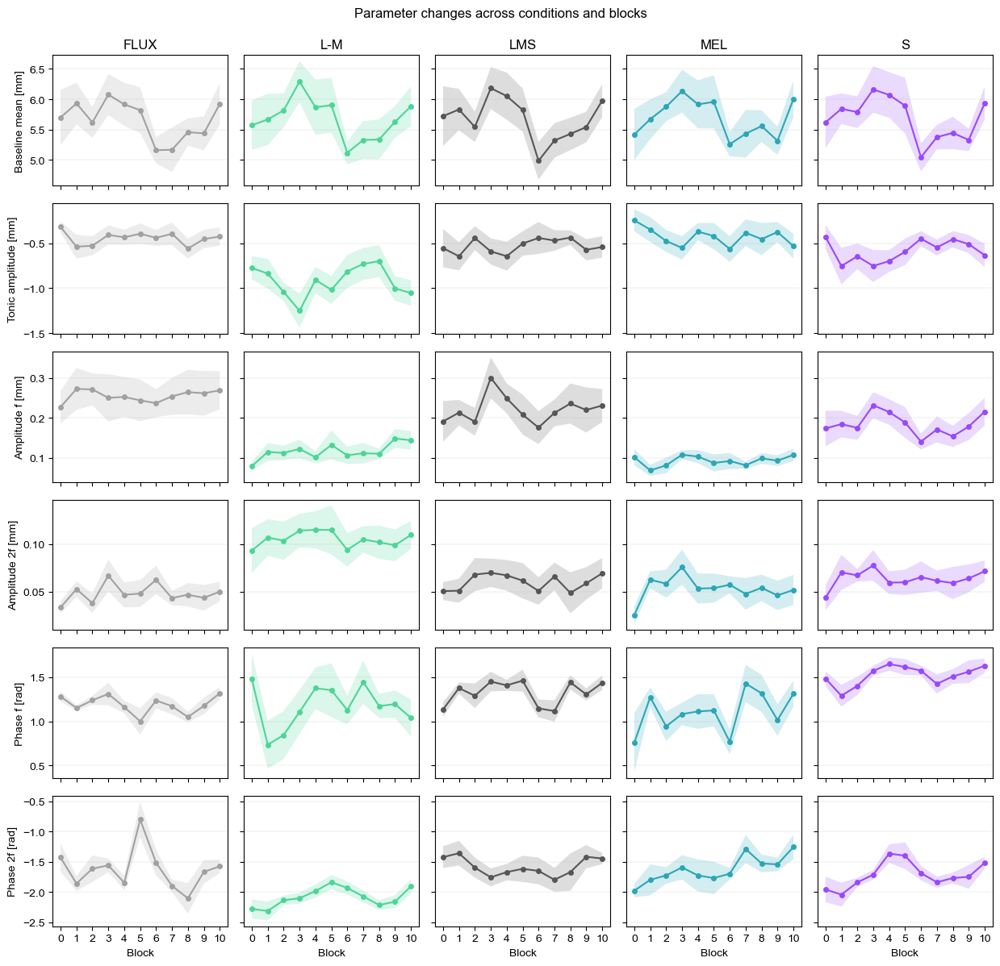

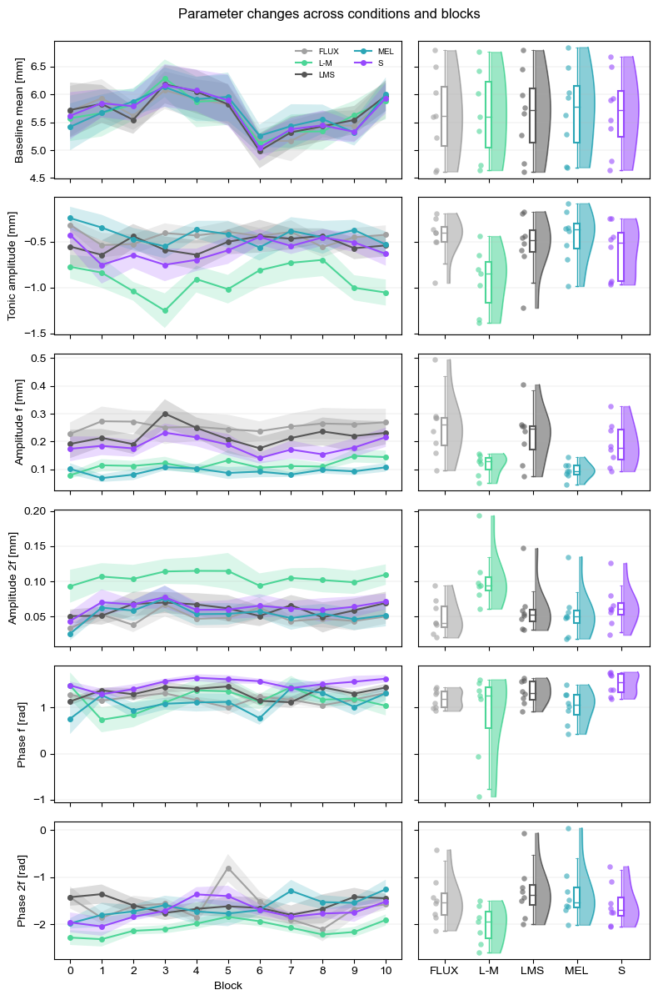

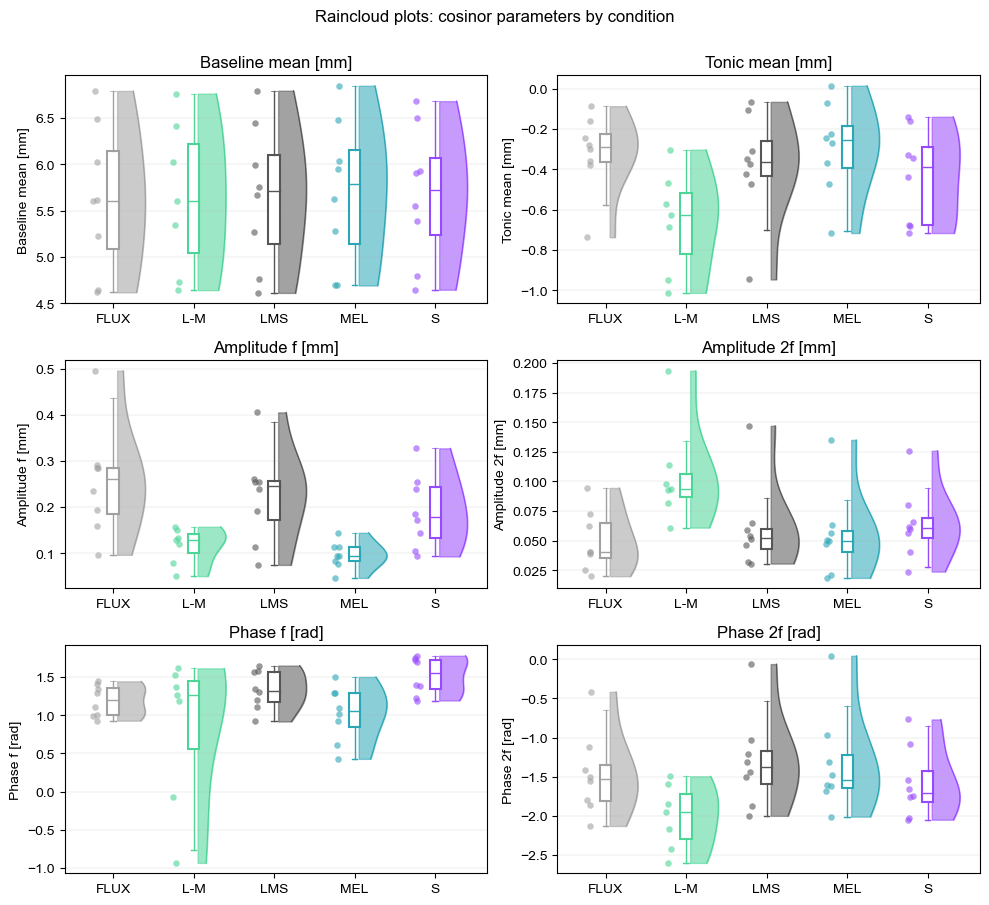

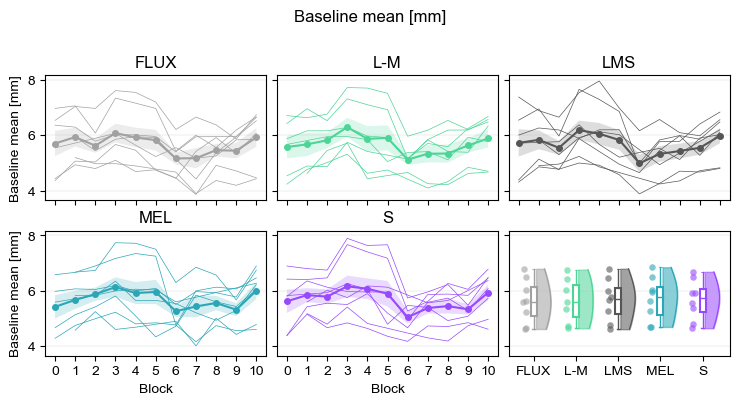

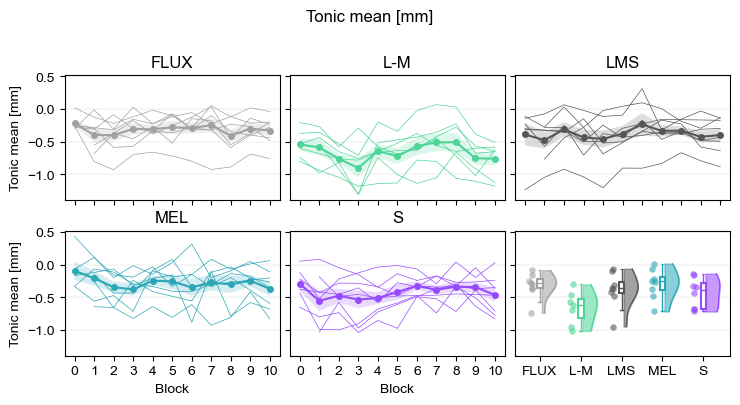

...

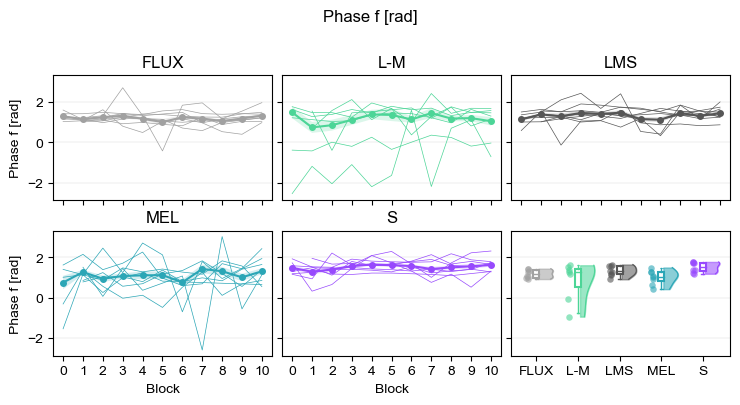

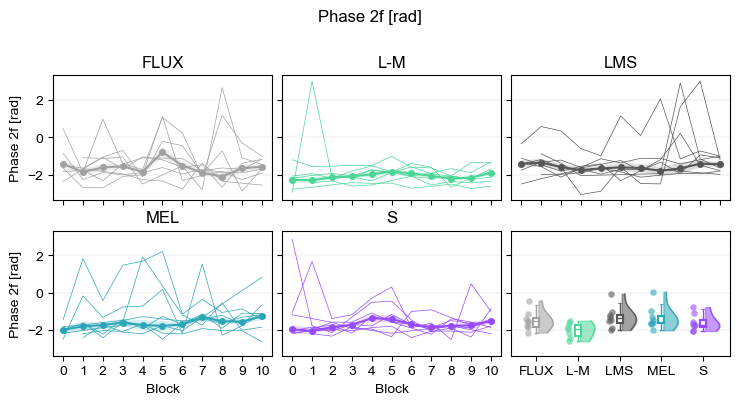

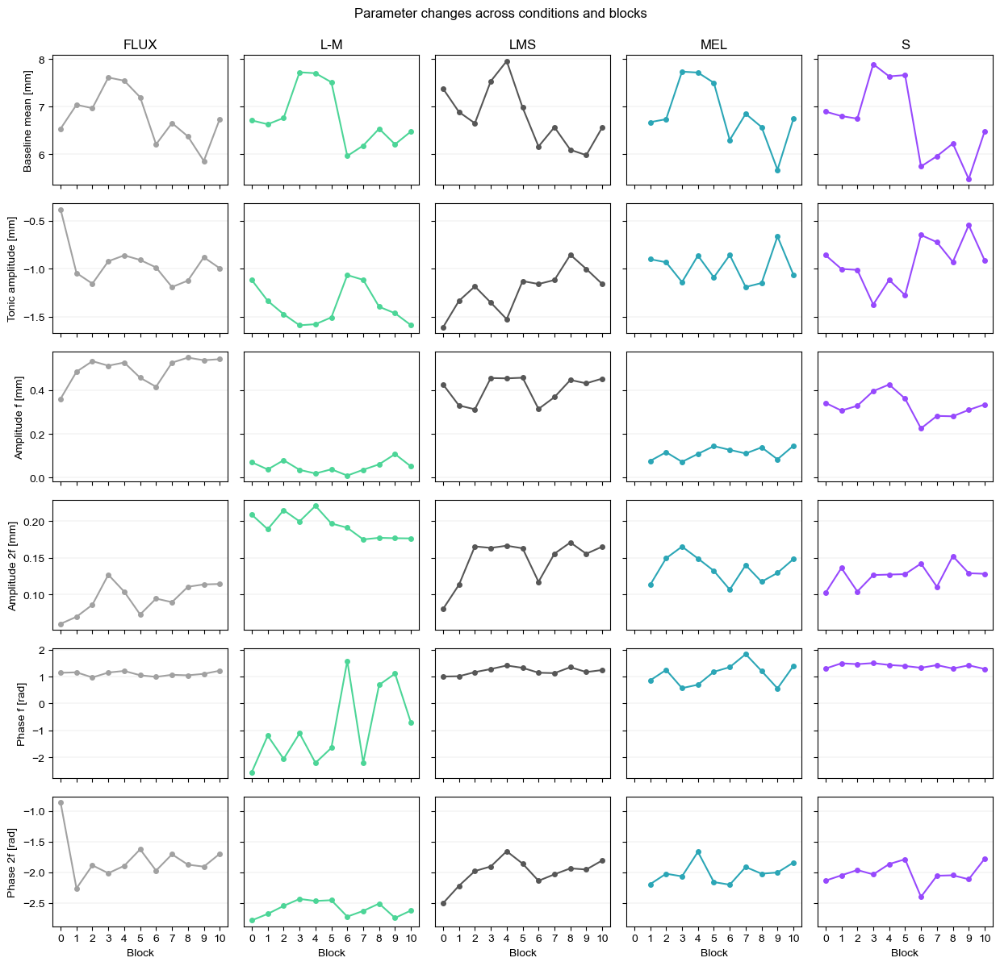

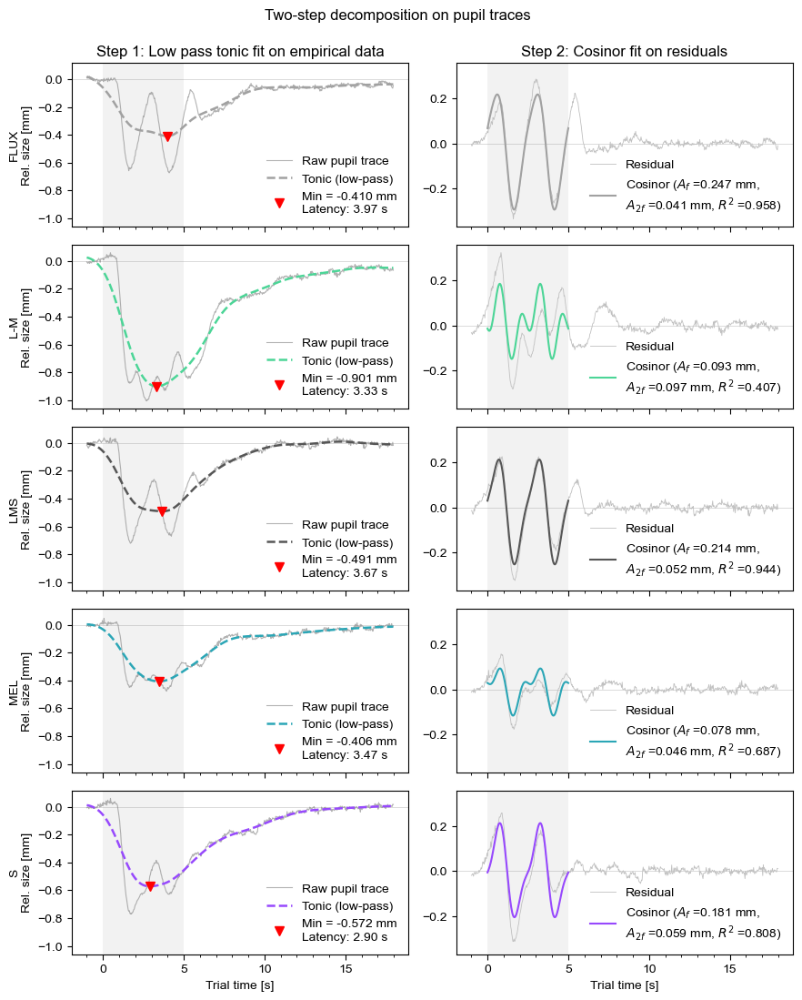

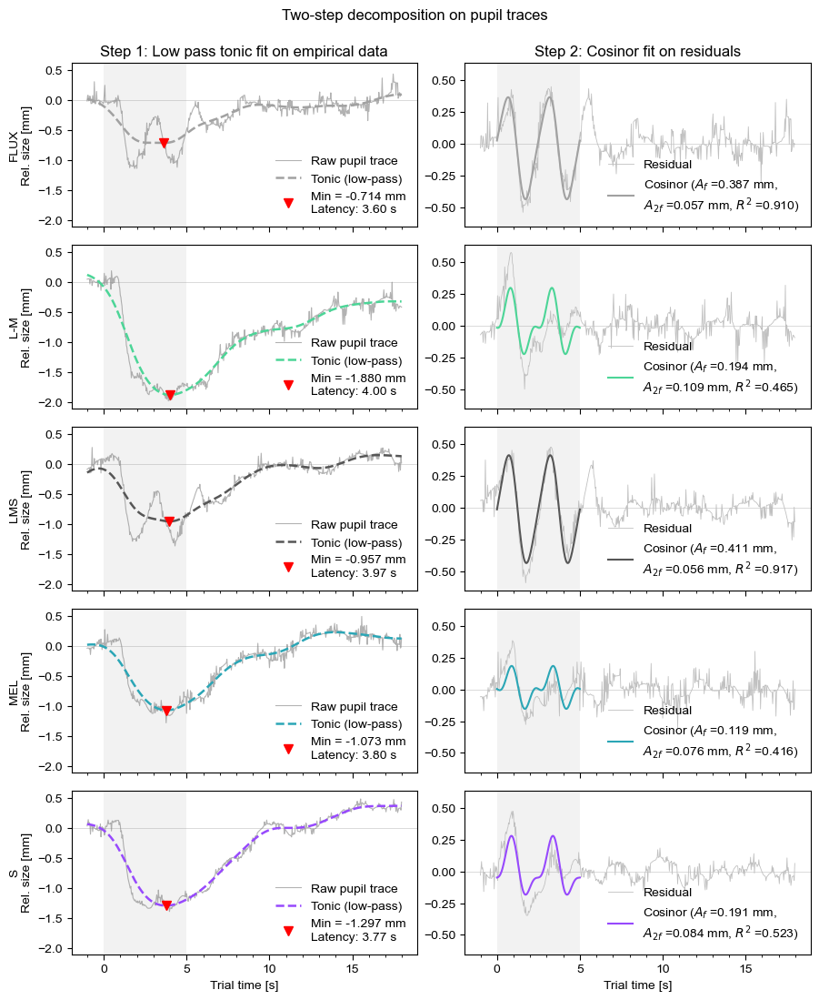

In [11]:
from civibeplr.visualise_pupil_cosinor import parameter_plots, decomposition_plots

parameter_plots()
decomposition_plots(results_df=df_cosinor, plot_individual_participants=False)

## Step 3c -- Diagnose pupil cosinor models

Two diagnostic figures for the Step 3 decomposition:

1. **Tonic scatter:** tonic minimum against tonic mean, per condition.
2. **R-squared distribution:** goodness of fit of the phasic cosinor, per condition.

**In:** `results/tables/pupil_cosinor/pupil_cosinor_2step_param.csv`
**Out:** `results/figures/pupil_cosinor_diagnostics/`

Saved Figure in: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/pupil_cosinor_diagnostics/fig_pupil_cosinor_tonic_scatter.png
Saved Figure in: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/pupil_cosinor_diagnostics/fig_pupil_cosinor_r_squared_distribution.png
Overwriting existing file: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tex/pupil_cosinor_diagnostics/vars_tonic_correlation_results.tex

Saved correlations to: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tex/pupil_cosinor_diagnostics/vars_tonic_correlation_results.tex
Saved LaTeX variables to: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tex/pupil_cosinor_diagnostics/vars_pupil_cosinor_summary.tex


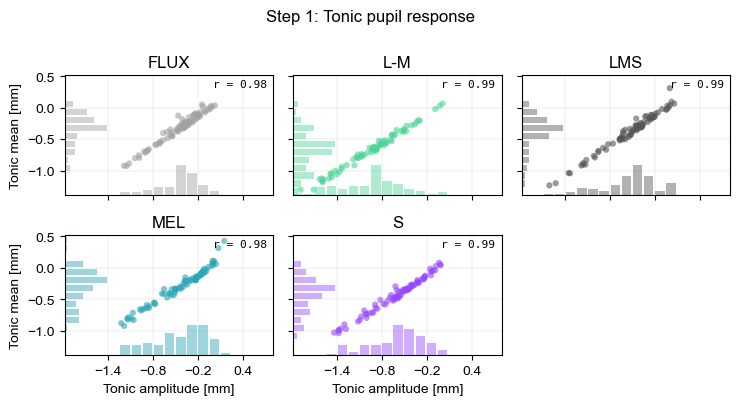

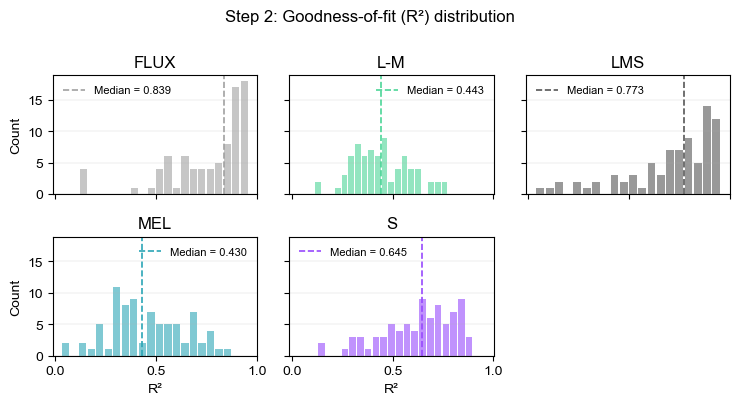

In [12]:
from civibeplr.diagnose_pupil_models import (
    run_diagnostics as diagnose_pupil,
    DEFAULT_RESULTS_CSV as PUPIL_DIAG_RESULTS_CSV,
    DEFAULT_FIG_DIR as PUPIL_DIAG_FIG_DIR,
)

pupil_diag_results = diagnose_pupil(results_csv=PUPIL_DIAG_RESULTS_CSV, fig_dir=PUPIL_DIAG_FIG_DIR)

## Step 4 -- Fit saliva cosinor model

Fits a cosinor with **two harmonics** to each participant's salivary melatonin series: the fundamental (period tau) plus the second harmonic (period tau/2), five parameters in total. The fit is repeated for every candidate tau from 22 to 28 h, and the tau with the lowest AIC is kept.

**What Step 5 uses:** only tau, which sets each participant's circadian period. Time in Step 5 is nominal block time since protocol start; the melatonin phase and amplitude are reported but not used to align the pupil data.

**Deviation from the protocol:** the protocol specified one harmonic and a 20-28 h search range (see `si_pipeline.ipynb`, Steps 4 and 6).

**In:** `data/raw/clean_saliva_data.csv`
**Out:** `results/tables/saliva_cosinor/saliva_cosinor_best_fit.csv` (plus figures and `vars_` macros)

Loaded clean saliva data: 791 rows, 14 columns
  Saliva-only participants (excluded — no valid pupillometry): [np.int64(205), np.int64(207), np.int64(209), np.int64(210)]

Summary of best-fit τ values across participants:
       tau_hours  beta_intercept   beta_sin  beta_cos  beta_sin2  beta_cos2  \
count   8.000000        8.000000   8.000000  8.000000   8.000000   8.000000   
mean   24.010417        7.683299 -10.056568  2.168612  -0.271860  -3.522857   
std     0.622842        1.618792   2.536324  3.126625   2.657590   1.080510   
min    23.066667        4.805661 -12.841891 -2.780751  -3.937989  -5.159242   
25%    23.620833        7.153609 -11.968037  0.912823  -1.687678  -4.094300   
50%    24.083333        7.461063 -10.118663  1.815130  -0.247548  -3.447217   
75%    24.250000        8.370533  -9.029617  3.499569   1.243836  -3.206329   
max    25.166667       10.459824  -5.098709  7.221880   3.667438  -1.600233   

       amplitude  amplitude_2f  phase_rad  phase_rad_2f  ...      

,tau_hours,beta_intercept,beta_sin,beta_cos,beta_sin2,beta_cos2,amplitude,amplitude_2f,phase_rad,phase_rad_2f,phase_hours,phase_hours_2f,rsquared,adjrsquared,aic,bic,rmse,n_obs,participant_id
0,22.000000,6.756374,-7.179726,4.506650,-2.548646,-2.245091,8.476931,3.396473,-1.010264,-2.292956,-3.537348,-4.014288,0.780358,0.765956,351.972981,362.921254,3.357365,66,200
1,22.016667,6.760894,-7.201901,4.489000,-2.538885,-2.265000,8.486371,3.402376,-1.013415,-2.299243,-3.551068,-4.028344,0.781863,0.767559,351.519251,362.467525,3.345844,66,200
2,22.033333,6.765418,-7.224002,4.471280,-2.528935,-2.284871,8.495796,3.408247,-1.016561,-2.305537,-3.564789,-4.042429,0.783358,0.769152,351.065319,362.013593,3.334358,66,200
3,22.050000,6.769948,-7.246029,4.453489,-2.518798,-2.304704,8.505204,3.414089,-1.019703,-2.311838,-3.578510,-4.056543,0.784844,0.770735,350.611207,361.559481,3.322906,66,200
4,22.066667,6.774482,-7.267980,4.435628,-2.508473,-2.324497,8.514595,3.419901,-1.022840,-2.318146,-3.592233,-4.070686,0.786320,0.772308,350.156938,361.105212,3.311491,66,200


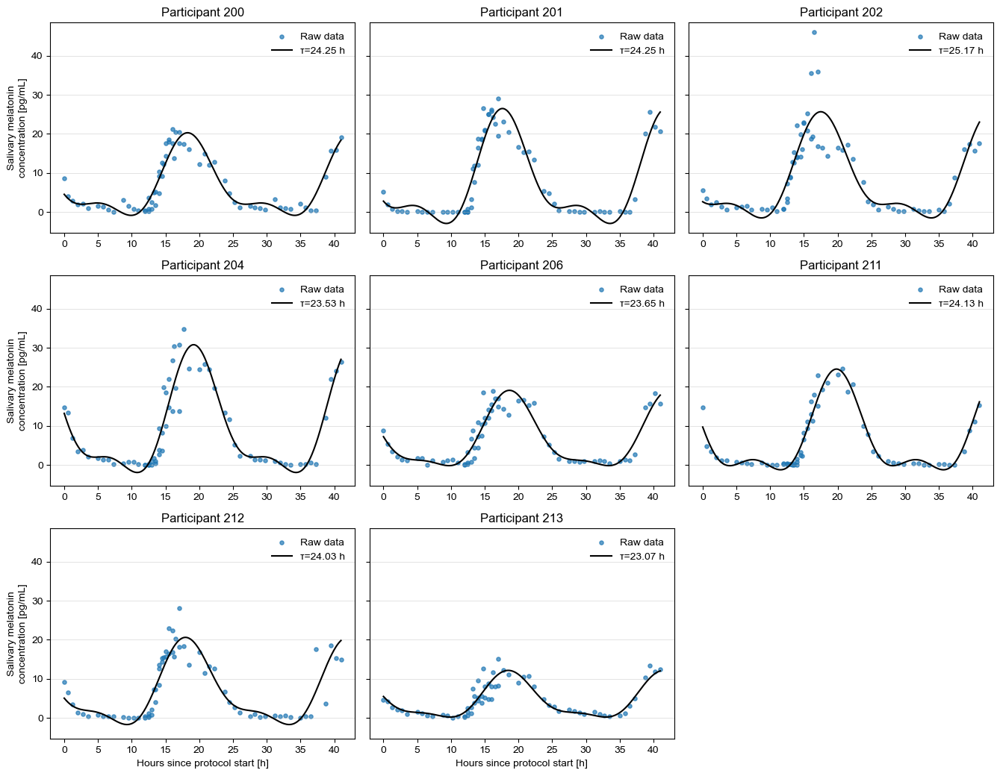

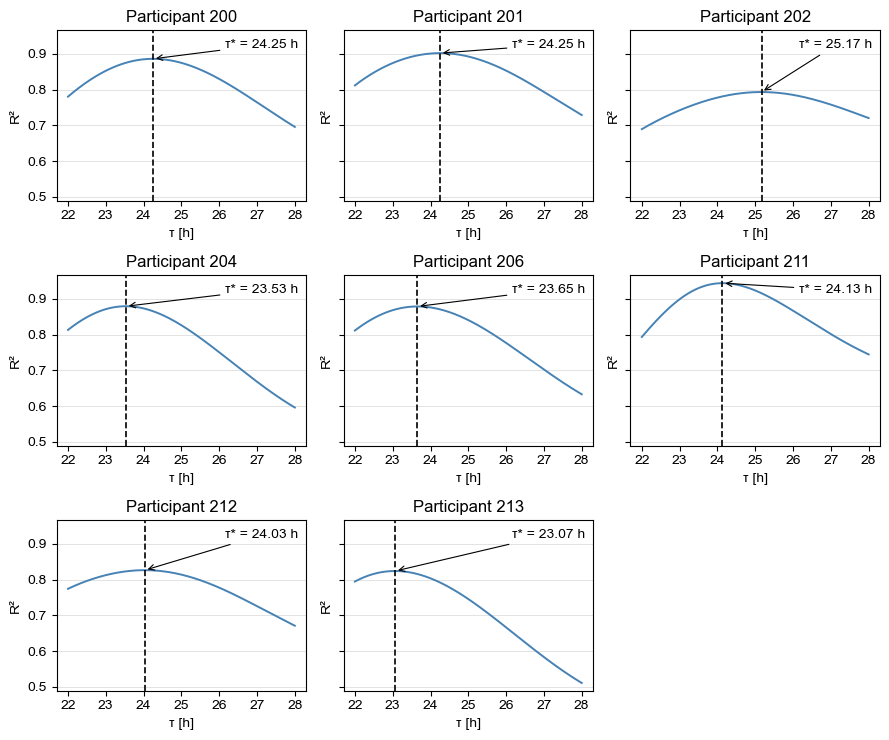

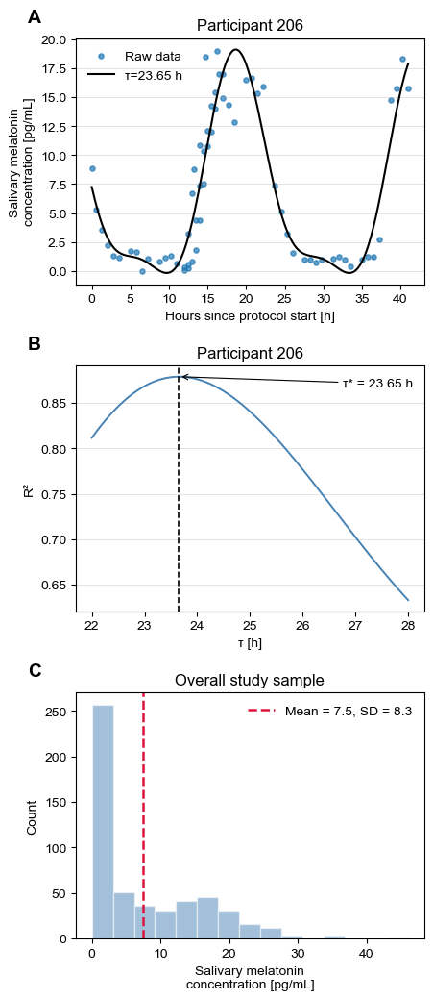

In [13]:
from civibeplr.fit_saliva_cosinor_model import main as fit_saliva

df_saliva, _ = fit_saliva()
df_saliva.head()

In [14]:
n_participants_saliva = df_saliva["participant_id"].nunique()
tau_mean = df_saliva["tau_hours"].mean()
tau_sd = df_saliva["tau_hours"].std()
tau_min = df_saliva["tau_hours"].min()
tau_max = df_saliva["tau_hours"].max()
phase_mean = df_saliva["phase_hours"].mean()
phase_sd = df_saliva["phase_hours"].std()
amp_mean_sal = df_saliva["amplitude"].mean()
r2_median_sal = df_saliva["rsquared"].median()

display(Markdown(
    f"**Saliva cosinor (best fit by AIC):** {n_participants_saliva} participants. "
    f"Best-fit tau: {tau_mean:.2f} +/- {tau_sd:.2f} h (range {tau_min:.1f}-{tau_max:.1f} h). "
    f"Mean fundamental amplitude: {amp_mean_sal:.3f}. "
    f"Mean acrophase: {phase_mean:.2f} +/- {phase_sd:.2f} h. "
    f"Median R-squared: {r2_median_sal:.3f}."
))

**Saliva cosinor (best fit by AIC):** 8 participants. Best-fit tau: 25.00 +/- 1.74 h (range 22.0-28.0 h). Mean fundamental amplitude: 10.166. Mean acrophase: -6.21 +/- 1.86 h. Median R-squared: 0.810.

## Parameter-wise analysis (Steps 4b, 5, 5b, 5c)

The following sections repeat Steps 4b-5c for each pupil outcome from Step 3. For each outcome:

- **Step 4b** inspects the pooled distribution per condition (histogram, Q-Q plot, Shapiro-Wilk, skewness, kurtosis) before modelling.
- **Step 5** compares, per condition, a constant-level model M0 (population and participant intercepts) with a circadian model M1, which adds sine and cosine terms at each participant's period tau from Step 4. Time is nominal block time ($t_b = 3.75\,b$ h). Both are fitted with Bayesian SMC, and the Bayes factor compares them.
- **Step 5b** runs model diagnostics: prior and posterior predictive checks, random-effects shrinkage, residual checks, residual autocorrelation, R-hat across SMC runs and the precision of log Z (how precisely the Bayes factor is known).
- **Step 5c** plots the fitted models against the observed data.

| Outcome | Description | Circadian model in manuscript |
|---|---|---|
| `baseline` | Pre-stimulus pupil size | Exploratory |
| `amplitude` | Phasic amplitude at 0.4 Hz (fundamental) | **Main** |
| `log_amplitude_2f` | Log phasic amplitude at 0.8 Hz (second harmonic) | Exploratory |
| `phase` | Phasic phase at 0.4 Hz | Exploratory |
| `phase_2f` | Phasic phase at 0.8 Hz | Exploratory |
| `tonic_min` | Tonic constriction minimum | **Main** |

Imports for all parameter-dependent steps.

In [15]:
from civibeplr.inspect_circadian_model import main as inspect_model
from civibeplr.analyse_circadian_pupil_parameters import main as analyse_circadian
from civibeplr.visualise_circadian_parameter_cosinor import main as visualise_circadian
from civibeplr.diagnose_circadian_models import run_diagnostics as diagnose_circadian

circadian_results = {}
circadian_diag_results = {}

## Outcome: baseline (exploratory)

Pre-stimulus mean pupil size (mm), averaged over the 1 s window preceding stimulus onset. It reflects the pupil state before each stimulus, independent of the chromatic condition.

**Out:** `results/tables/circadian_cosinor/baseline/`, `results/figures/circadian_cosinor/baseline/`, `results/{tables,figures}/circadian_cosinor_diagnostics/baseline/`

### Step 4b -- Inspect distributions: baseline

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'baseline'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83    5.652    0.887    0.155   -0.618   0.9824   0.3147  yes
l-m             74    5.673    0.893    0.224   -0.609   0.9774   0.2053  yes
lms             80    5.691    0.886    0.284   -0.418   0.9786   0.2011  yes
mel             80    5.702    0.879    0.243   -0.552   0.9773   0.1661  yes
s               81    5.700    0.860    0.403   -0.119   0.9722   0.0755  yes

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_baseline.png


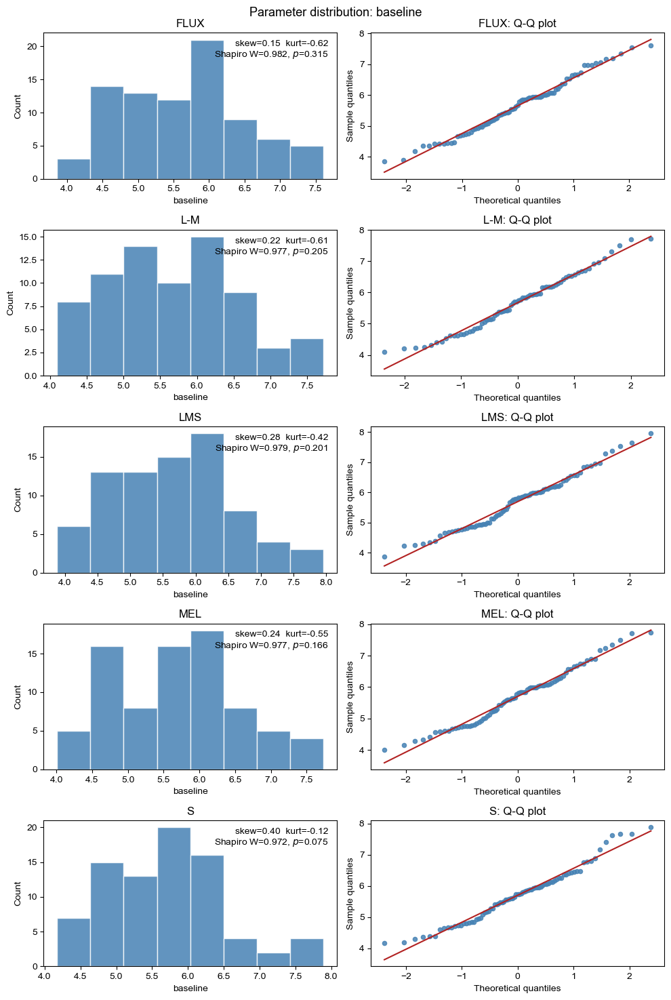

In [16]:
inspect_model(outcome_col="baseline")

### Step 5 -- Analyse circadian parameters: baseline

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'baseline'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83    5.652    0.887    0.155   -0.618   0.9824   0.3147  yes
l-m             74    5.673    0.893    0.224   -0.609   0.9774   0.2053  yes
lms             80    5.691    0.886    0.284   -0.418   0.9786   0.2011  yes
mel             80    5.702    0.879    0.243   -0.552   0.9773   0.1661  yes
s               81    5.700    0.860    0.403   -0.119   0.9722   0.0755  yes

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_baseline.png

Analysis dataframe: 398 rows
 participant_id Trial type  Block  hours_since_start  amplitude  log_amplitude     alpha      beta  saliva_tau_

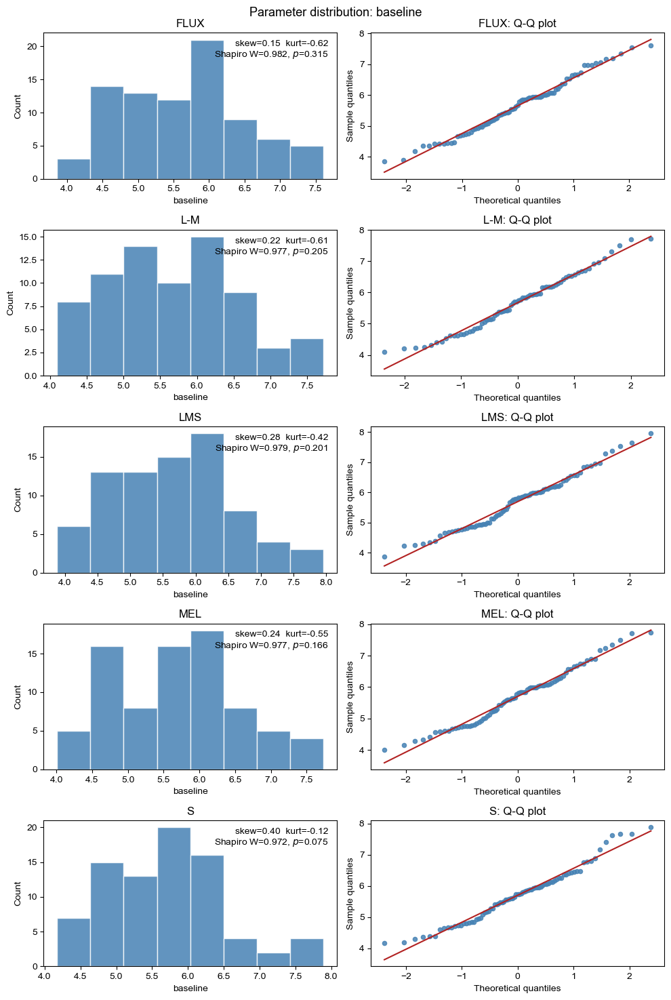

In [17]:
df_circadian_baseline, circadian_results["baseline"] = analyse_circadian(
    outcome_parameter="baseline",
    force=FORCE,
    dry_run=DRY_RUN,
    smc_draws=SMC_DRAWS,
    random_seed=SEED,
)

### Step 5b -- Diagnose circadian models: baseline

Auto-detected conditions: ['flux', 'l-m', 'lms', 'mel', 's']

── Condition: FLUX ──────────────────
  Bayesian p-value: p_B(mean)=0.504  p_B(SD)=0.573
  Saved: posterior_params_flux.csv
  r_hat  M0 max=1.0009  M1 max=1.0198 [!]
  Saved: fig_baseline_diagnostics_flux.png

── Condition: L-M ──────────────────
  Bayesian p-value: p_B(mean)=0.551  p_B(SD)=0.565
  Saved: posterior_params_l-m.csv
  r_hat  M0 max=1.0026  M1 max=1.0030
  Saved: fig_baseline_diagnostics_l-m.png

── Condition: LMS ──────────────────
  Bayesian p-value: p_B(mean)=0.548  p_B(SD)=0.575
  Saved: posterior_params_lms.csv
  r_hat  M0 max=1.0013  M1 max=1.0035
  Saved: fig_baseline_diagnostics_lms.png

── Condition: MEL ──────────────────
  Bayesian p-value: p_B(mean)=0.526  p_B(SD)=0.567
  Saved: posterior_params_mel.csv
  r_hat  M0 max=1.0097  M1 max=1.0062
  Saved: fig_baseline_diagnostics_mel.png

── Condition: S ──────────────────
  Bayesian p-value: p_B(mean)=0.549  p_B(SD)=0.567
  Saved: posterior_params_s.csv
 

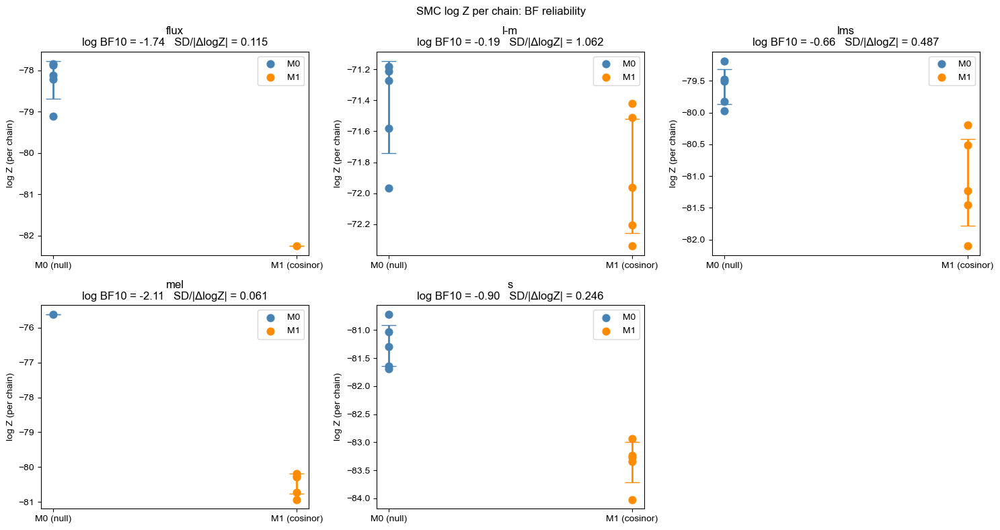

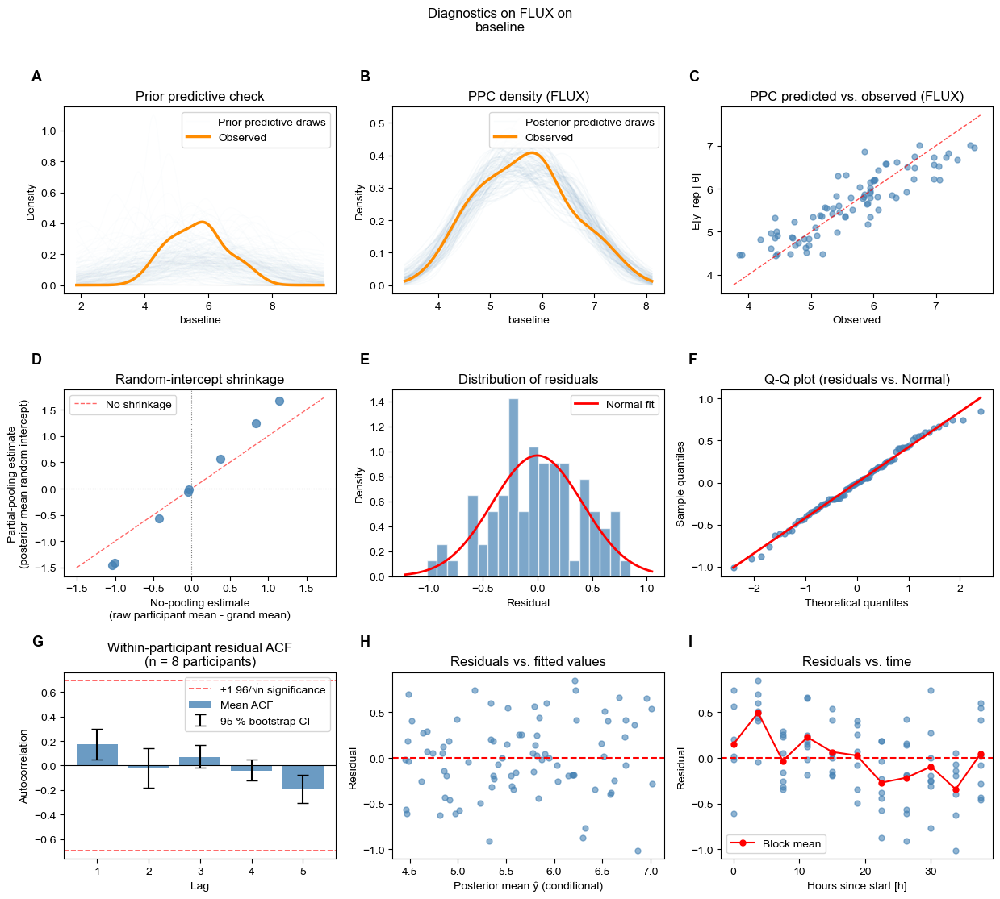

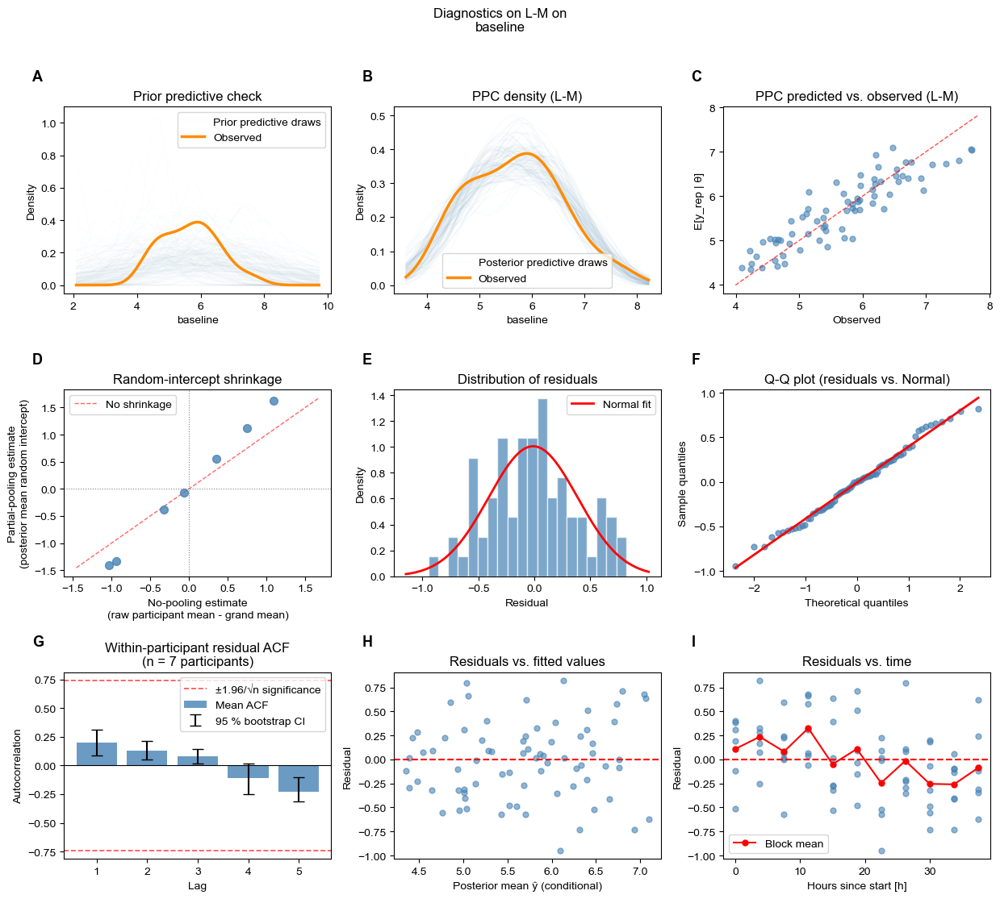

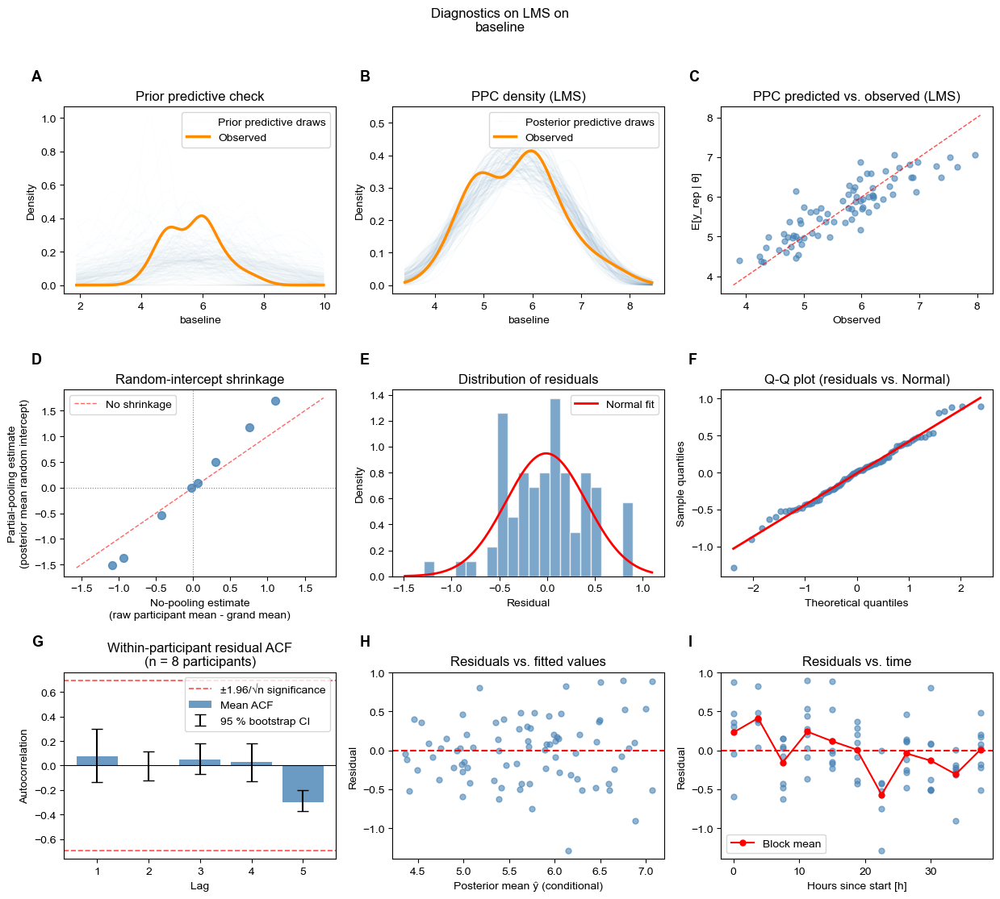

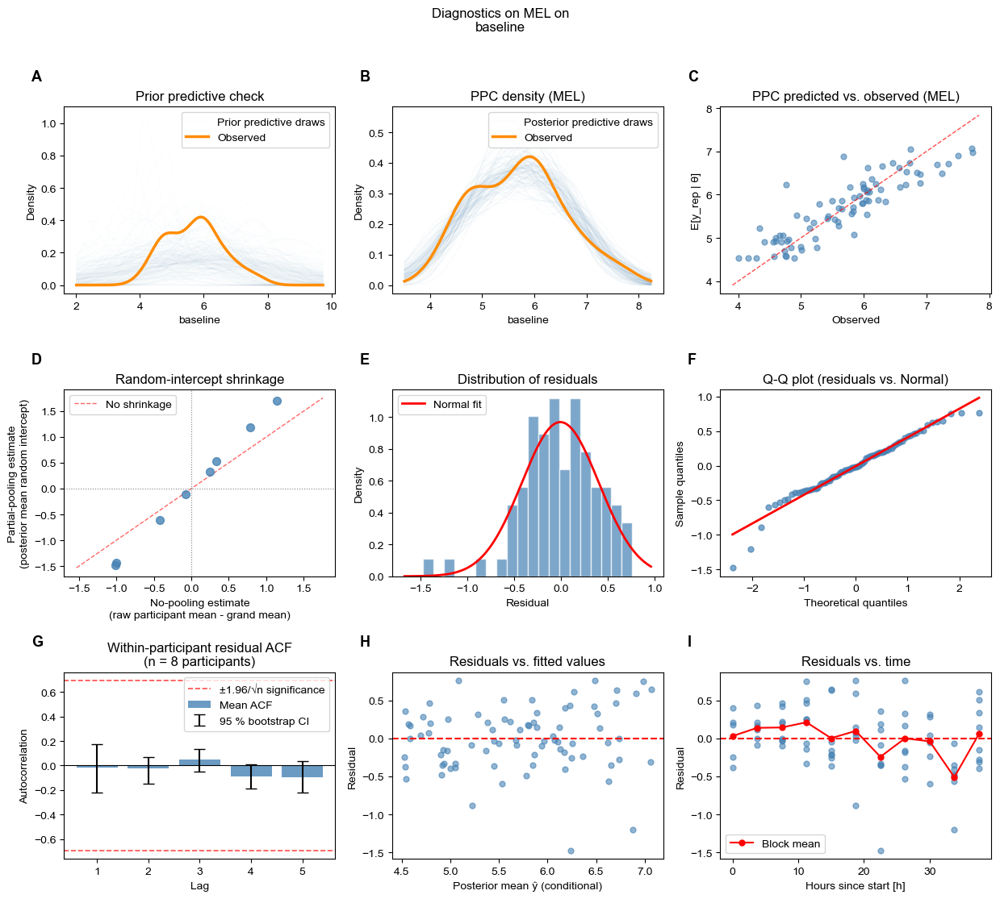

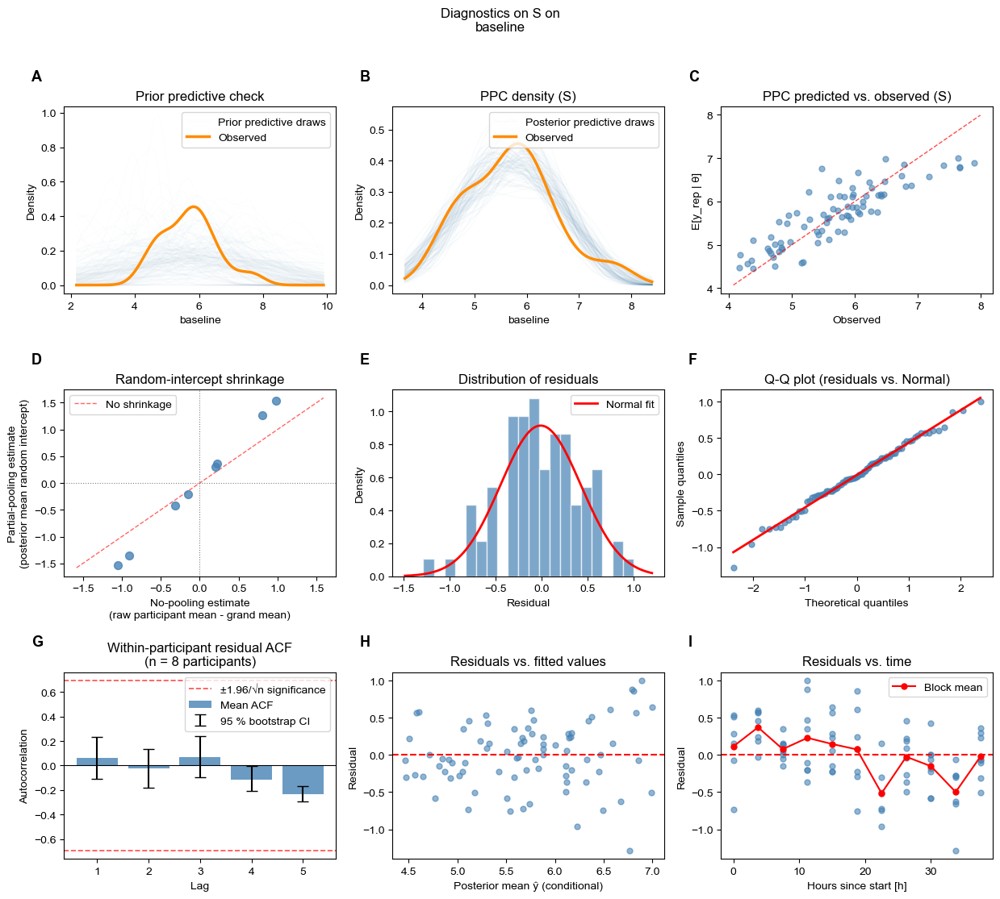

In [18]:
circadian_diag_results["baseline"] = diagnose_circadian(parameter_col="baseline")

### Step 5c -- Visualise circadian fits: baseline


── Condition: FLUX ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/baseline/fig_fitted_vs_empirical_flux.png

── Condition: L-M ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/baseline/fig_fitted_vs_empirical_l-m.png

── Condition: LMS ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/baseline/fig_fitted_vs_empirical_lms.png

── Condition: MEL ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/baseline/fig_fitted_vs_empirical_mel.png

── Condition: S ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/baseline/fig_fitted_vs_empirical_s.png

── All conditions ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/res

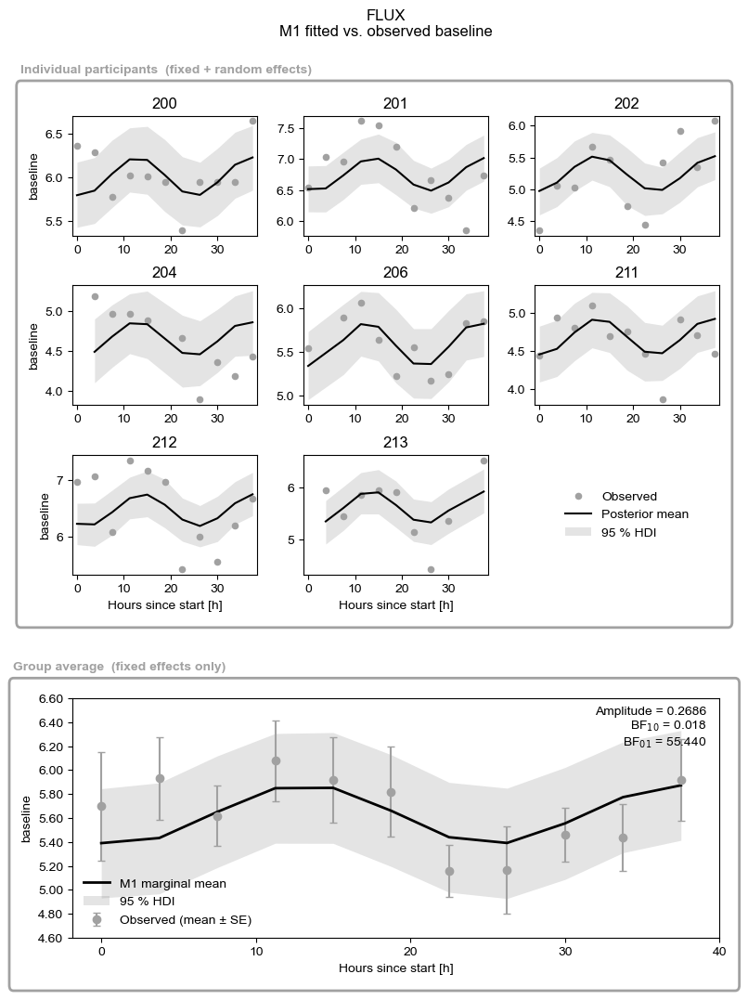

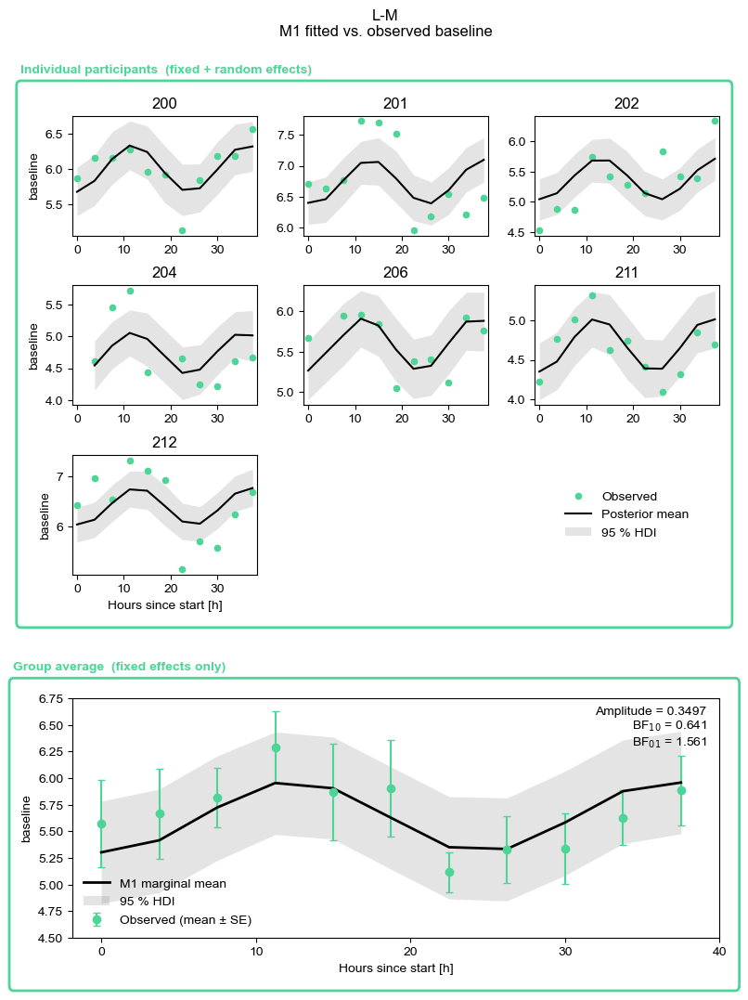

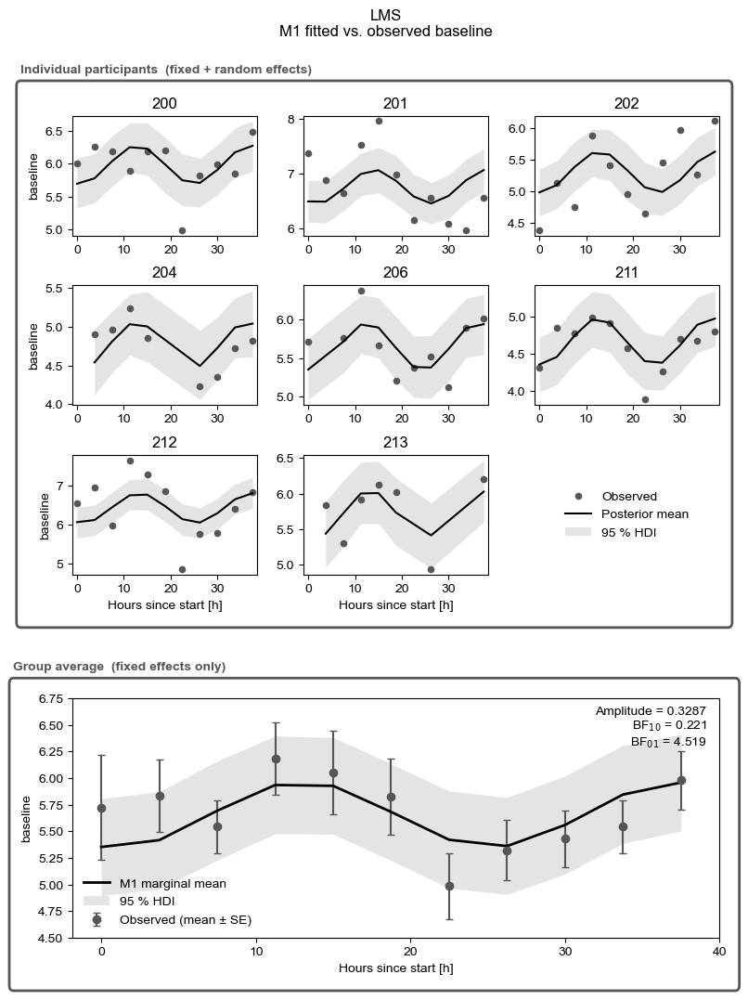

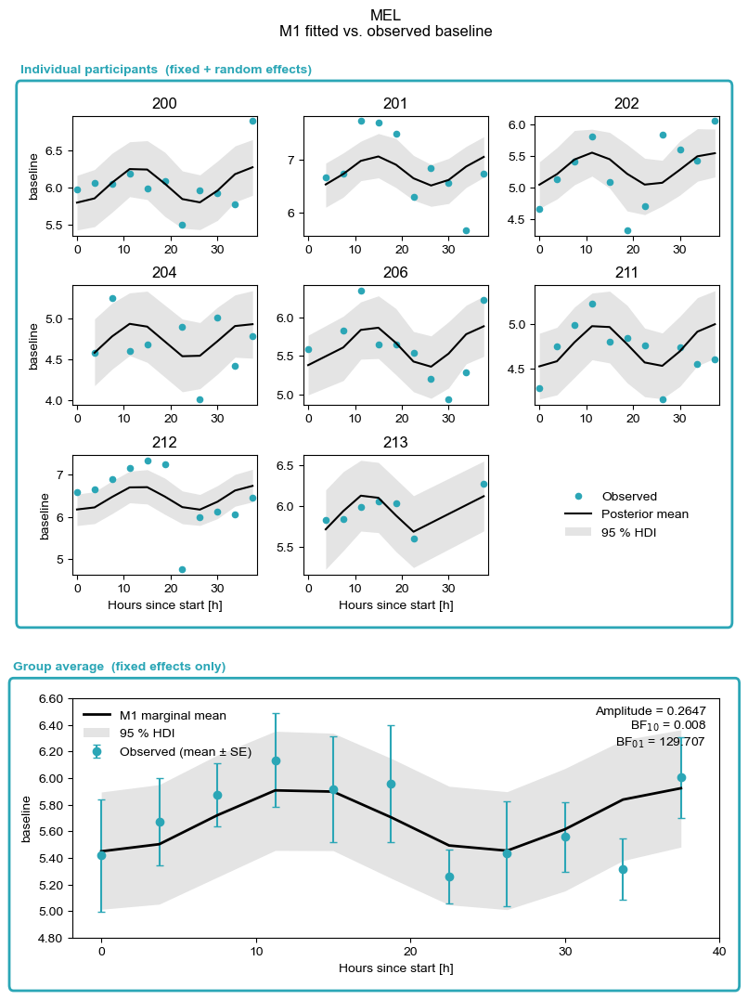

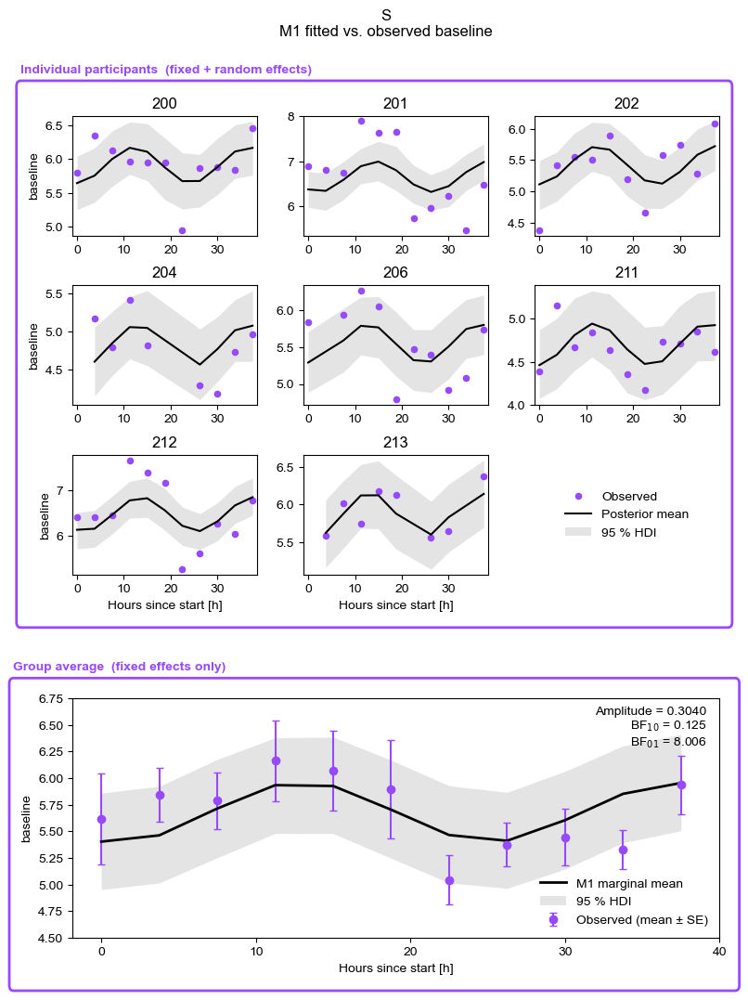

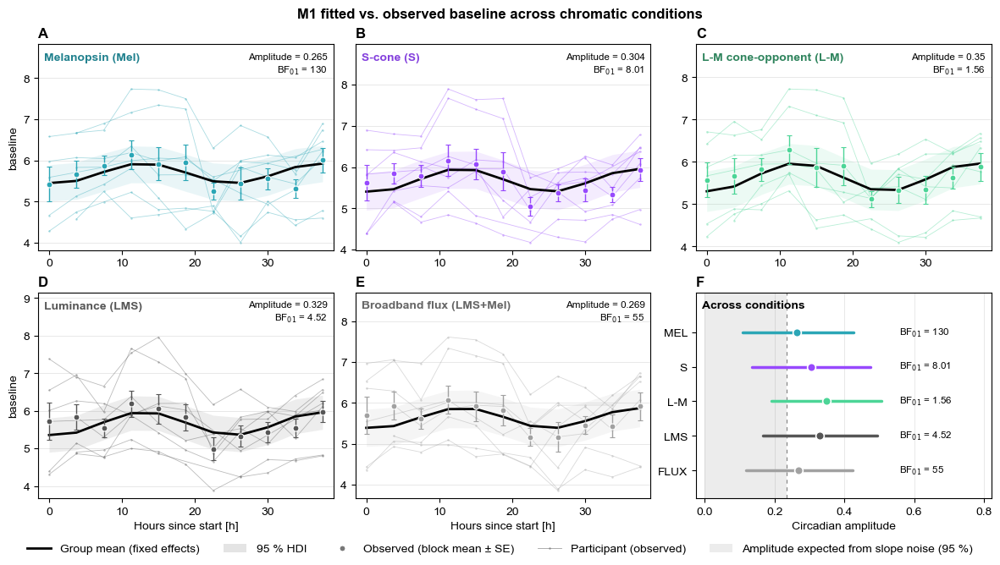

In [19]:
visualise_circadian(outcome_col="baseline")

## Outcome: amplitude (main)

Phasic amplitude at the stimulus frequency (0.4 Hz, fundamental), from the Step 3 cosinor. It measures how strongly the pupil tracks the chromatic modulation. This is a main outcome of the manuscript, but a *revised* one: the protocol's registered outcome was maximum constriction relative to flux (analysed in `si_pipeline.ipynb`).

**Out:** `results/tables/circadian_cosinor/amplitude/`, `results/figures/circadian_cosinor/amplitude/`, `results/{tables,figures}/circadian_cosinor_diagnostics/amplitude/`

### Step 4b -- Inspect distributions: amplitude

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'amplitude'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83    0.256    0.129    0.527   -0.060   0.9556   0.0060  NO
l-m             74    0.117    0.056    0.323   -0.680   0.9672   0.0514  yes
lms             80    0.223    0.116    0.357   -0.441   0.9691   0.0494  NO
mel             80    0.093    0.043    0.066   -0.618   0.9867   0.5817  yes
s               81    0.186    0.088    0.570   -0.219   0.9656   0.0282  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_amplitude.png


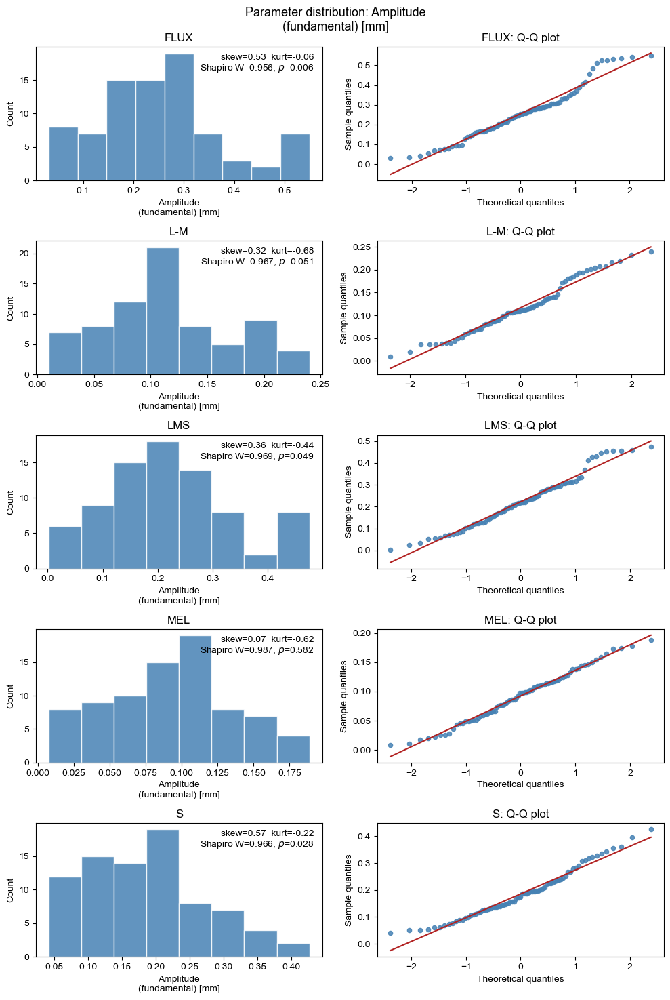

In [20]:
inspect_model(outcome_col="amplitude")

### Step 5 -- Analyse circadian parameters: amplitude

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'amplitude'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83    0.256    0.129    0.527   -0.060   0.9556   0.0060  NO
l-m             74    0.117    0.056    0.323   -0.680   0.9672   0.0514  yes
lms             80    0.223    0.116    0.357   -0.441   0.9691   0.0494  NO
mel             80    0.093    0.043    0.066   -0.618   0.9867   0.5817  yes
s               81    0.186    0.088    0.570   -0.219   0.9656   0.0282  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_amplitude.png

Analysis dataframe: 398 rows
 participant_id Trial type  Block  hours_since_start  amplitude  log_amplitude     alpha      beta  saliva_tau_h

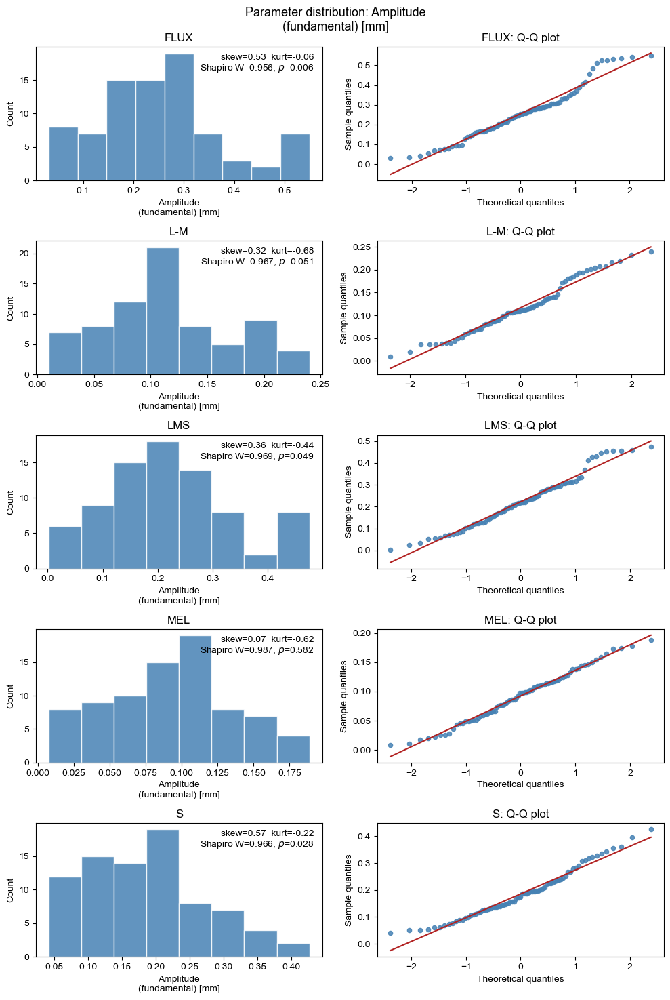

In [21]:
df_circadian_amplitude, circadian_results["amplitude"] = analyse_circadian(
    outcome_parameter="amplitude",
    force=FORCE,
    dry_run=DRY_RUN,
    smc_draws=SMC_DRAWS,
    random_seed=SEED,
)

### Step 5b -- Diagnose circadian models: amplitude


Auto-detected conditions: ['flux', 'l-m', 'lms', 'mel', 's']

── Condition: FLUX ──────────────────
  Bayesian p-value: p_B(mean)=0.554  p_B(SD)=0.570
  Saved: posterior_params_flux.csv
  r_hat  M0 max=1.0078  M1 max=1.0022
  Saved: fig_log_amplitude_diagnostics_flux.png

── Condition: L-M ──────────────────
  Bayesian p-value: p_B(mean)=0.554  p_B(SD)=0.671
  Saved: posterior_params_l-m.csv
  r_hat  M0 max=1.0018  M1 max=1.0009
  Saved: fig_log_amplitude_diagnostics_l-m.png

── Condition: LMS ──────────────────
  Bayesian p-value: p_B(mean)=0.552  p_B(SD)=0.571
  Saved: posterior_params_lms.csv
  r_hat  M0 max=1.0077  M1 max=1.0019
  Saved: fig_log_amplitude_diagnostics_lms.png

── Condition: MEL ──────────────────
  Bayesian p-value: p_B(mean)=0.469  p_B(SD)=0.649
  Saved: posterior_params_mel.csv
  r_hat  M0 max=1.0032  M1 max=1.0011
  Saved: fig_log_amplitude_diagnostics_mel.png

── Condition: S ──────────────────
  Bayesian p-value: p_B(mean)=0.460  p_B(SD)=0.577
  Saved: posterio

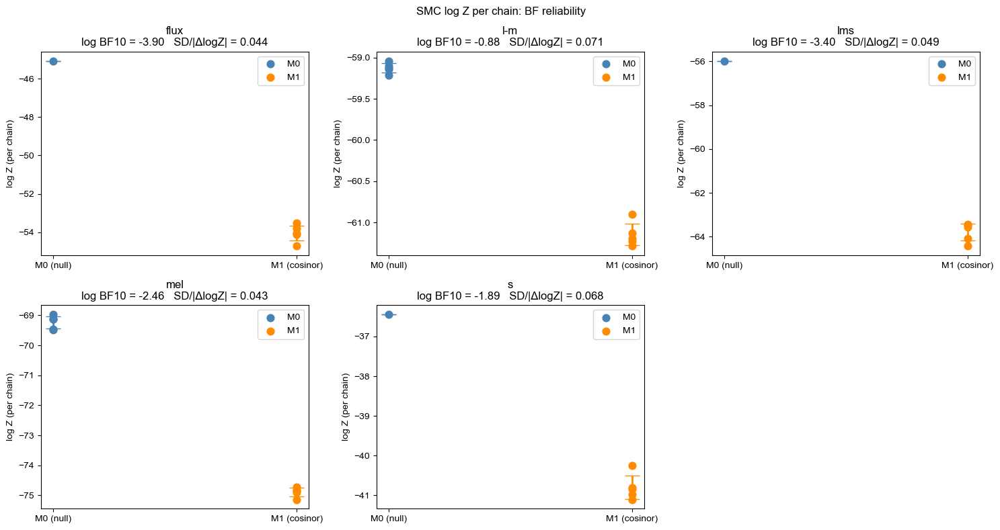

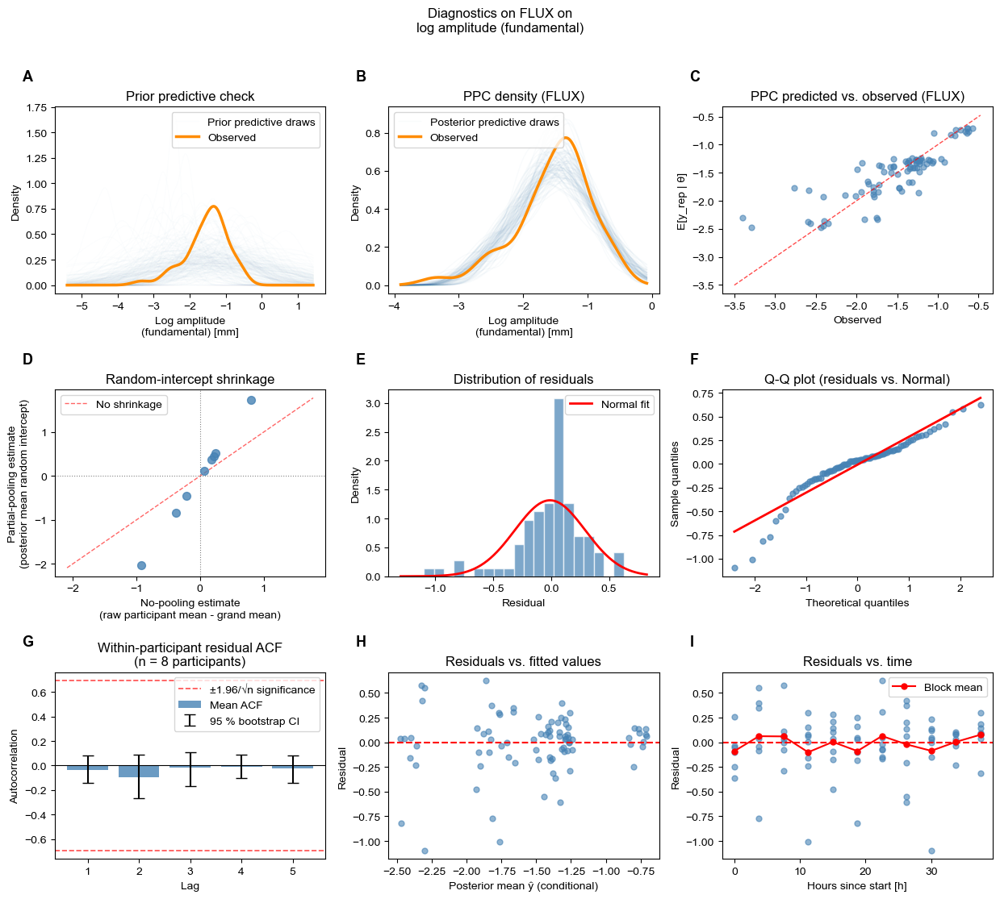

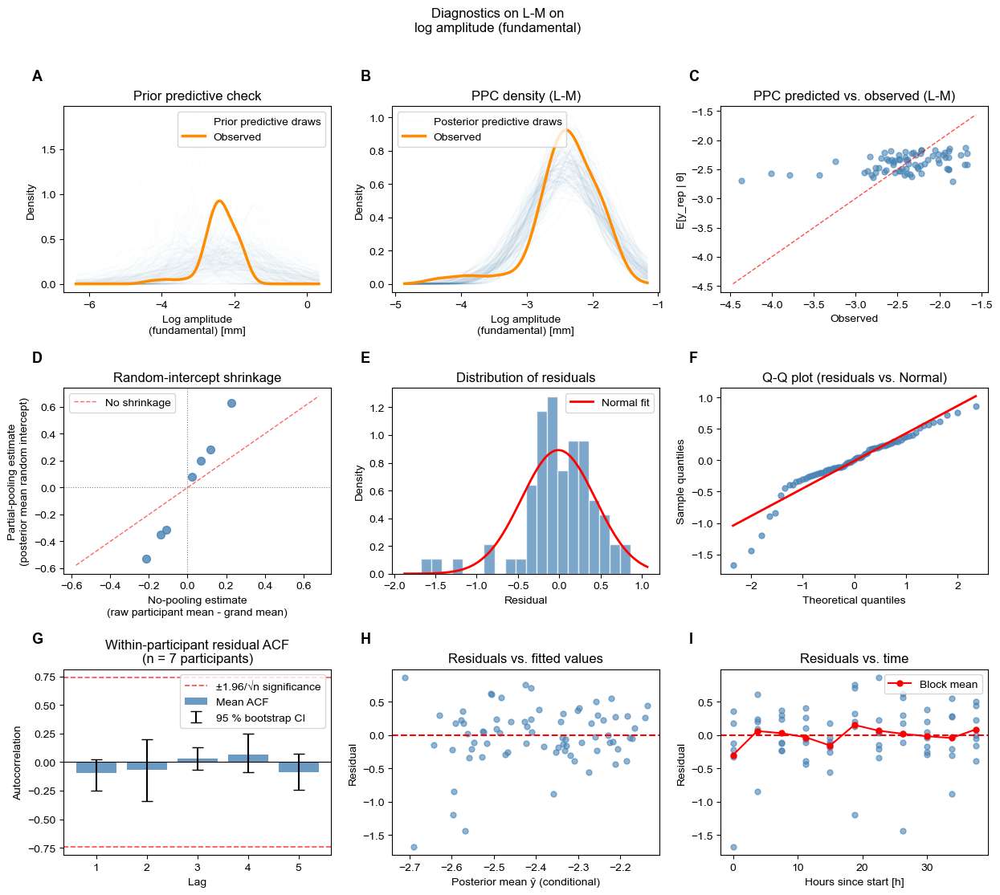

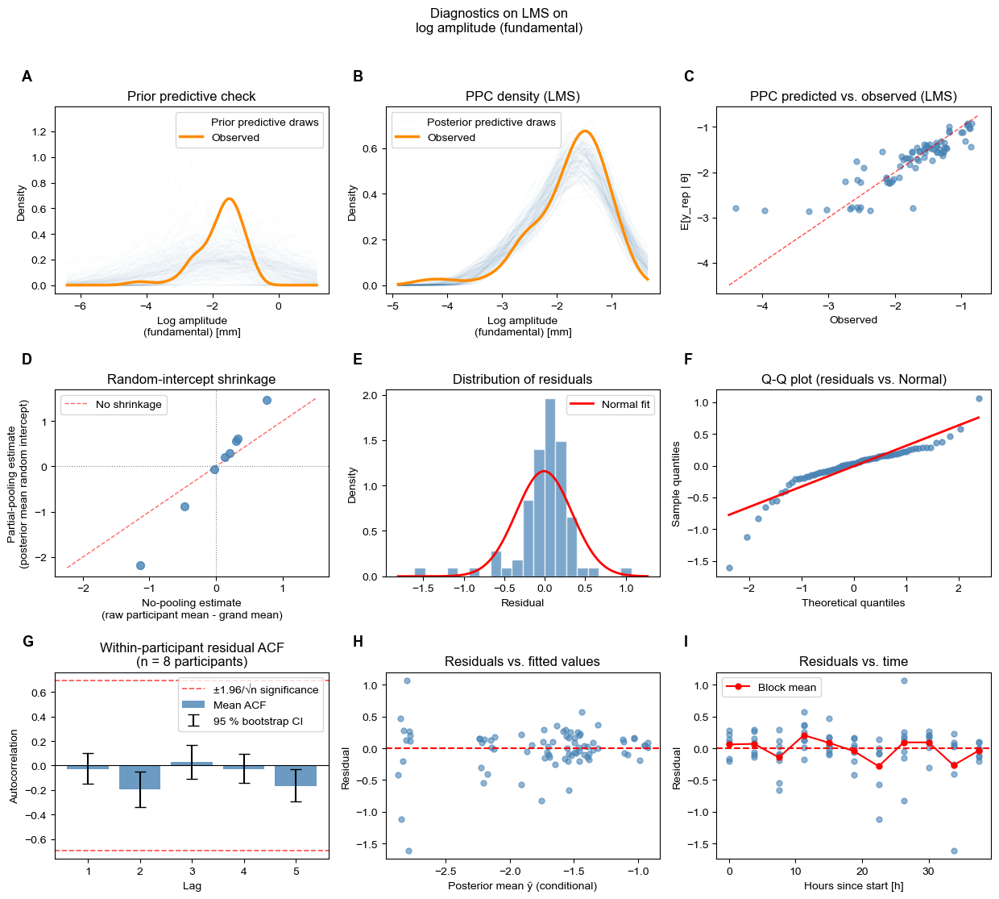

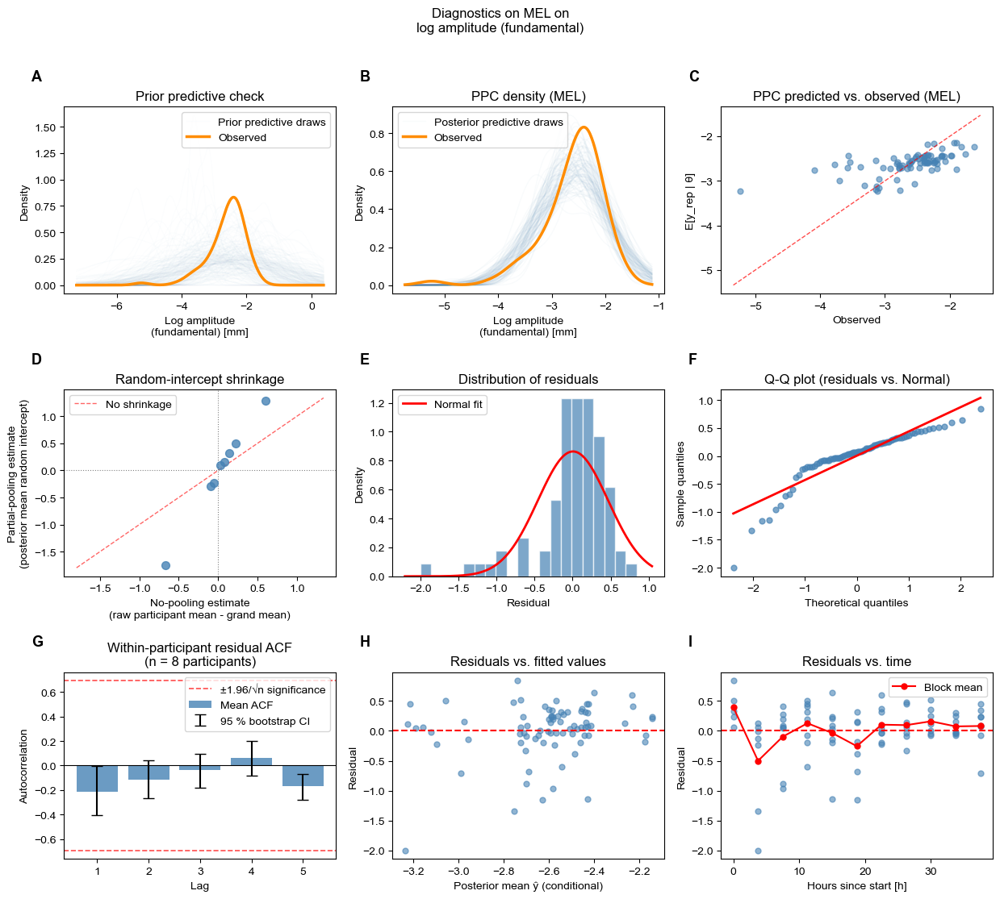

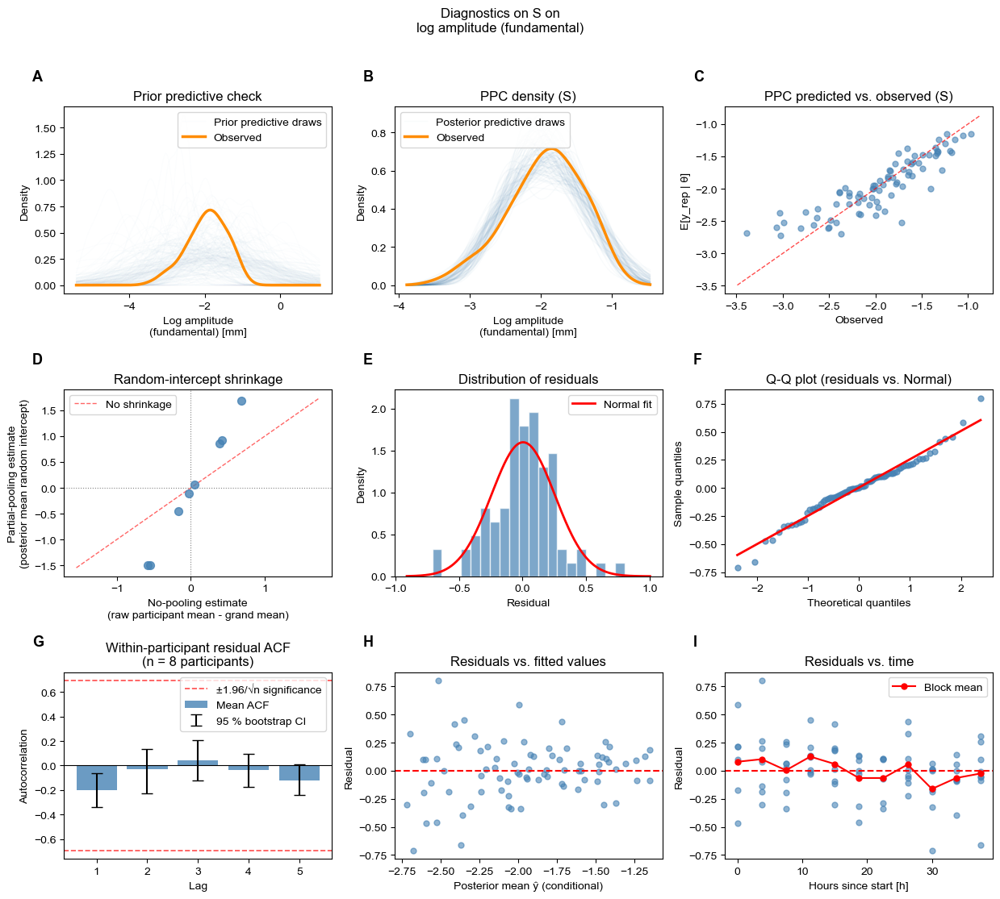

In [22]:
circadian_diag_results["amplitude"] = diagnose_circadian(parameter_col="amplitude")


### Step 5c -- Visualise circadian fits: amplitude


── Condition: FLUX ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/amplitude/fig_fitted_vs_empirical_flux.png

── Condition: L-M ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/amplitude/fig_fitted_vs_empirical_l-m.png

── Condition: LMS ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/amplitude/fig_fitted_vs_empirical_lms.png

── Condition: MEL ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/amplitude/fig_fitted_vs_empirical_mel.png

── Condition: S ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/amplitude/fig_fitted_vs_empirical_s.png

── All conditions ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometr

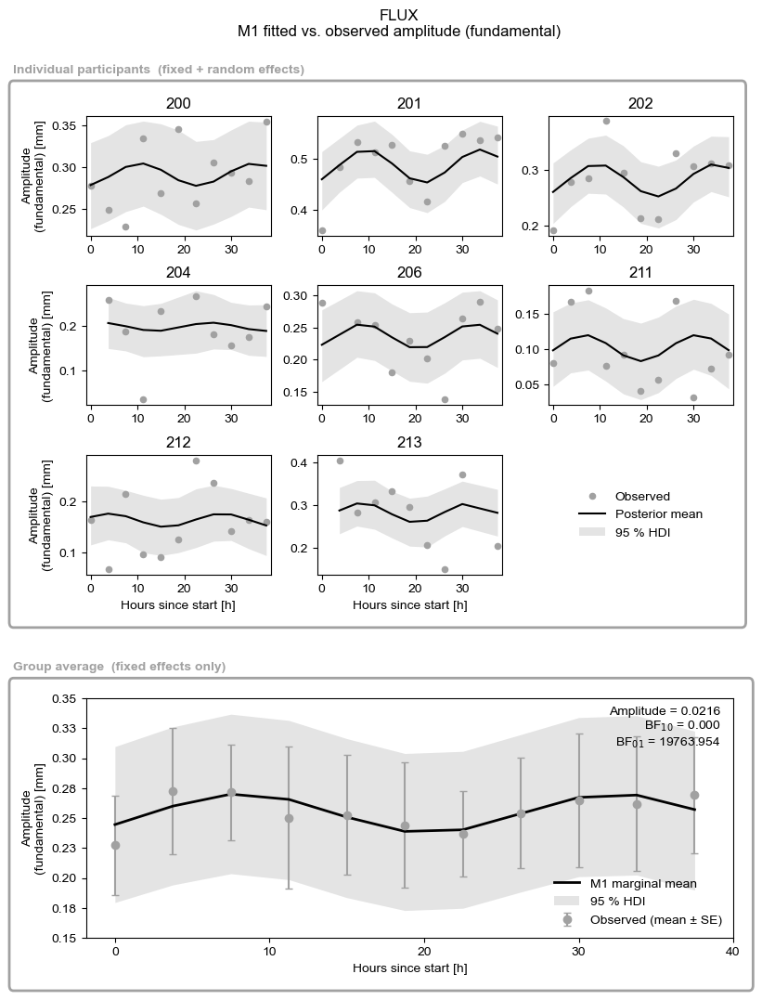

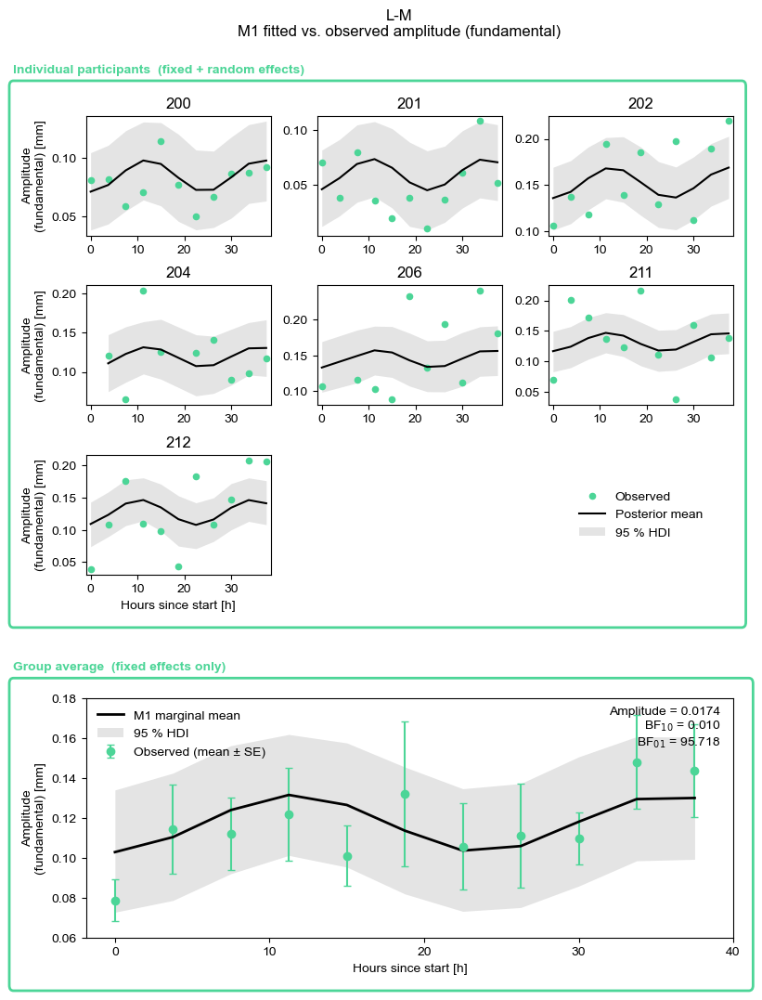

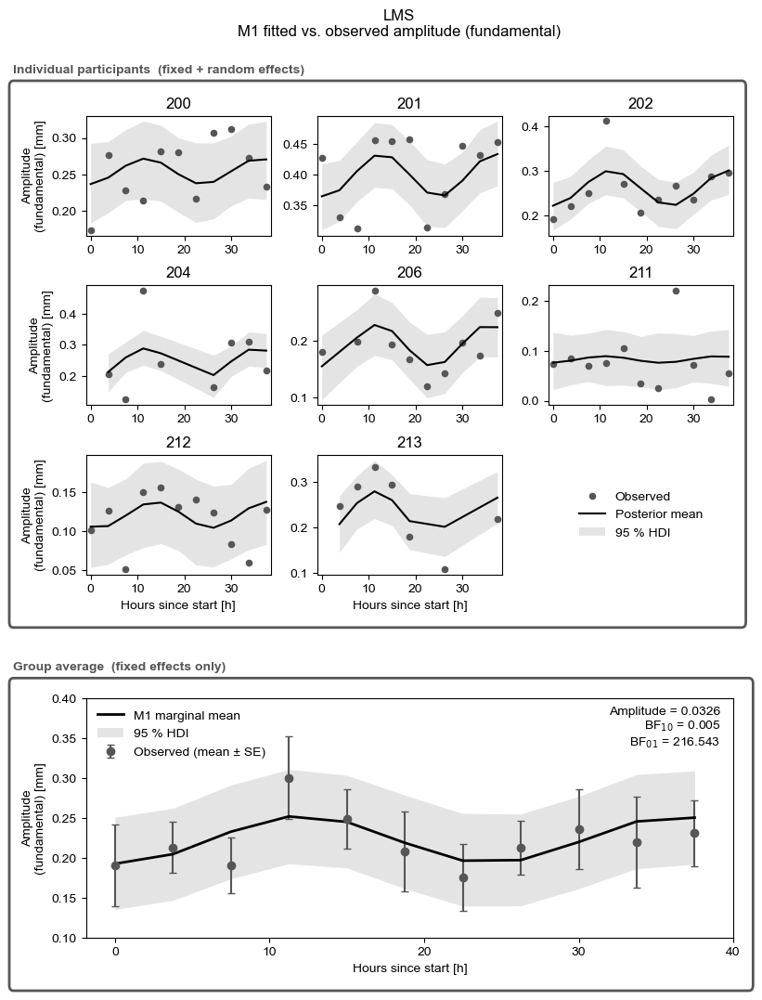

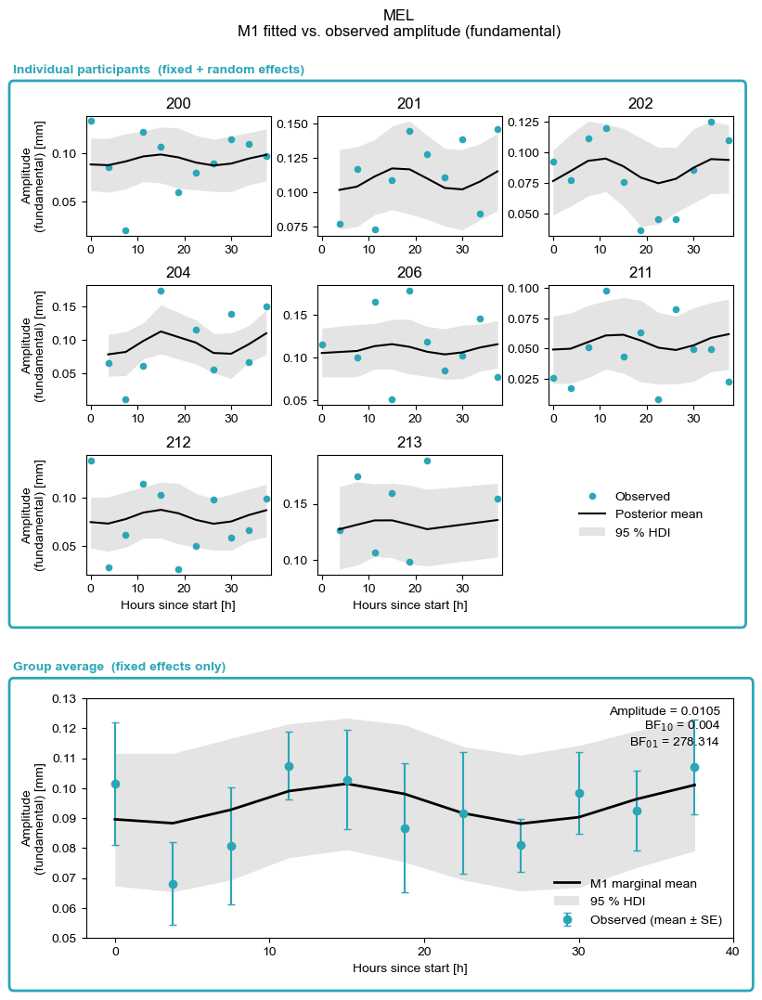

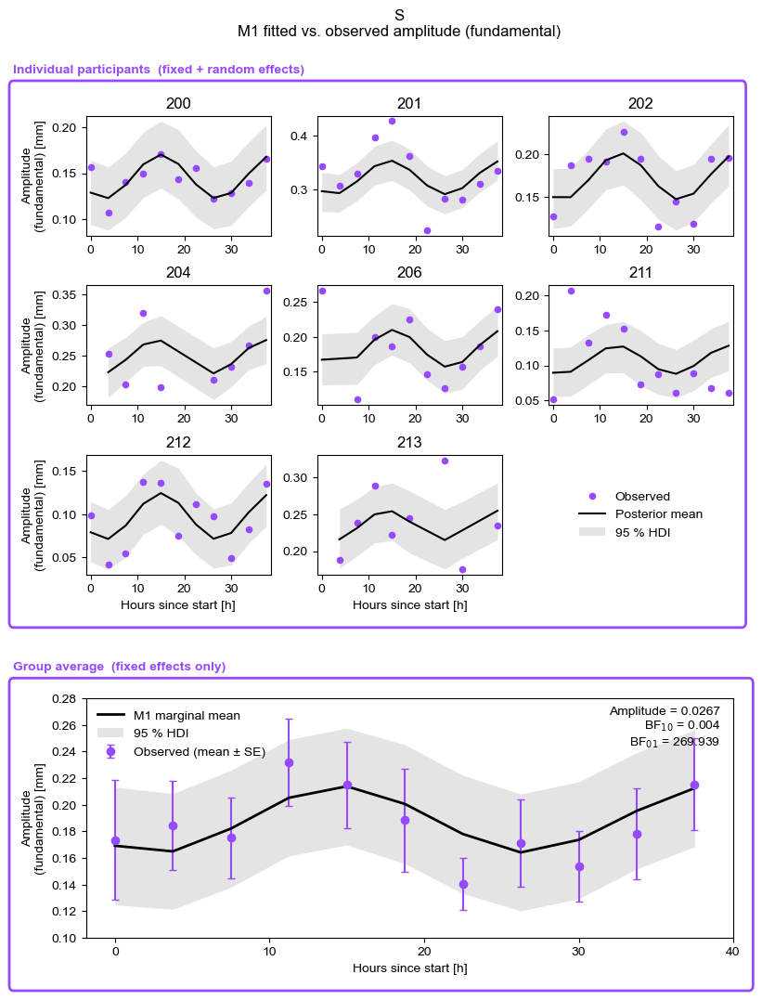

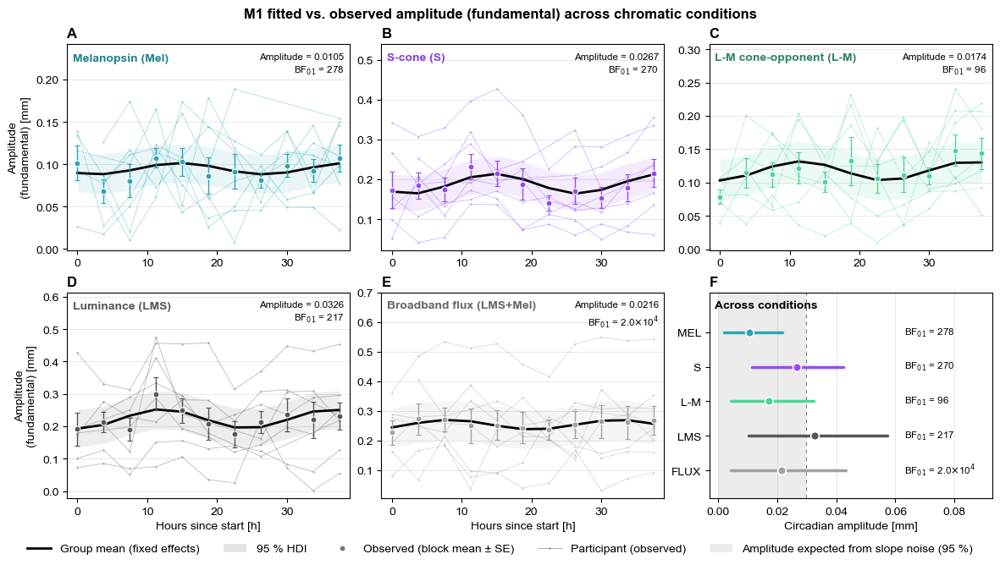

In [23]:
visualise_circadian(outcome_col="amplitude")

#### Conclusion: the constant-level model is favoured in every condition

- log10 BF10 ranges from -3.36 (flux) to -1.10 (S), so the evidence favours no circadian modulation of phasic amplitude in all five conditions.
- The cosine slope interval excludes zero for LMS and S, but these single terms do not outweigh the model comparison.
- Sampling is fine (R-hat <= 1.003). Residual normality is borderline for L-M, LMS and S (Shapiro p = 0.025-0.050). The Bayes factor is least precise for LMS and S (SD/|dlogZ| about 0.11-0.12), without changing its sign.

## Outcome: log_amplitude_2f (exploratory)

Log-transformed phasic amplitude at the second harmonic (0.8 Hz = 2 x 0.4 Hz). A second-harmonic component indicates that the pupil response is not a pure sinusoid at the stimulus frequency, for example when constriction and dilation are asymmetric.

**Out:** `results/tables/circadian_cosinor/log_amplitude_2f/`, `results/figures/circadian_cosinor/log_amplitude_2f/`, `results/{tables,figures}/circadian_cosinor_diagnostics/log_amplitude_2f/`

### Step 4b -- Inspect distributions: log_amplitude_2f

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'log_amplitude_2f'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83   -3.267    0.766   -0.785    1.254   0.9561   0.0064  NO
l-m             74   -2.347    0.453   -0.713    2.632   0.9456   0.0031  NO
lms             80   -3.019    0.697   -0.439    0.633   0.9655   0.0296  NO
mel             80   -3.201    0.842   -0.725    0.284   0.9527   0.0049  NO
s               81   -2.976    0.823   -1.962    5.617   0.8354   0.0000  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_log_amplitude_2f.png


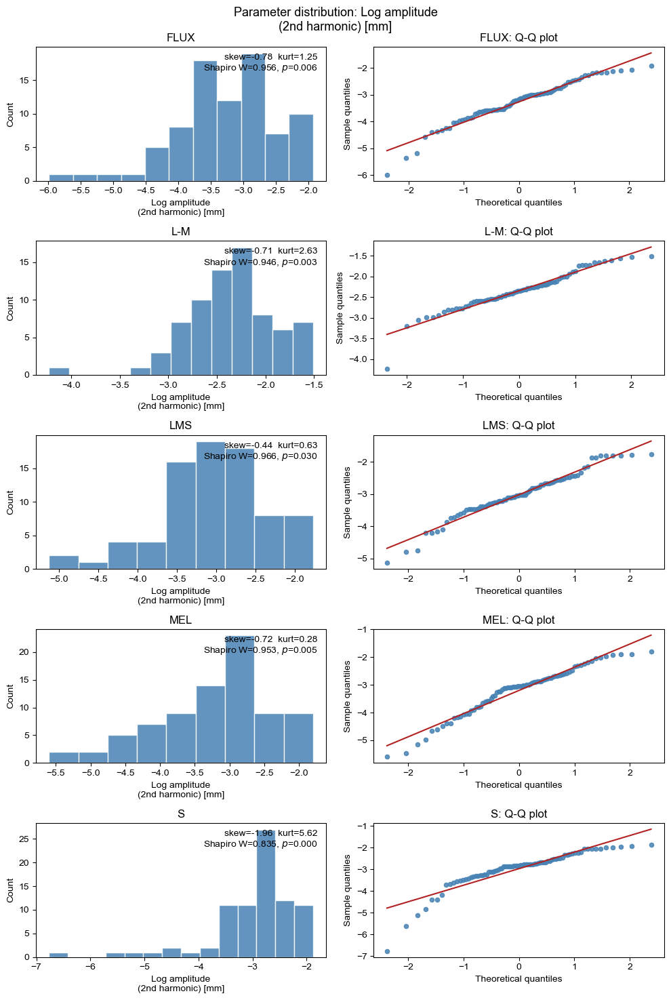

In [24]:
inspect_model(outcome_col="log_amplitude_2f")

### Step 5 -- Analyse circadian parameters: log_amplitude_2f

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'log_amplitude_2f'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83   -3.267    0.766   -0.785    1.254   0.9561   0.0064  NO
l-m             74   -2.347    0.453   -0.713    2.632   0.9456   0.0031  NO
lms             80   -3.019    0.697   -0.439    0.633   0.9655   0.0296  NO
mel             80   -3.201    0.842   -0.725    0.284   0.9527   0.0049  NO
s               81   -2.976    0.823   -1.962    5.617   0.8354   0.0000  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_log_amplitude_2f.png

Analysis dataframe: 398 rows
 participant_id Trial type  Block  hours_since_start  amplitude  log_amplitude     alpha      beta  

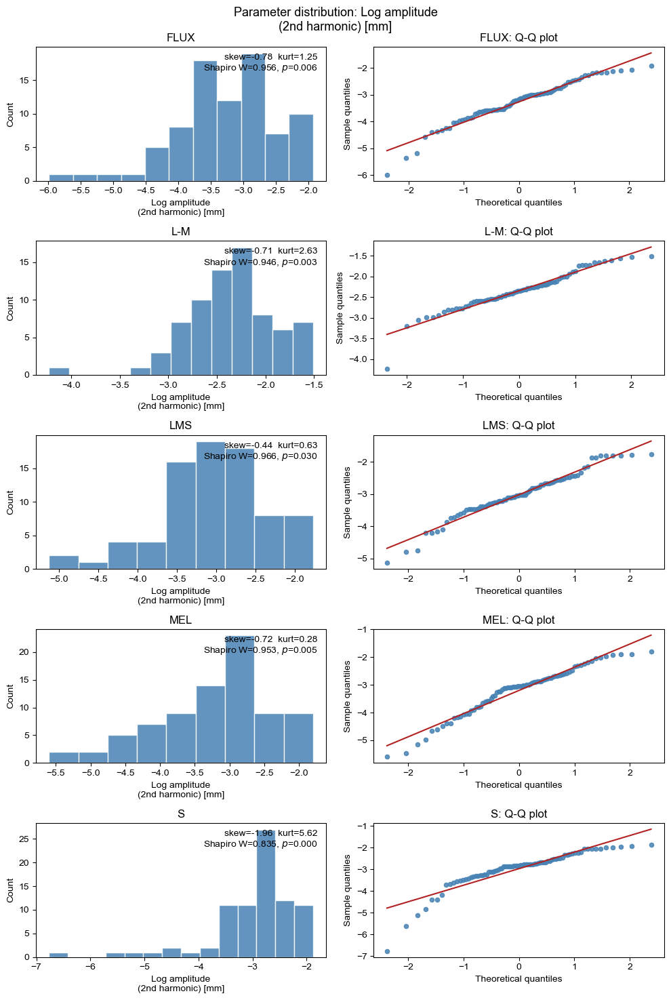

In [25]:
df_circadian_log_amplitude_2f, circadian_results["log_amplitude_2f"] = analyse_circadian(
    outcome_parameter="log_amplitude_2f",
    force=FORCE,
    dry_run=DRY_RUN,
    smc_draws=SMC_DRAWS,
    random_seed=SEED,
)

### Step 5b -- Diagnose circadian models: log_amplitude_2f

Auto-detected conditions: ['flux', 'l-m', 'lms', 'mel', 's']

── Condition: FLUX ──────────────────
  Bayesian p-value: p_B(mean)=0.439  p_B(SD)=0.623
  Saved: posterior_params_flux.csv
  r_hat  M0 max=1.0010  M1 max=1.0022
  Saved: fig_log_amplitude_2f_diagnostics_flux.png

── Condition: L-M ──────────────────
  Bayesian p-value: p_B(mean)=0.487  p_B(SD)=0.593
  Saved: posterior_params_l-m.csv
  r_hat  M0 max=1.0011  M1 max=1.0087
  Saved: fig_log_amplitude_2f_diagnostics_l-m.png

── Condition: LMS ──────────────────
  Bayesian p-value: p_B(mean)=0.477  p_B(SD)=0.581
  Saved: posterior_params_lms.csv
  r_hat  M0 max=1.0023  M1 max=1.0017
  Saved: fig_log_amplitude_2f_diagnostics_lms.png

── Condition: MEL ──────────────────
  Bayesian p-value: p_B(mean)=0.582  p_B(SD)=0.580
  Saved: posterior_params_mel.csv
  r_hat  M0 max=1.0023  M1 max=1.0018
  Saved: fig_log_amplitude_2f_diagnostics_mel.png

── Condition: S ──────────────────
  Bayesian p-value: p_B(mean)=0.533  p_B(SD)=0.585
  Sav

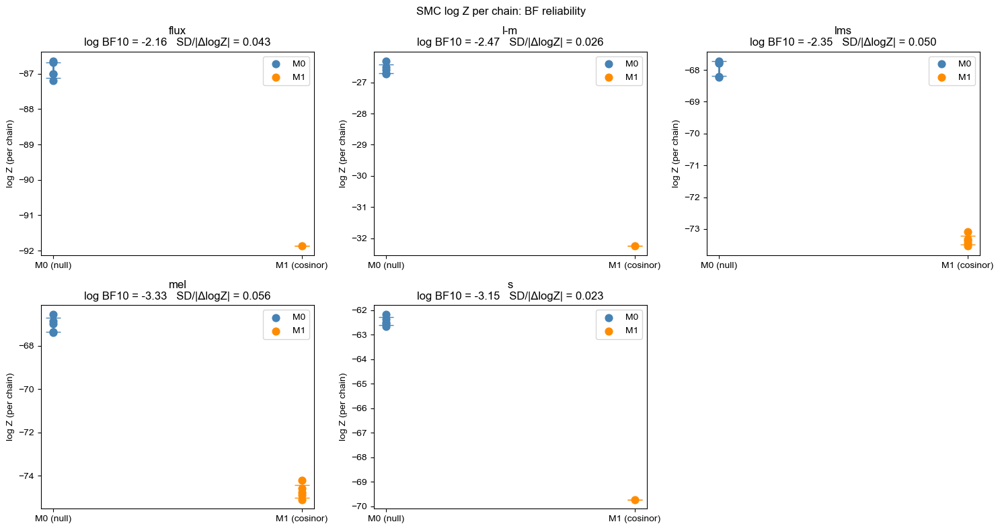

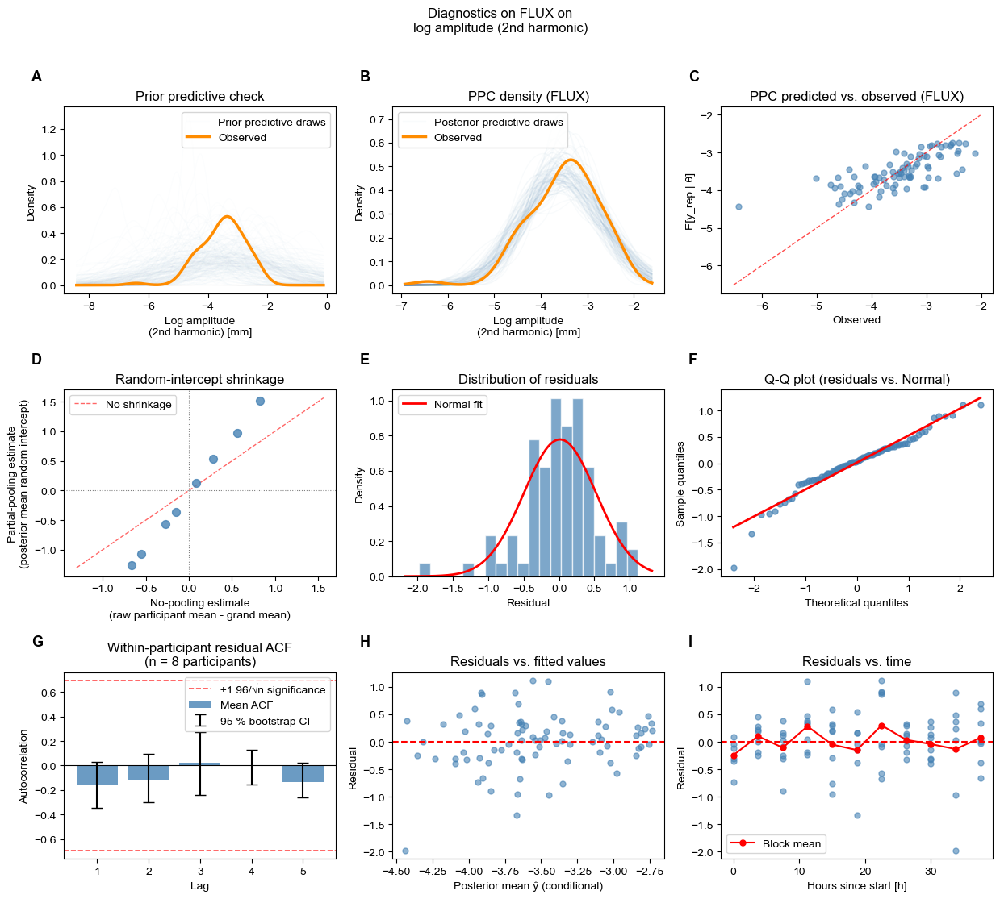

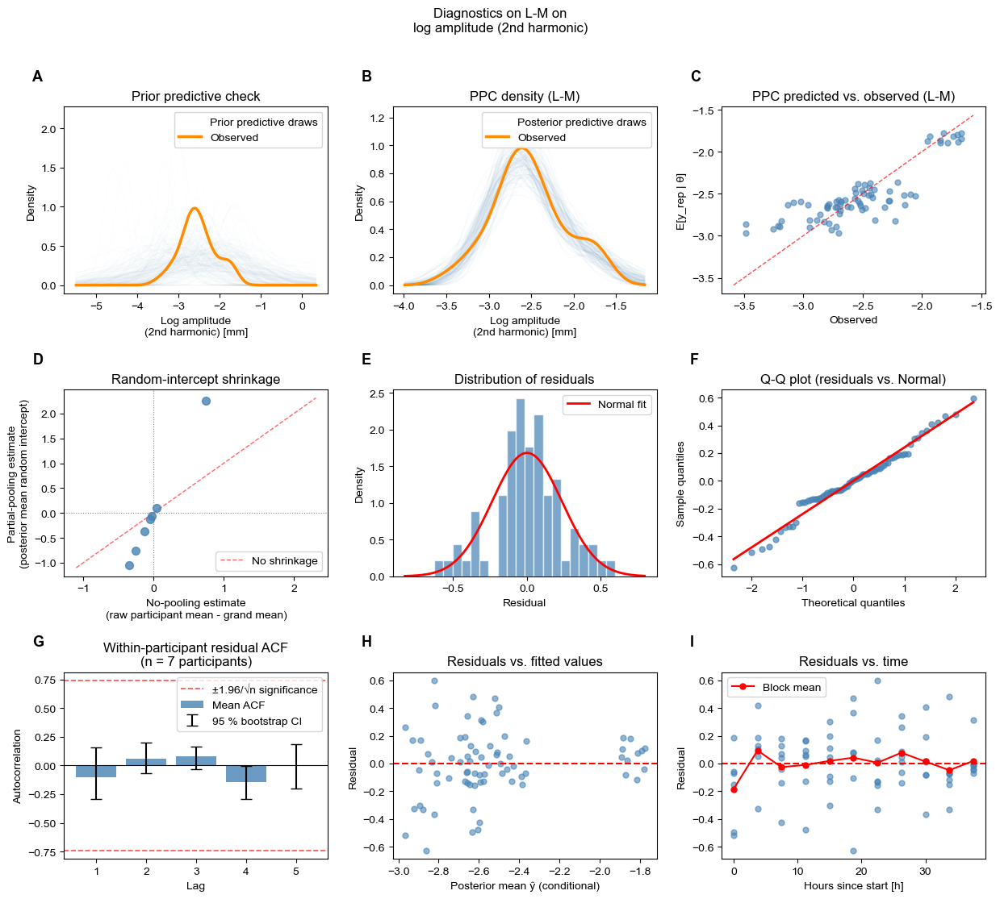

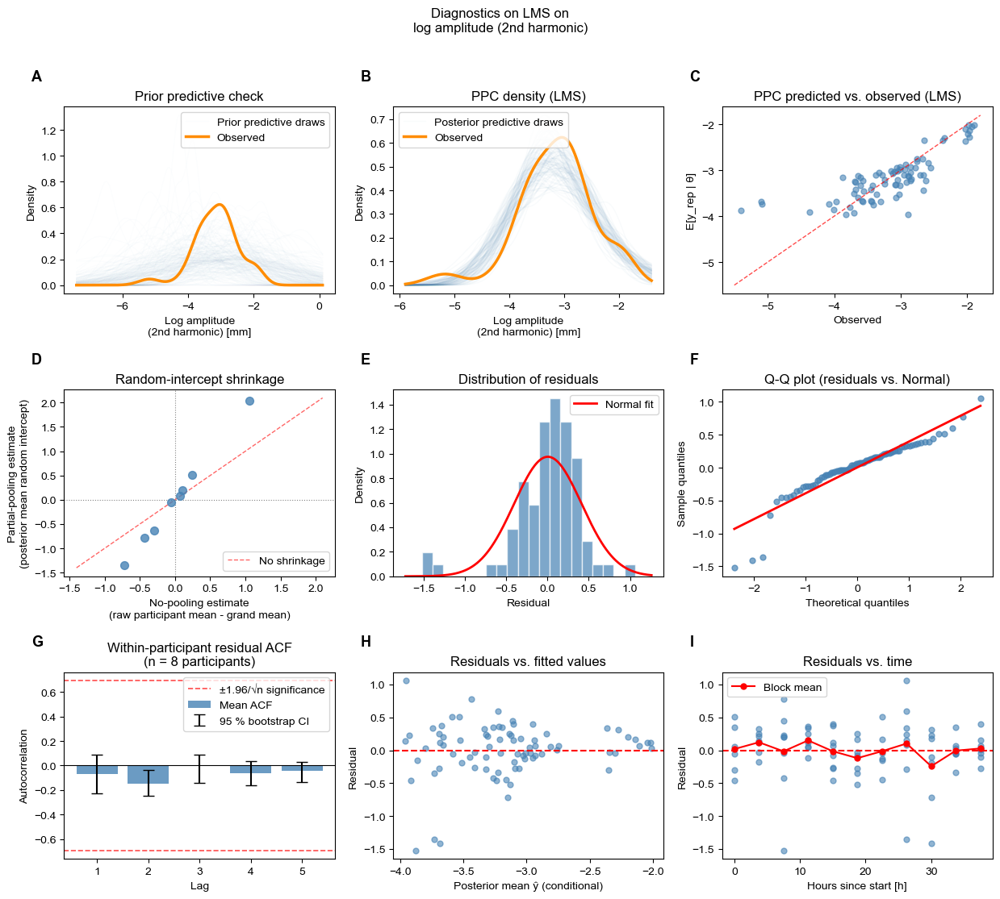

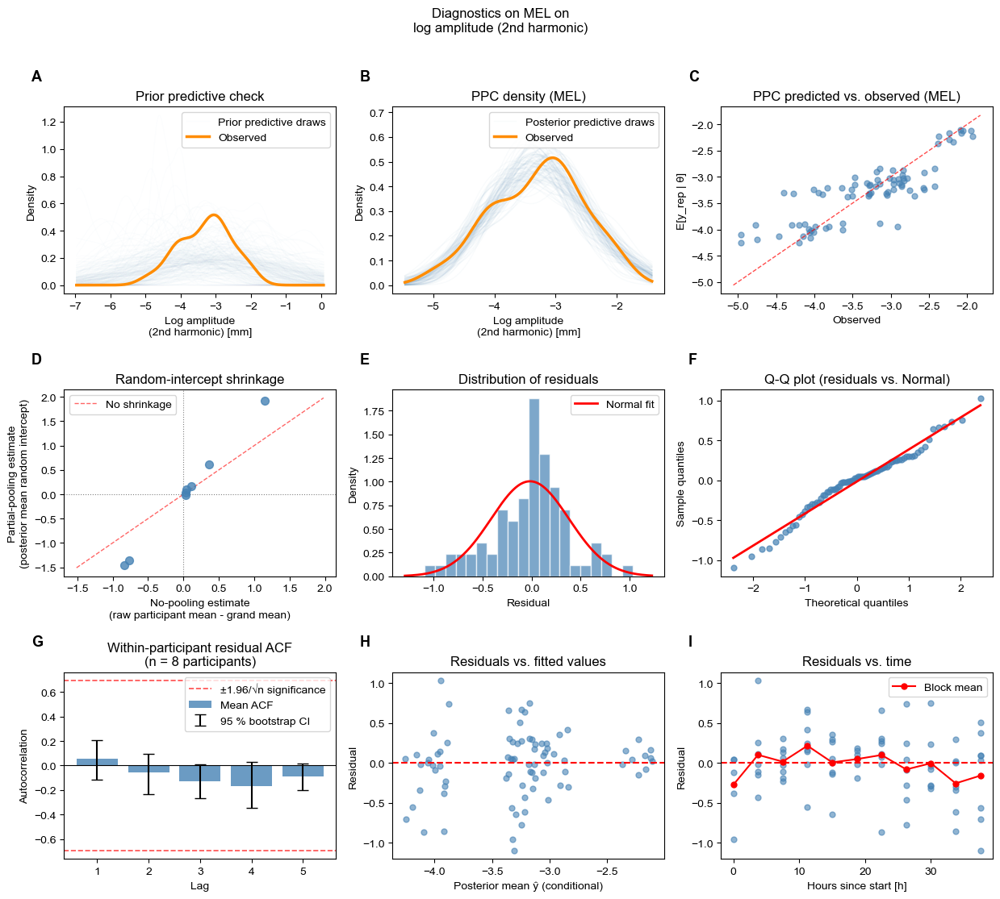

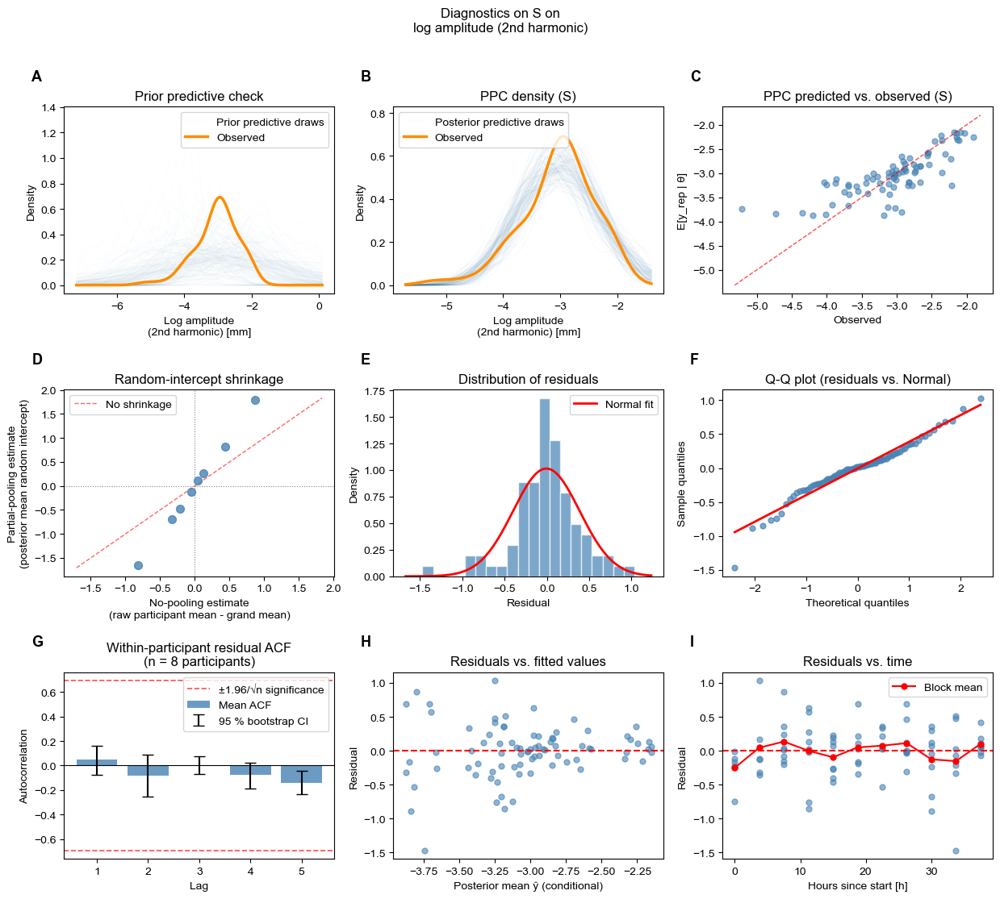

In [26]:
circadian_diag_results["log_amplitude_2f"] = diagnose_circadian(parameter_col="log_amplitude_2f")

### Step 5c -- Visualise circadian fits: log_amplitude_2f


── Condition: FLUX ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/log_amplitude_2f/fig_fitted_vs_empirical_flux.png

── Condition: L-M ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/log_amplitude_2f/fig_fitted_vs_empirical_l-m.png

── Condition: LMS ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/log_amplitude_2f/fig_fitted_vs_empirical_lms.png

── Condition: MEL ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/log_amplitude_2f/fig_fitted_vs_empirical_mel.png

── Condition: S ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/log_amplitude_2f/fig_fitted_vs_empirical_s.png

── All conditions ──────────────────
  Saved: /Users/hheinrichs/Do

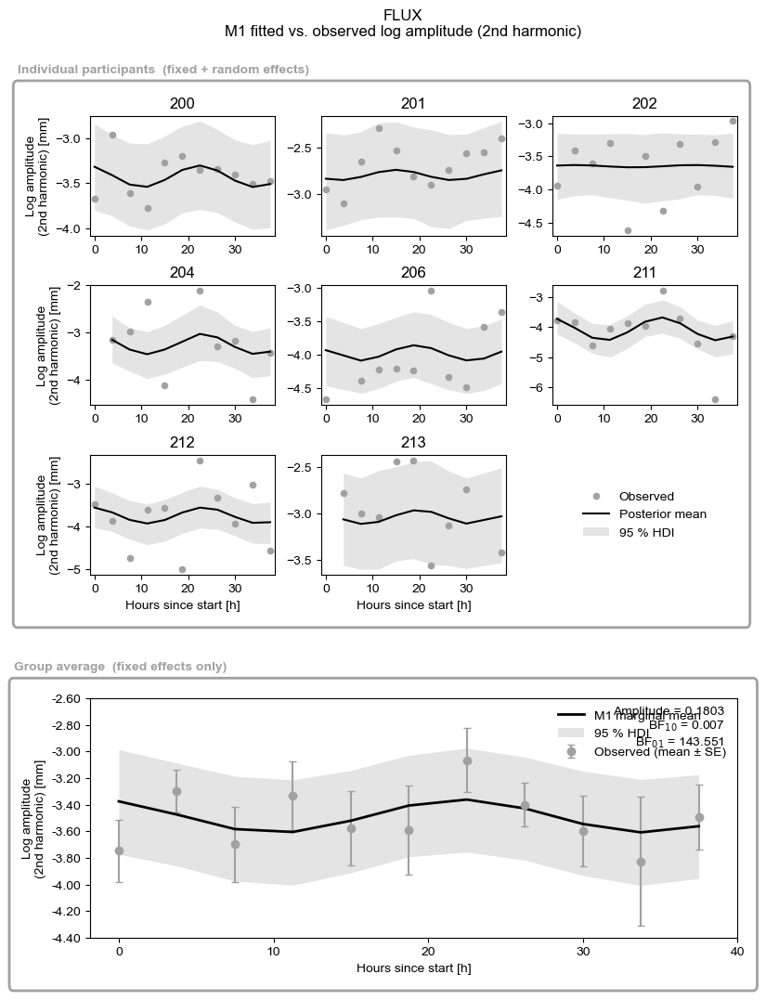

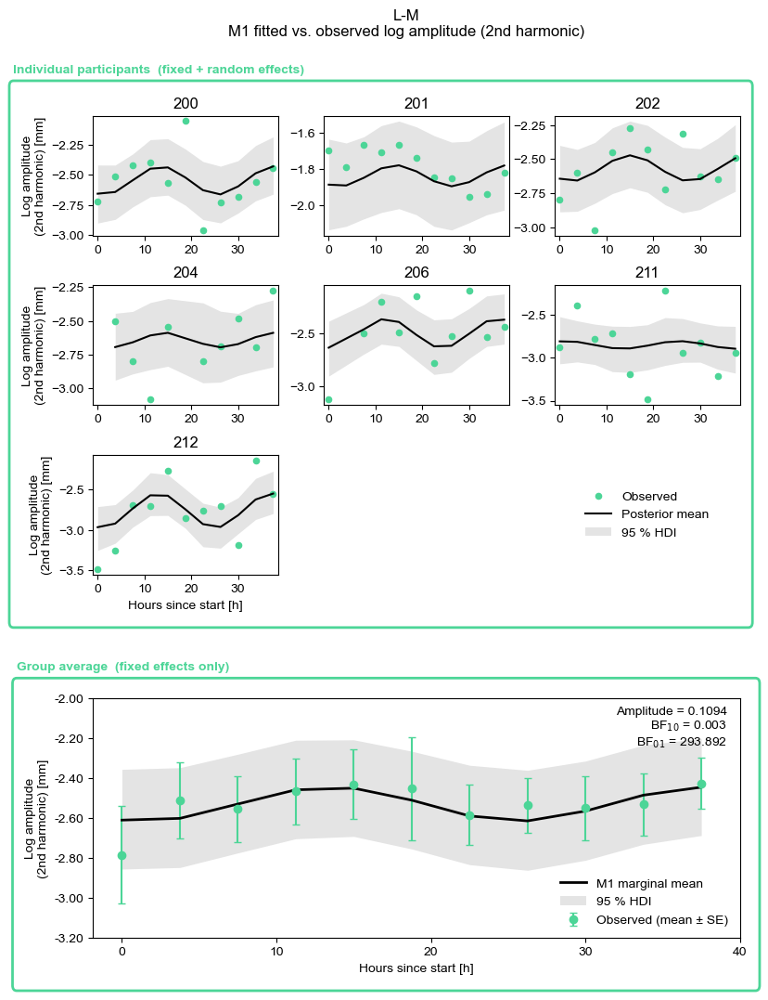

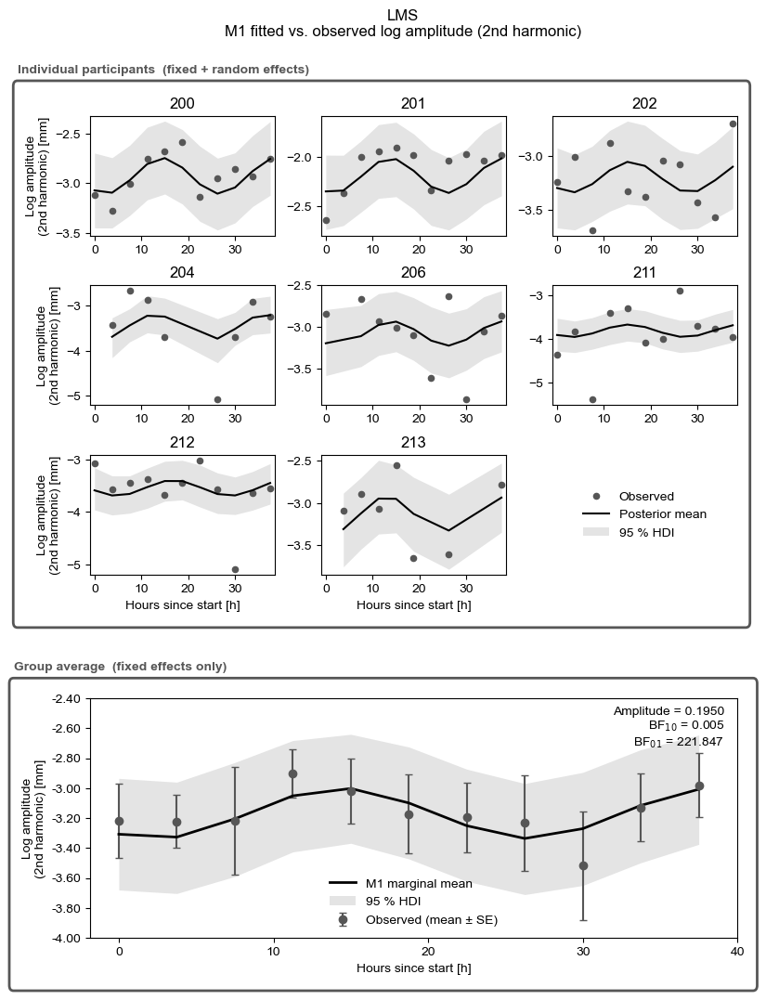

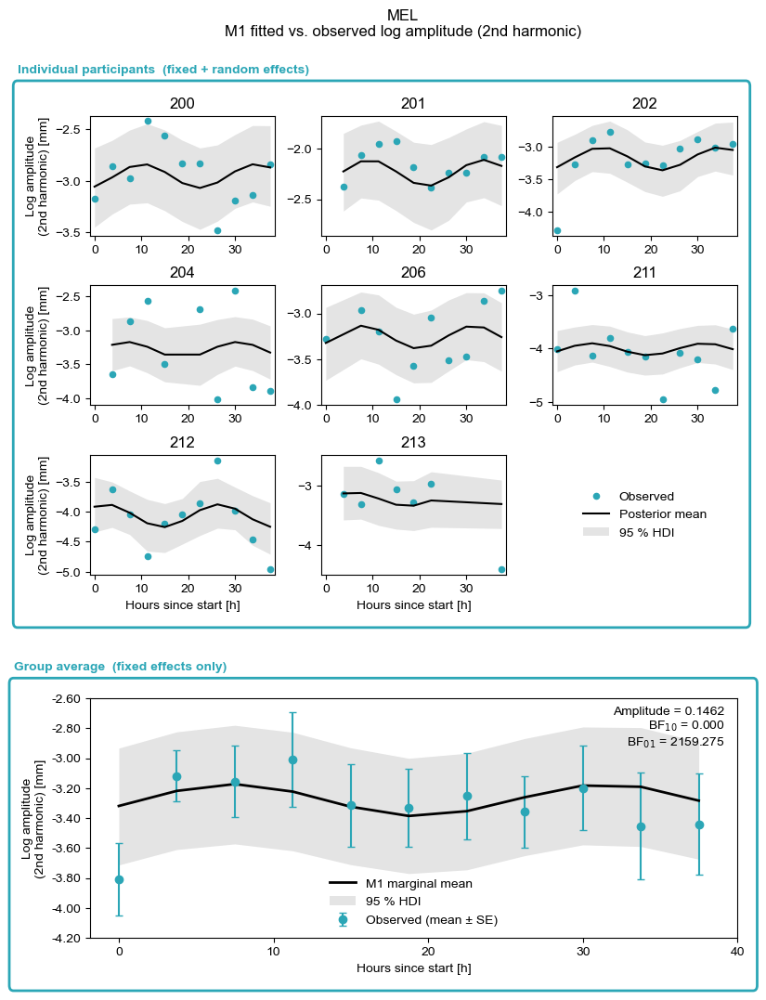

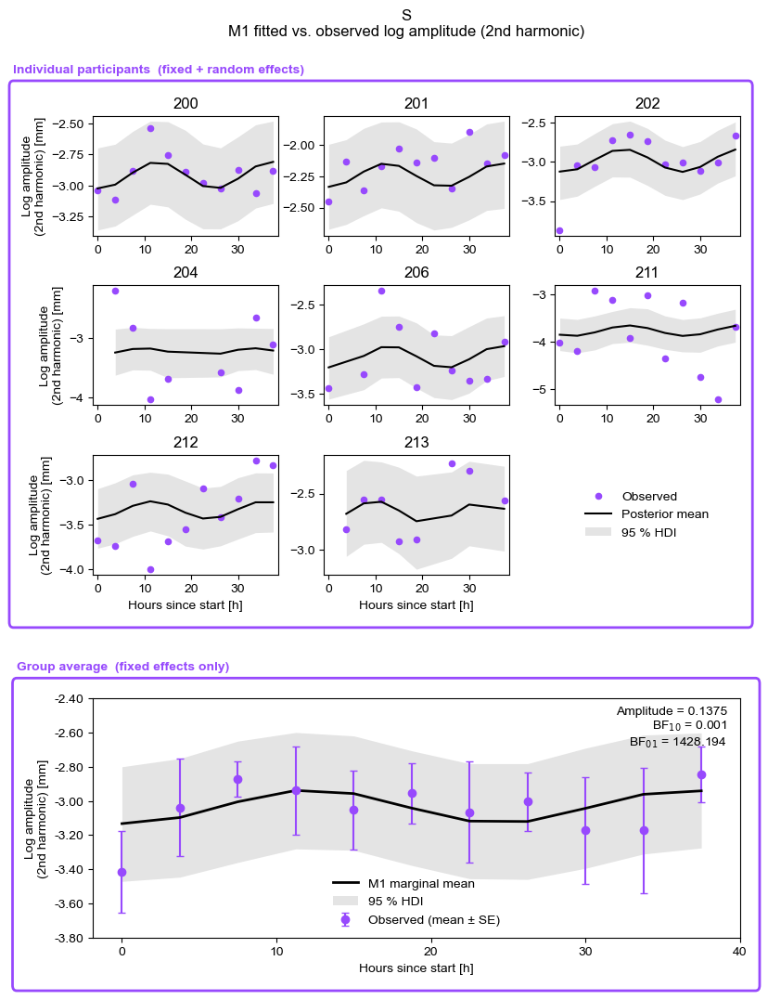

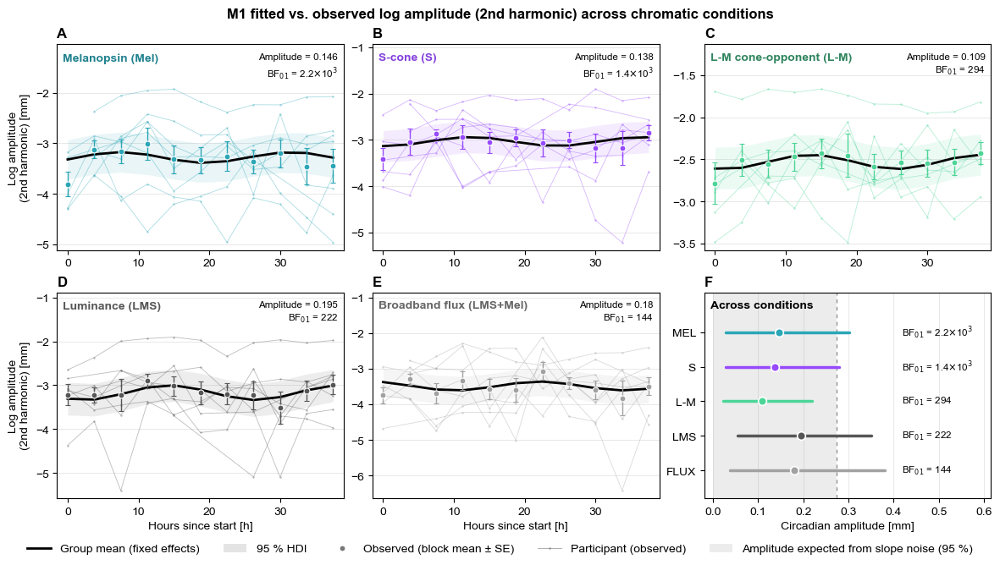

In [27]:
visualise_circadian(outcome_col="log_amplitude_2f")

## Outcome: phase (exploratory)

Phase of the phasic response at the stimulus frequency (0.4 Hz), in radians. It reflects the timing of the pupil oscillation relative to the stimulus cycle; a circadian change would mean this timing varies across the protocol.

**Out:** `results/tables/circadian_cosinor/phase/`, `results/figures/circadian_cosinor/phase/`, `results/{tables,figures}/circadian_cosinor_diagnostics/phase/`

### Step 4b -- Inspect distributions: phase

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'phase'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83    1.189    0.375   -0.220    5.908   0.8940   0.0000  NO
l-m             74    0.834    1.116   -1.425    1.287   0.8201   0.0000  NO
lms             80    1.325    0.414   -0.423    1.899   0.9626   0.0194  NO
mel             80    1.028    0.857   -1.145    3.720   0.9216   0.0001  NO
s               81    1.518    0.382   -0.334    0.686   0.9776   0.1676  yes

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_phase.png


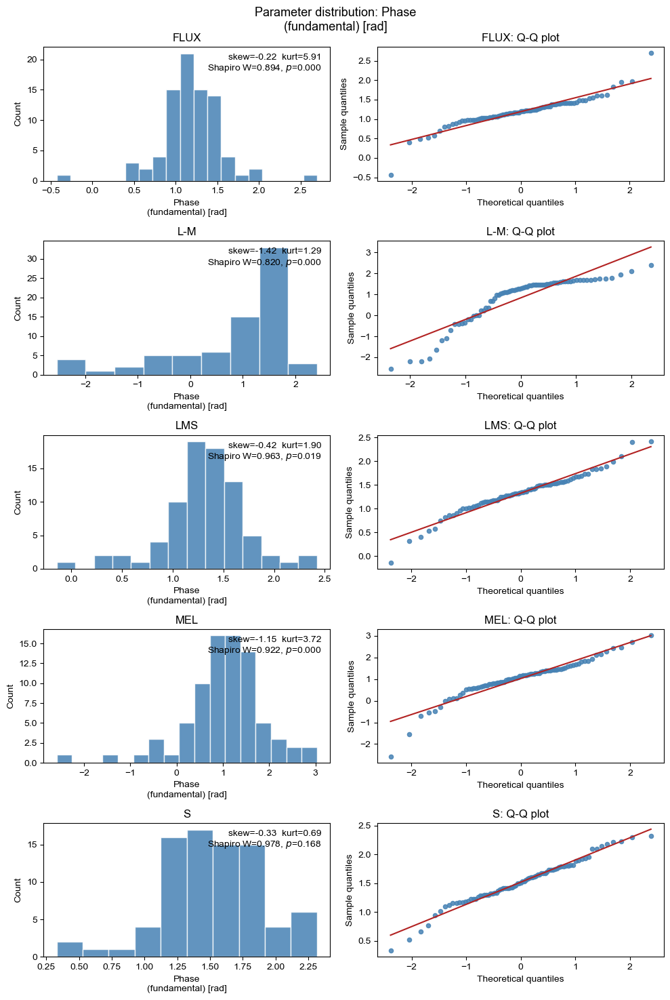

In [28]:
inspect_model(outcome_col="phase")

### Step 5 -- Analyse circadian parameters: phase

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'phase'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83    1.189    0.375   -0.220    5.908   0.8940   0.0000  NO
l-m             74    0.834    1.116   -1.425    1.287   0.8201   0.0000  NO
lms             80    1.325    0.414   -0.423    1.899   0.9626   0.0194  NO
mel             80    1.028    0.857   -1.145    3.720   0.9216   0.0001  NO
s               81    1.518    0.382   -0.334    0.686   0.9776   0.1676  yes

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_phase.png

Analysis dataframe: 398 rows
 participant_id Trial type  Block  hours_since_start  amplitude  log_amplitude     alpha      beta  saliva_tau_hours
    

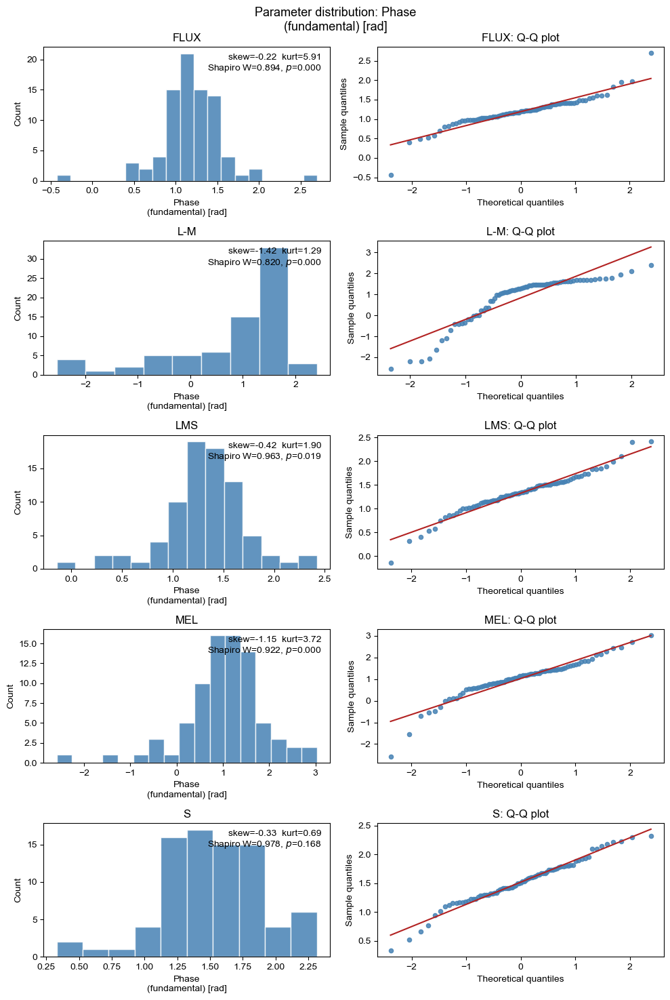

In [29]:
df_circadian_phase, circadian_results["phase"] = analyse_circadian(
    outcome_parameter="phase",
    force=FORCE,
    dry_run=DRY_RUN,
    smc_draws=SMC_DRAWS,
    random_seed=SEED,
)

### Step 5b -- Diagnose circadian models: phase

Auto-detected conditions: ['flux', 'l-m', 'lms', 'mel', 's']

── Condition: FLUX ──────────────────
  Bayesian p-value: p_B(mean)=0.507  p_B(SD)=0.653
  Saved: posterior_params_flux.csv
  r_hat  M0 max=1.0022  M1 max=1.0012
  Saved: fig_phase_diagnostics_flux.png

── Condition: L-M ──────────────────
  Bayesian p-value: p_B(mean)=0.487  p_B(SD)=0.591
  Saved: posterior_params_l-m.csv
  r_hat  M0 max=1.0017  M1 max=1.0034
  Saved: fig_phase_diagnostics_l-m.png

── Condition: LMS ──────────────────
  Bayesian p-value: p_B(mean)=0.497  p_B(SD)=0.621
  Saved: posterior_params_lms.csv
  r_hat  M0 max=1.0013  M1 max=1.0021
  Saved: fig_phase_diagnostics_lms.png

── Condition: MEL ──────────────────
  Bayesian p-value: p_B(mean)=0.563  p_B(SD)=0.665
  Saved: posterior_params_mel.csv
  r_hat  M0 max=1.0057  M1 max=1.0024
  Saved: fig_phase_diagnostics_mel.png

── Condition: S ──────────────────
  Bayesian p-value: p_B(mean)=0.386  p_B(SD)=0.598
  Saved: posterior_params_s.csv
  r_hat  M0 max=1

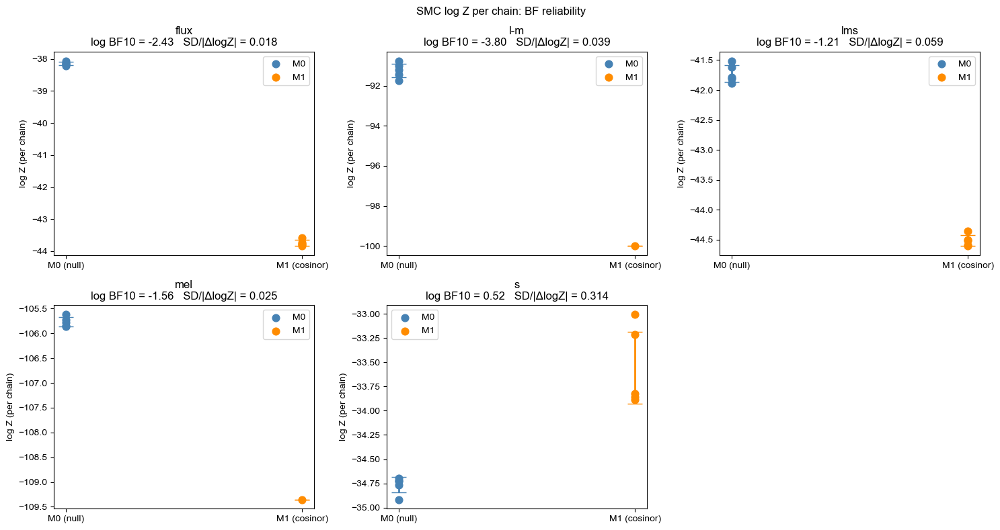

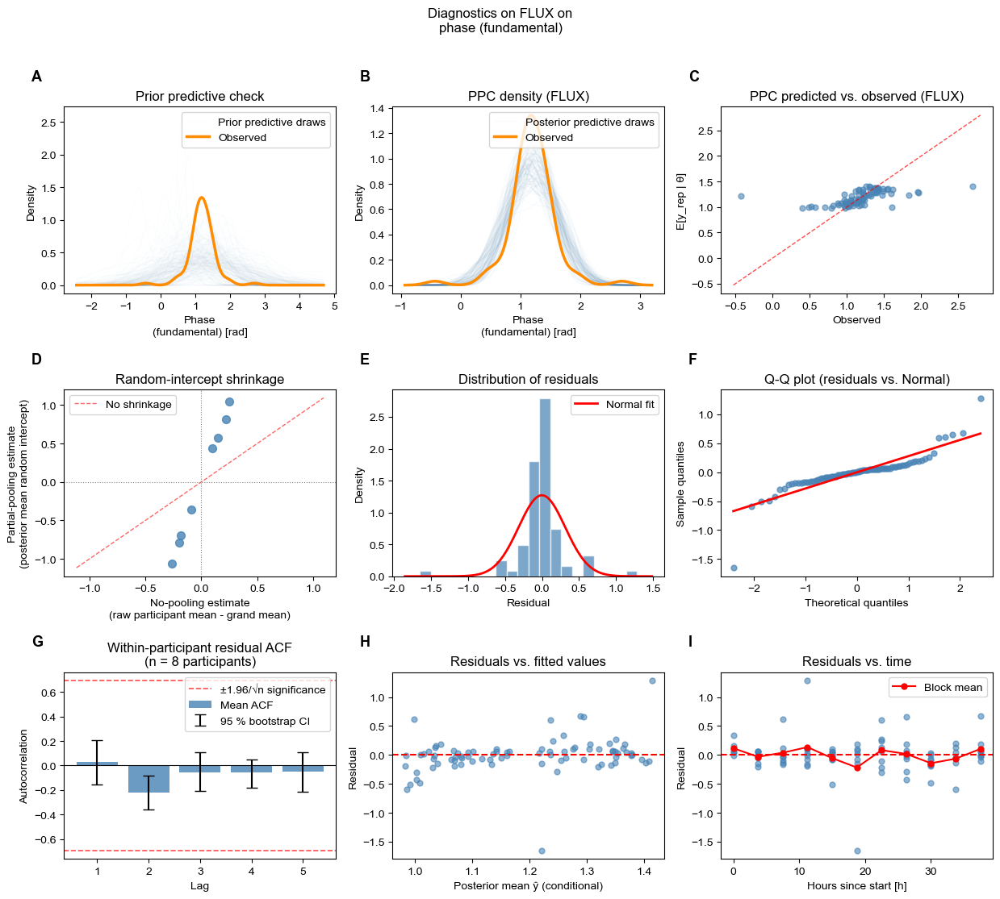

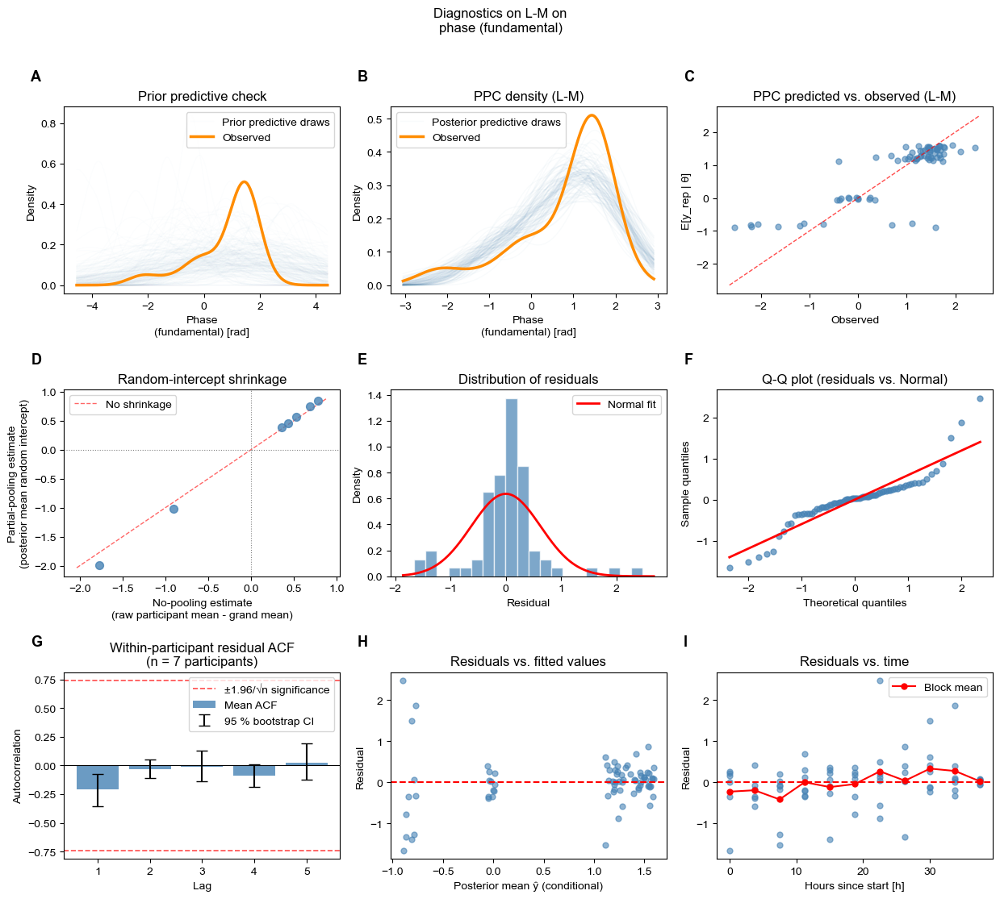

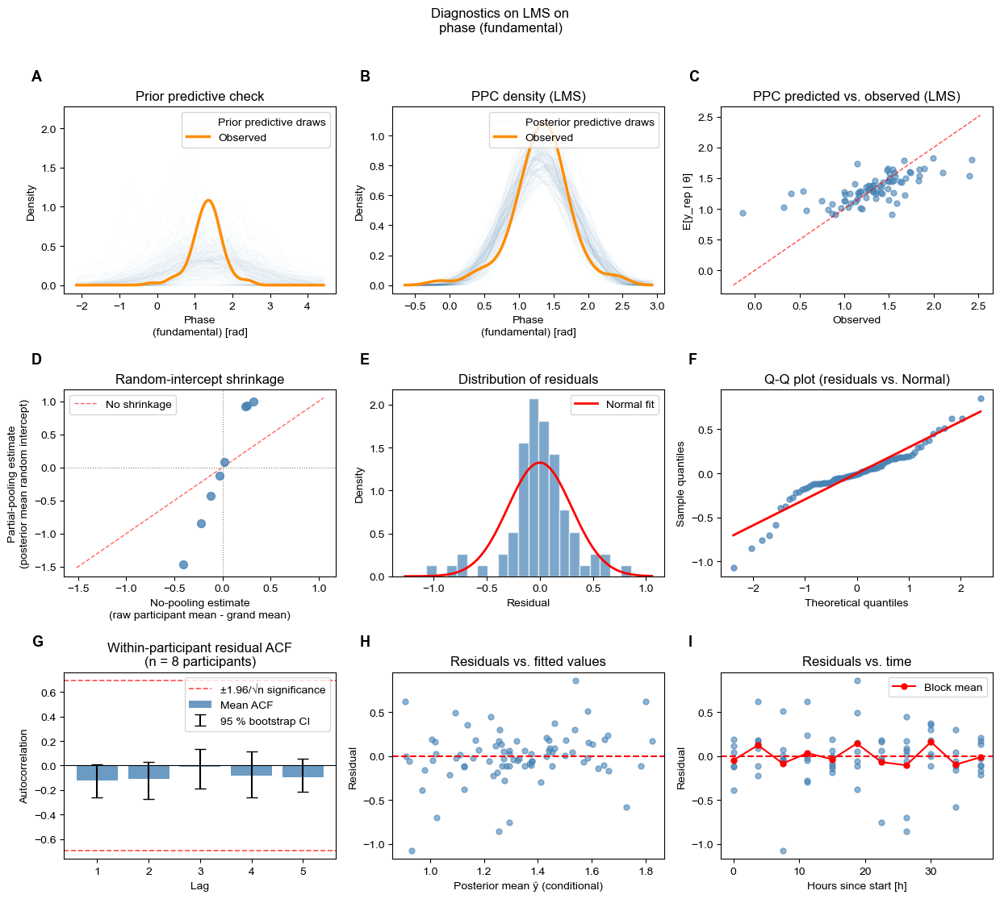

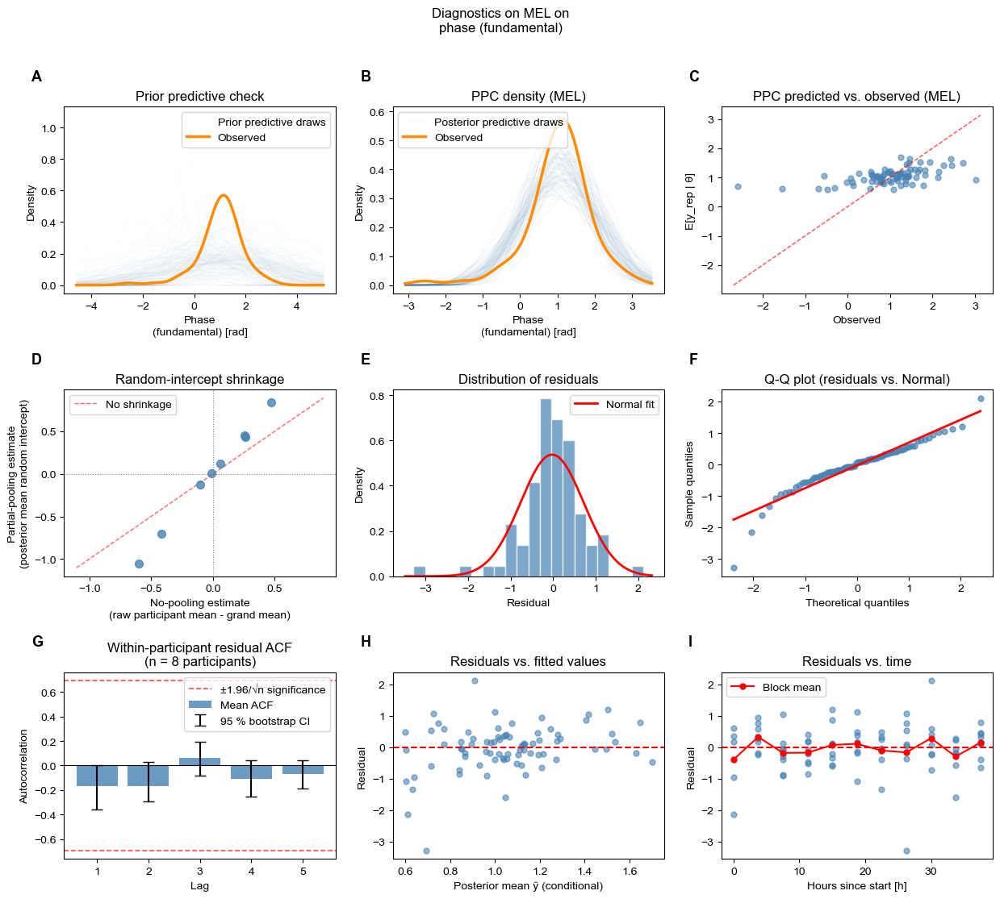

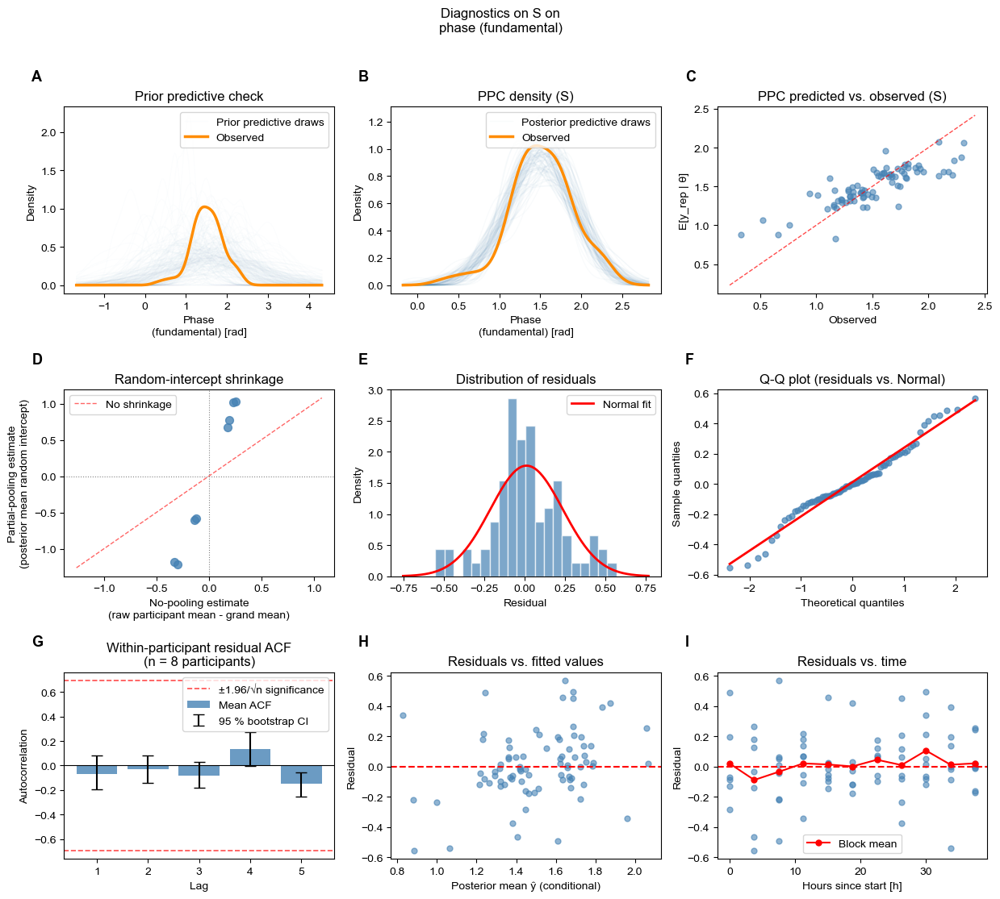

In [30]:
circadian_diag_results["phase"] = diagnose_circadian(parameter_col="phase")

### Step 5c -- Visualise circadian fits: phase


── Condition: FLUX ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase/fig_fitted_vs_empirical_flux.png

── Condition: L-M ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase/fig_fitted_vs_empirical_l-m.png

── Condition: LMS ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase/fig_fitted_vs_empirical_lms.png

── Condition: MEL ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase/fig_fitted_vs_empirical_mel.png

── Condition: S ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase/fig_fitted_vs_empirical_s.png

── All conditions ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/ci

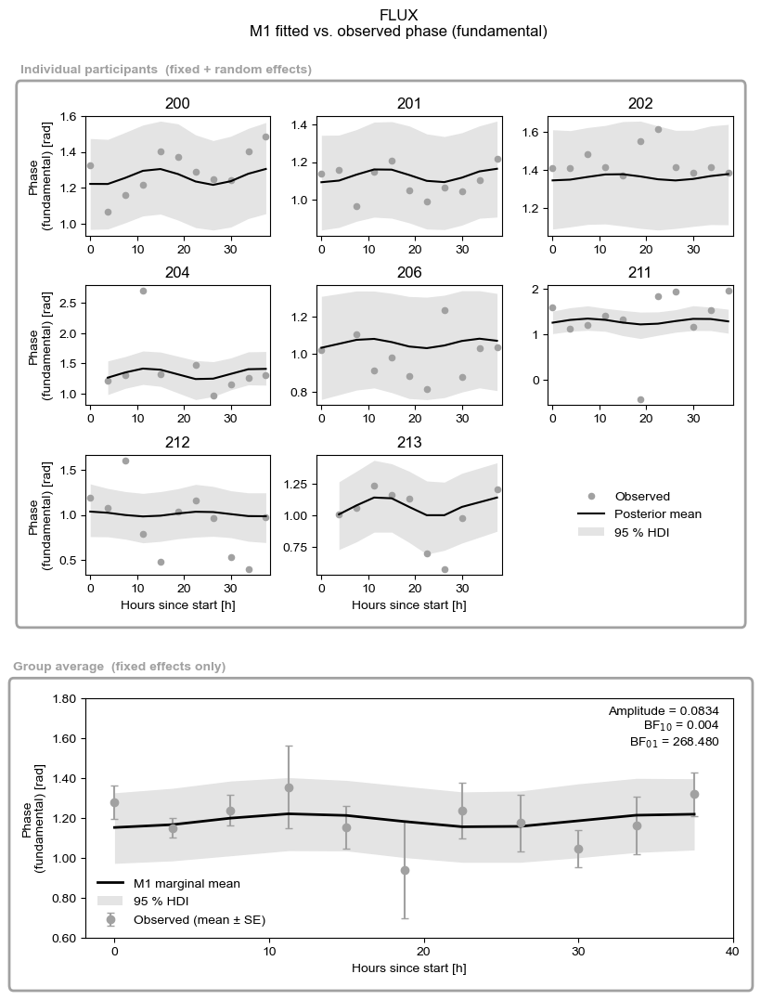

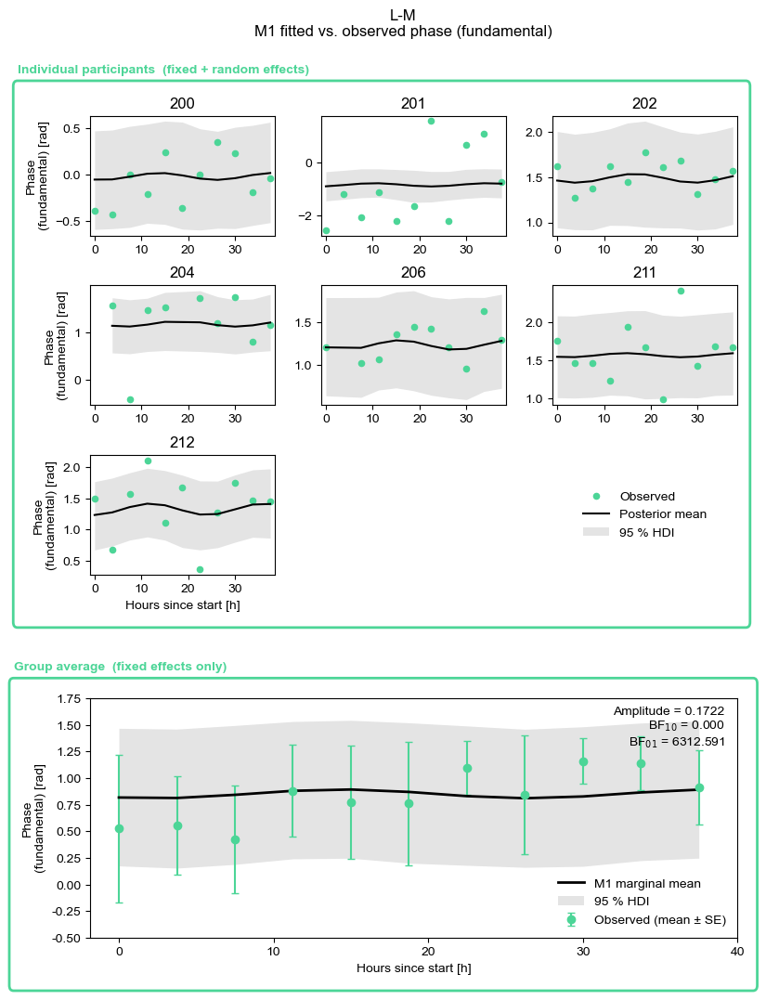

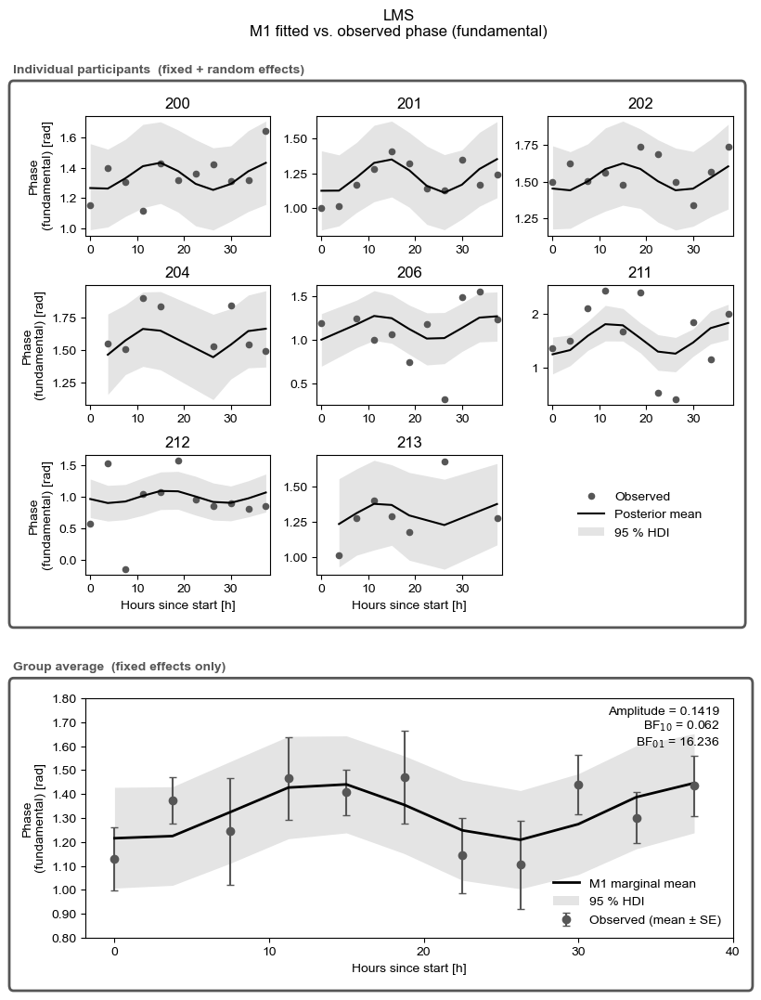

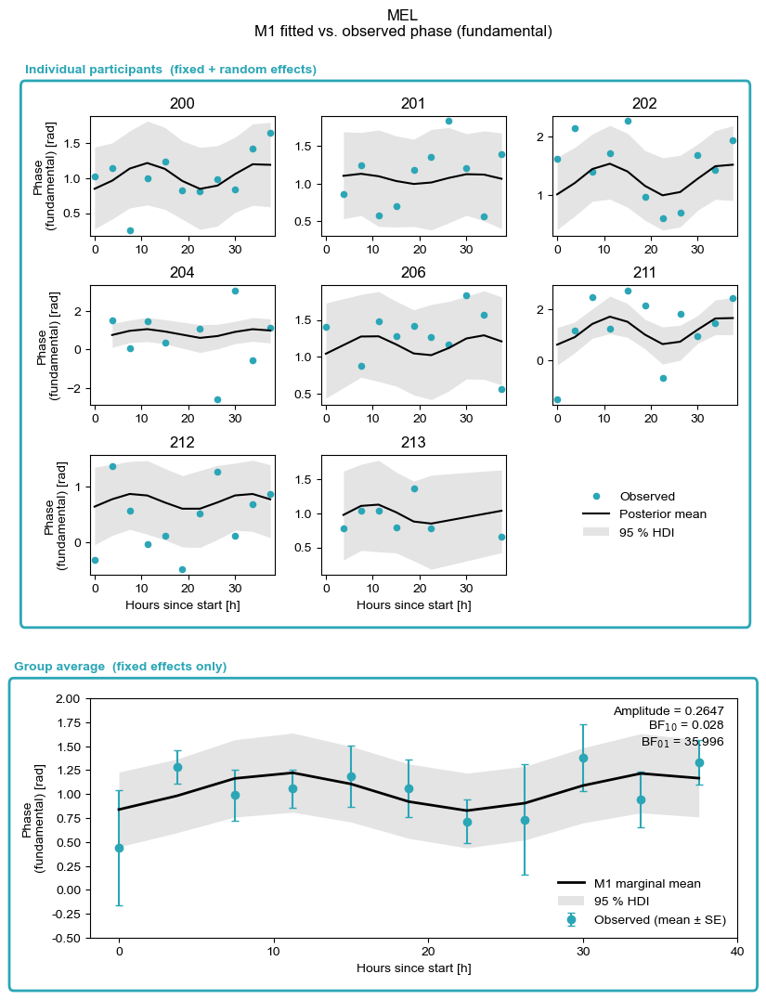

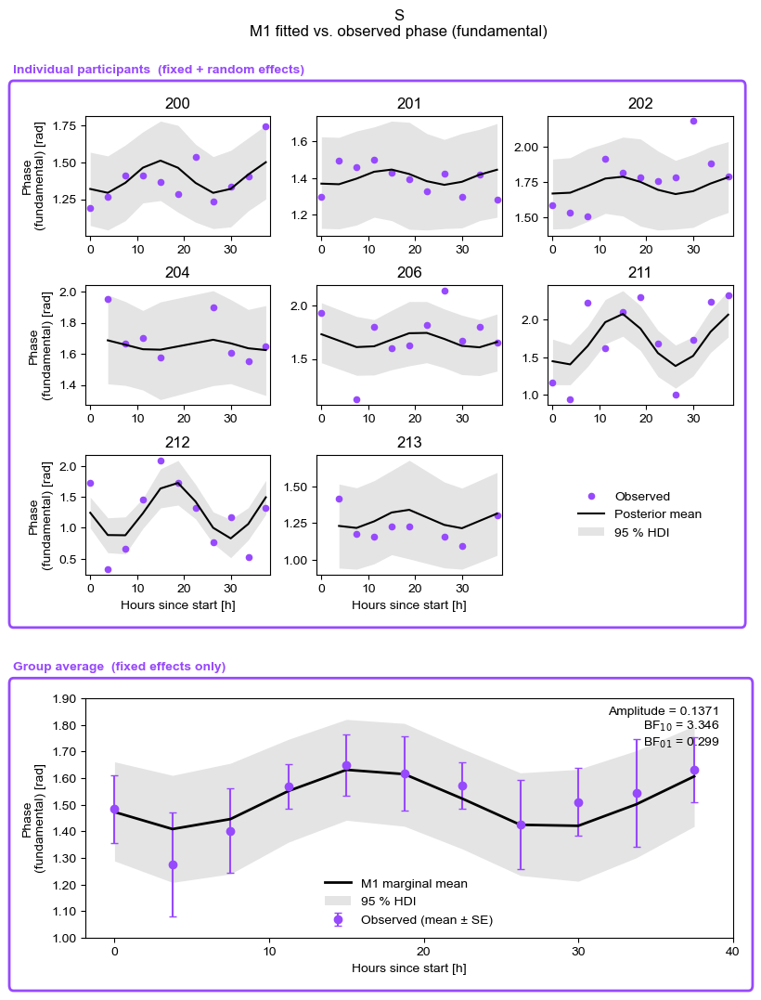

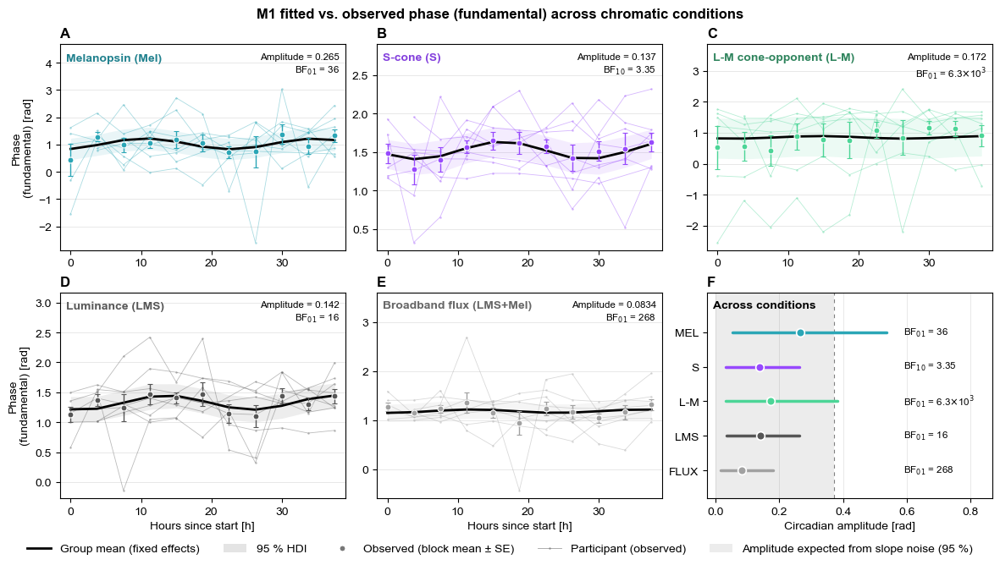

In [31]:
visualise_circadian(outcome_col="phase")

## Outcome: phase_2f (exploratory)

Phase of the second-harmonic component (0.8 Hz), in radians. Together with `phase`, it describes the waveform shape of the pupil oscillation.

**Out:** `results/tables/circadian_cosinor/phase_2f/`, `results/figures/circadian_cosinor/phase_2f/`, `results/{tables,figures}/circadian_cosinor_diagnostics/phase_2f/`

### Step 4b -- Inspect distributions: phase_2f

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'phase_2f'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83   -1.468    0.988    1.672    3.614   0.8575   0.0000  NO
l-m             74   -1.999    0.725    4.487   28.900   0.6371   0.0000  NO
lms             80   -1.284    1.110    2.066    4.886   0.7839   0.0000  NO
mel             80   -1.302    1.075    1.811    2.853   0.7878   0.0000  NO
s               81   -1.556    0.831    2.936   11.024   0.7137   0.0000  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_phase_2f.png


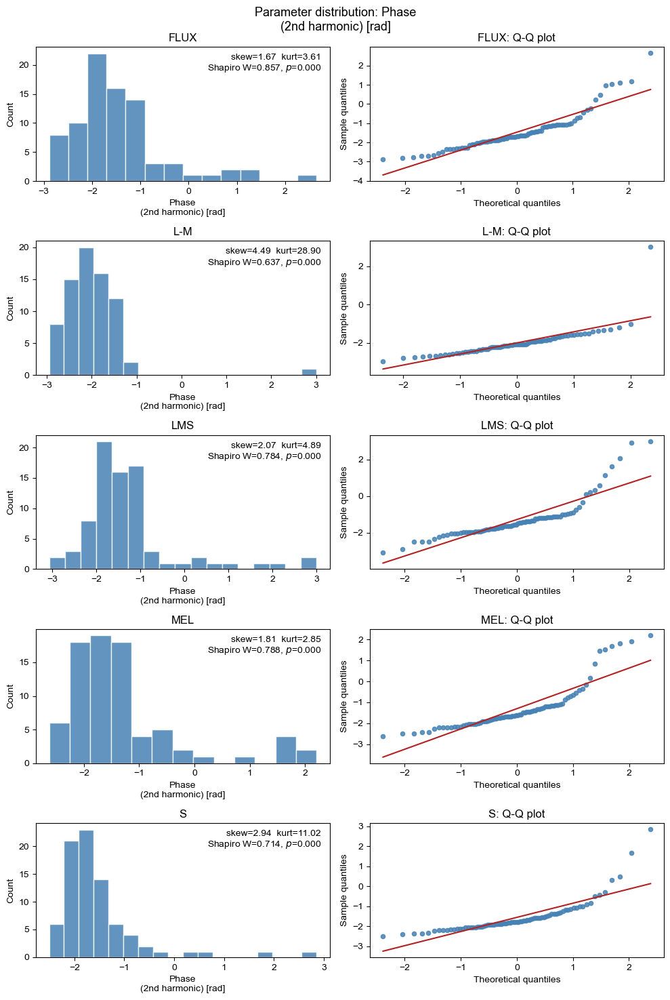

In [32]:
inspect_model(outcome_col="phase_2f")

### Step 5 -- Analyse circadian parameters: phase_2f

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'phase_2f'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83   -1.468    0.988    1.672    3.614   0.8575   0.0000  NO
l-m             74   -1.999    0.725    4.487   28.900   0.6371   0.0000  NO
lms             80   -1.284    1.110    2.066    4.886   0.7839   0.0000  NO
mel             80   -1.302    1.075    1.811    2.853   0.7878   0.0000  NO
s               81   -1.556    0.831    2.936   11.024   0.7137   0.0000  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_phase_2f.png

Analysis dataframe: 398 rows
 participant_id Trial type  Block  hours_since_start  amplitude  log_amplitude     alpha      beta  saliva_tau_hours

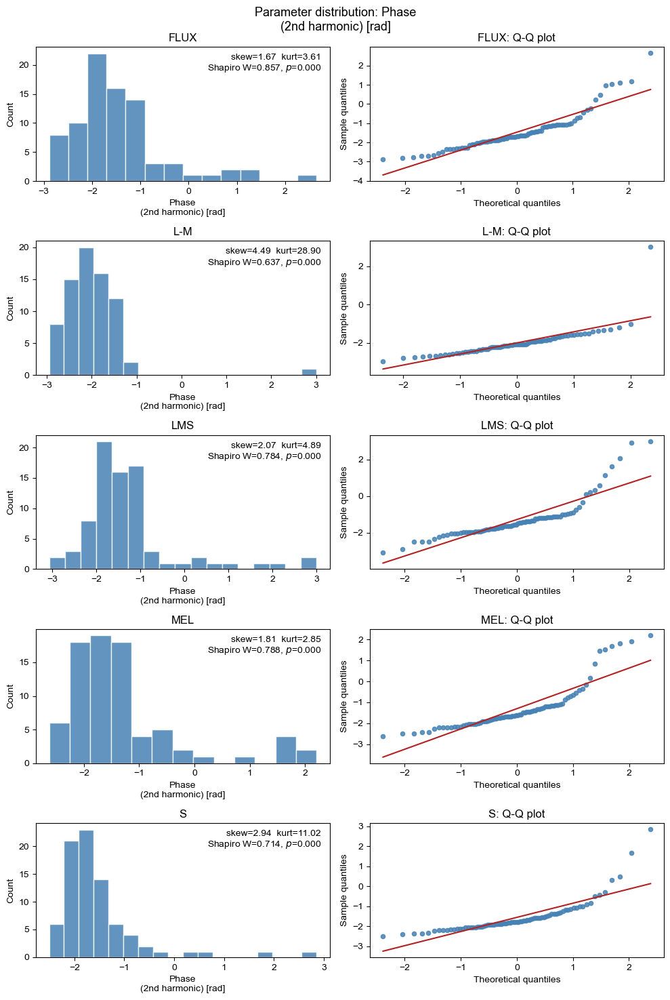

In [33]:
df_circadian_phase_2f, circadian_results["phase_2f"] = analyse_circadian(
    outcome_parameter="phase_2f",
    force=FORCE,
    dry_run=DRY_RUN,
    smc_draws=SMC_DRAWS,
    random_seed=SEED,
)

### Step 5b -- Diagnose circadian models: phase_2f

Auto-detected conditions: ['flux', 'l-m', 'lms', 'mel', 's']

── Condition: FLUX ──────────────────
  Bayesian p-value: p_B(mean)=0.469  p_B(SD)=0.656
  Saved: posterior_params_flux.csv
  r_hat  M0 max=1.0020  M1 max=1.0016
  Saved: fig_phase_2f_diagnostics_flux.png

── Condition: L-M ──────────────────
  Bayesian p-value: p_B(mean)=0.472  p_B(SD)=0.666
  Saved: posterior_params_l-m.csv
  r_hat  M0 max=1.0049  M1 max=1.0014
  Saved: fig_phase_2f_diagnostics_l-m.png

── Condition: LMS ──────────────────
  Bayesian p-value: p_B(mean)=0.608  p_B(SD)=0.640
  Saved: posterior_params_lms.csv
  r_hat  M0 max=1.0021  M1 max=1.0015
  Saved: fig_phase_2f_diagnostics_lms.png

── Condition: MEL ──────────────────
  Bayesian p-value: p_B(mean)=0.433  p_B(SD)=0.645
  Saved: posterior_params_mel.csv
  r_hat  M0 max=1.0006  M1 max=1.0010
  Saved: fig_phase_2f_diagnostics_mel.png

── Condition: S ──────────────────
  Bayesian p-value: p_B(mean)=0.399  p_B(SD)=0.653
  Saved: posterior_params_s.csv
  r_h

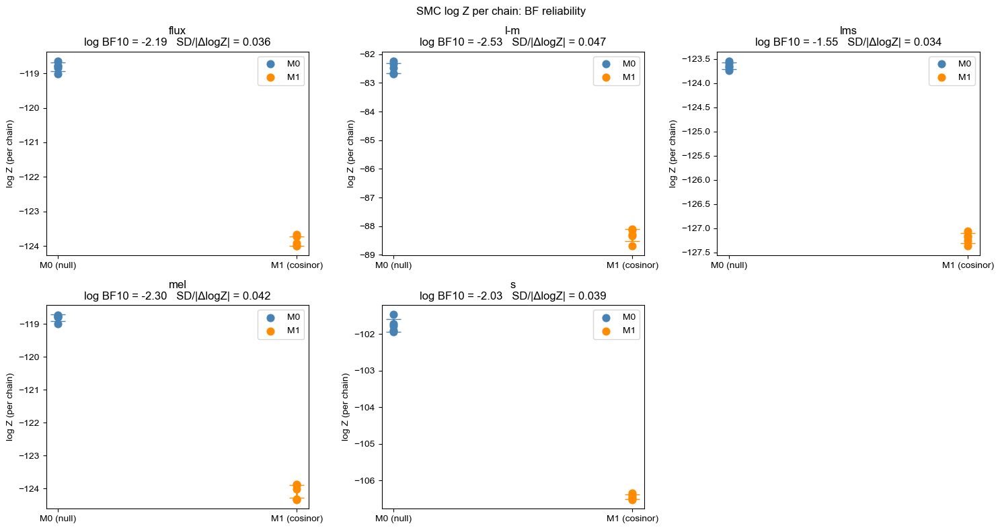

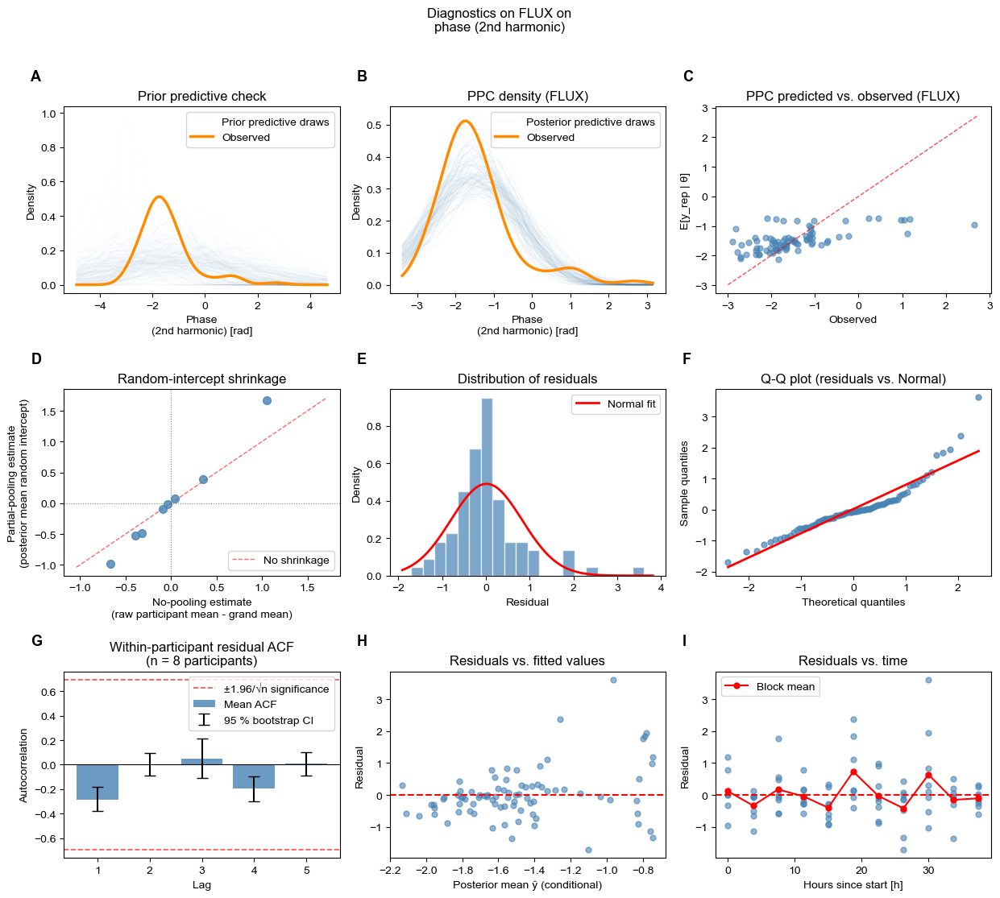

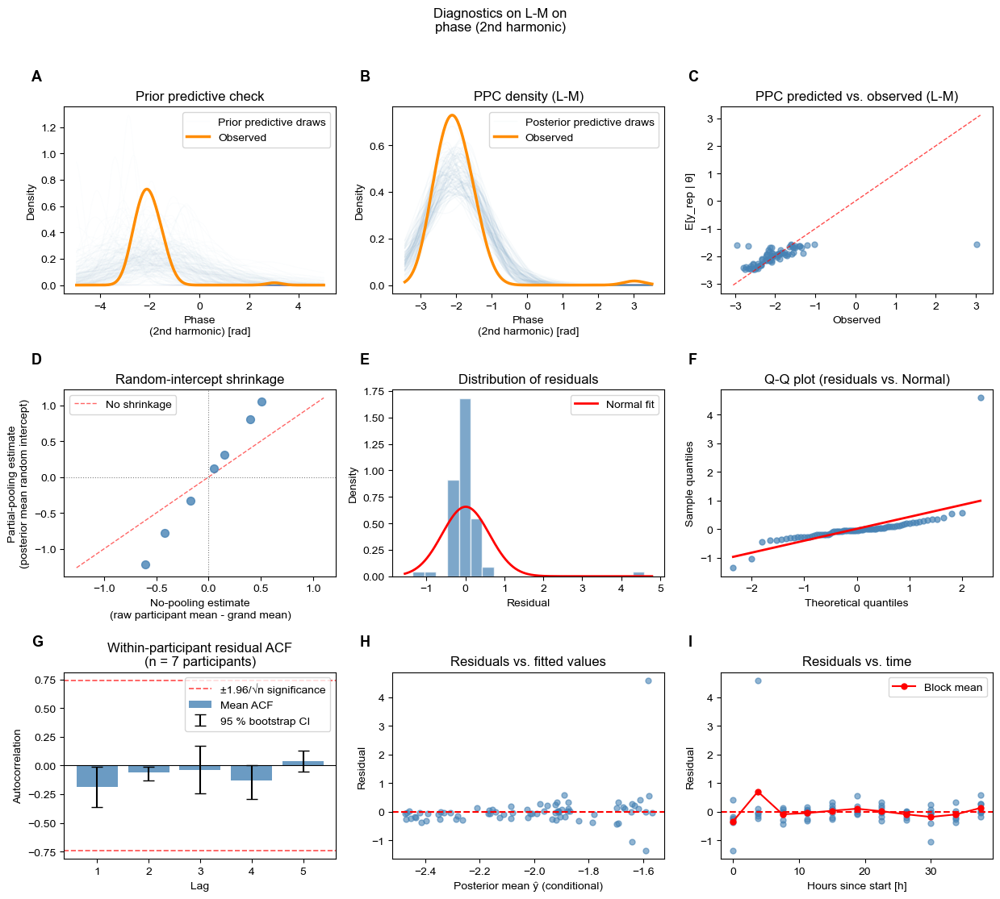

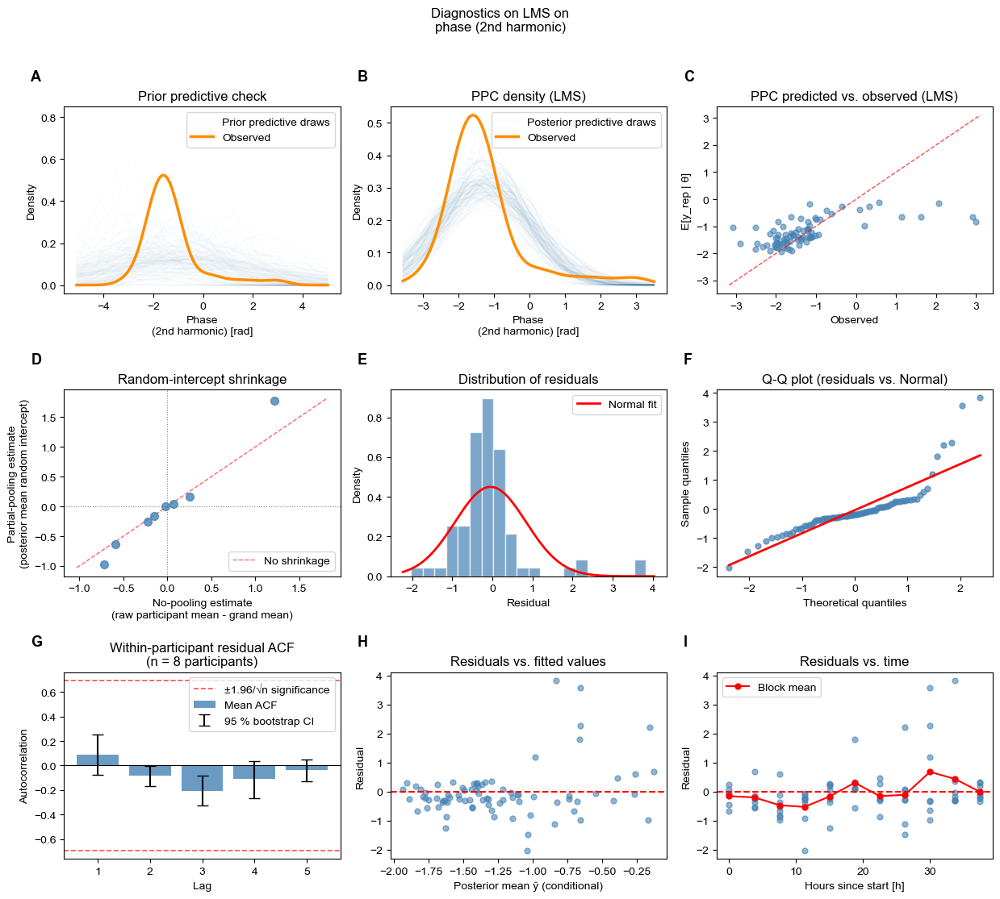

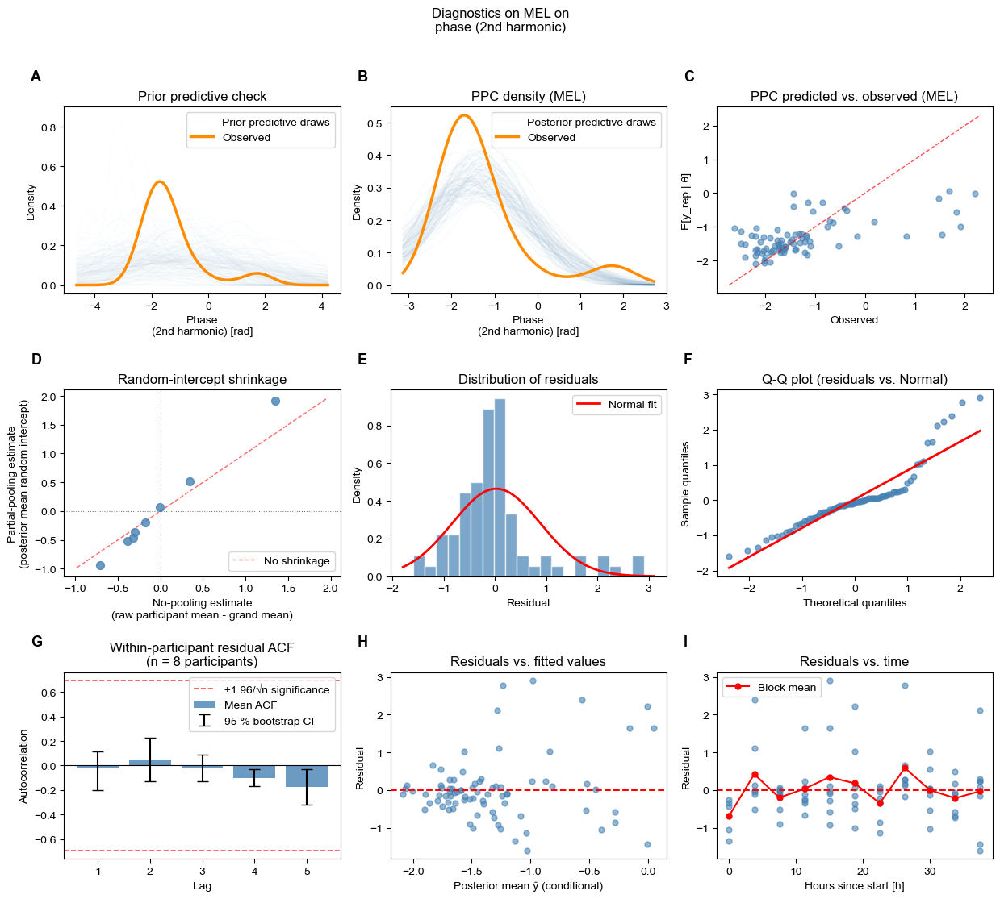

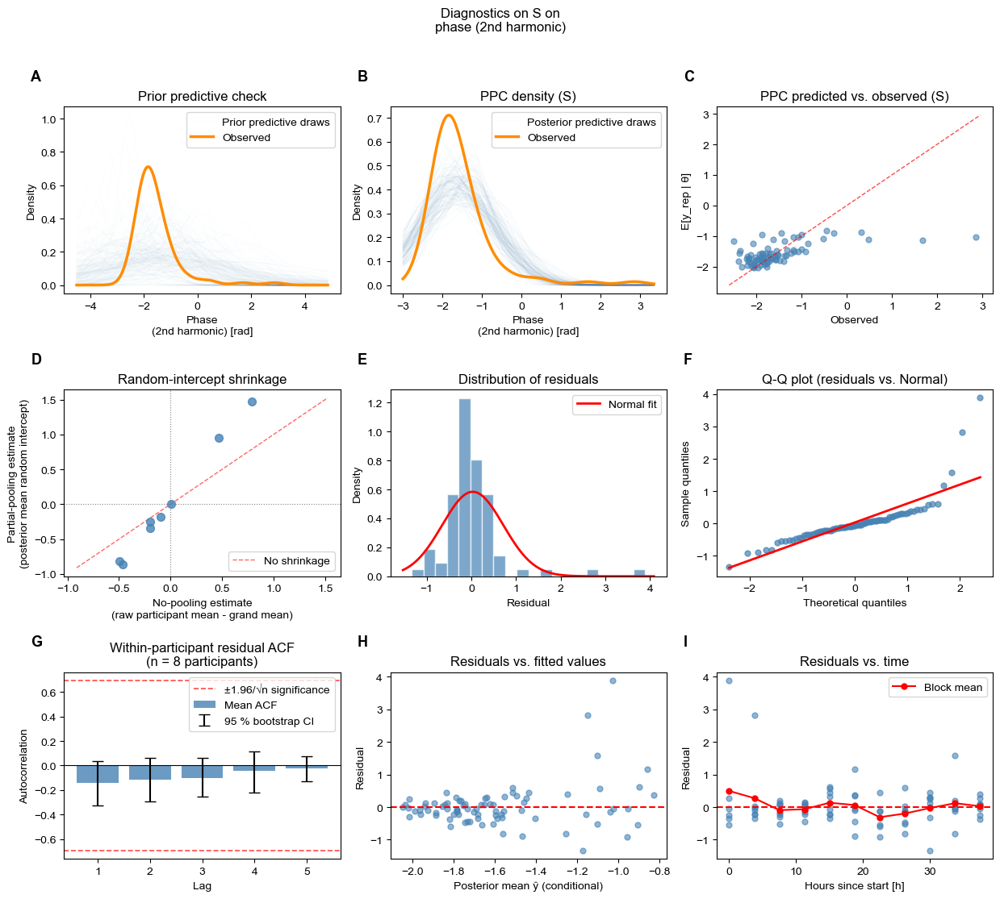

In [34]:
circadian_diag_results["phase_2f"] = diagnose_circadian(parameter_col="phase_2f")

### Step 5c -- Visualise circadian fits: phase_2f


── Condition: FLUX ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase_2f/fig_fitted_vs_empirical_flux.png

── Condition: L-M ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase_2f/fig_fitted_vs_empirical_l-m.png

── Condition: LMS ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase_2f/fig_fitted_vs_empirical_lms.png

── Condition: MEL ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase_2f/fig_fitted_vs_empirical_mel.png

── Condition: S ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/phase_2f/fig_fitted_vs_empirical_s.png

── All conditions ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/res

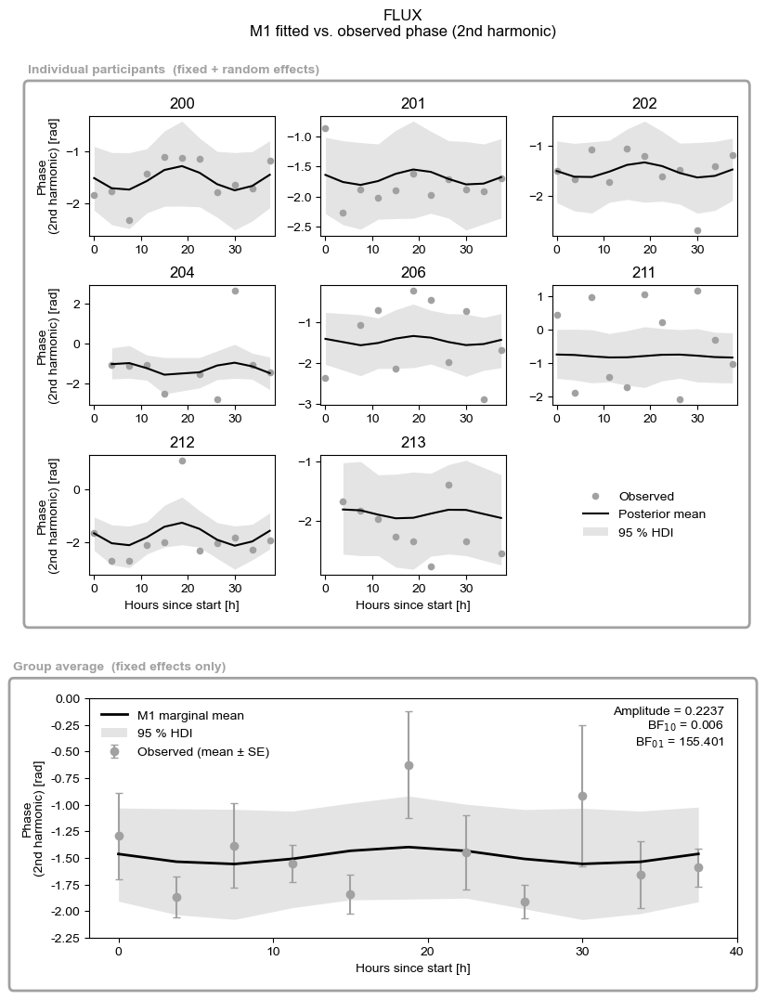

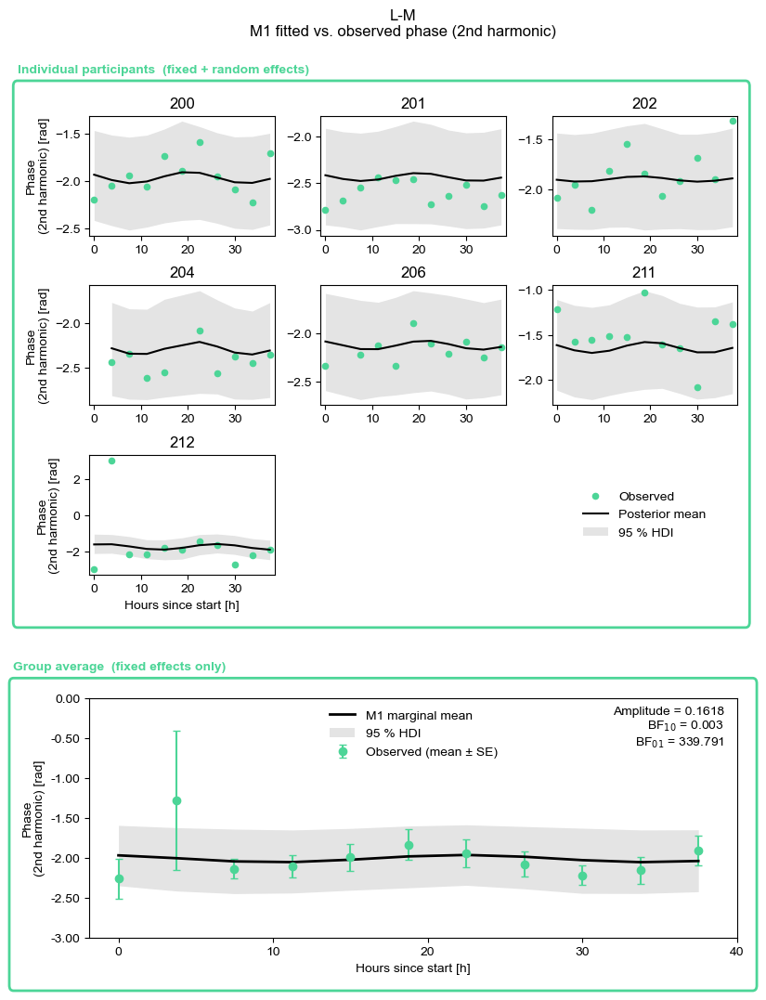

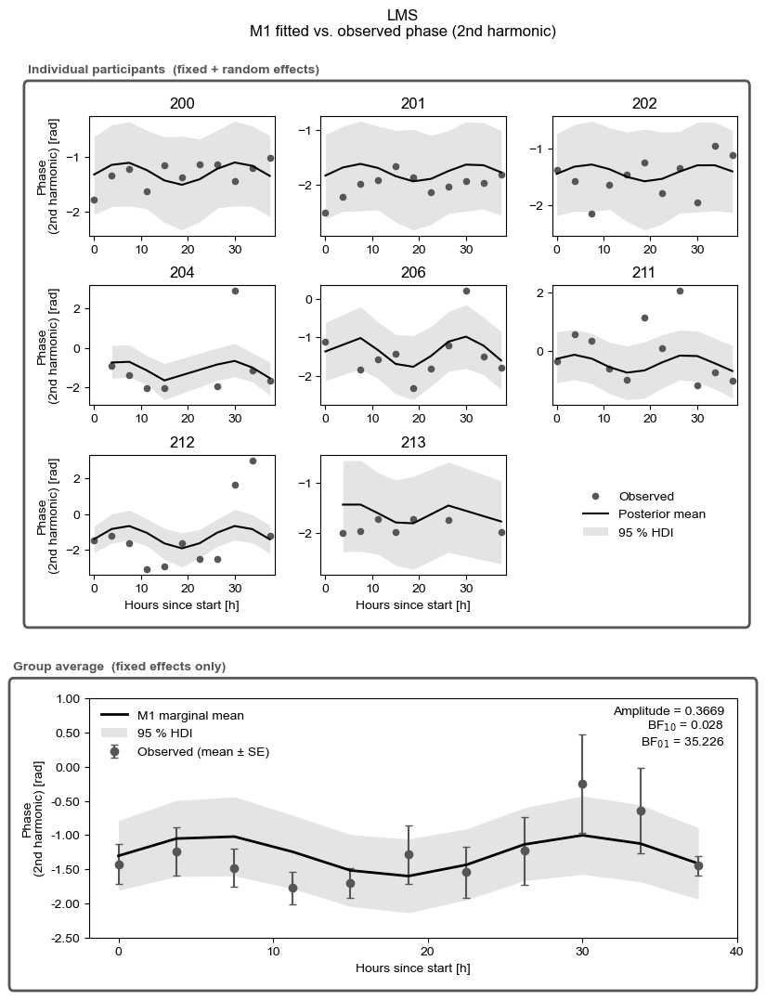

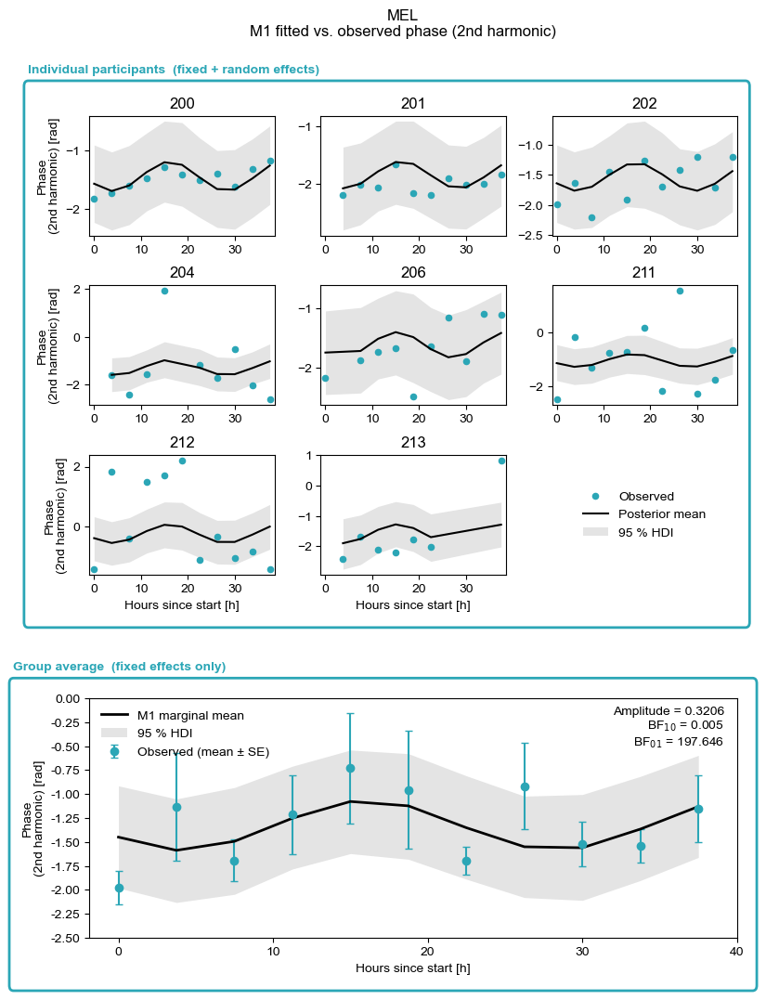

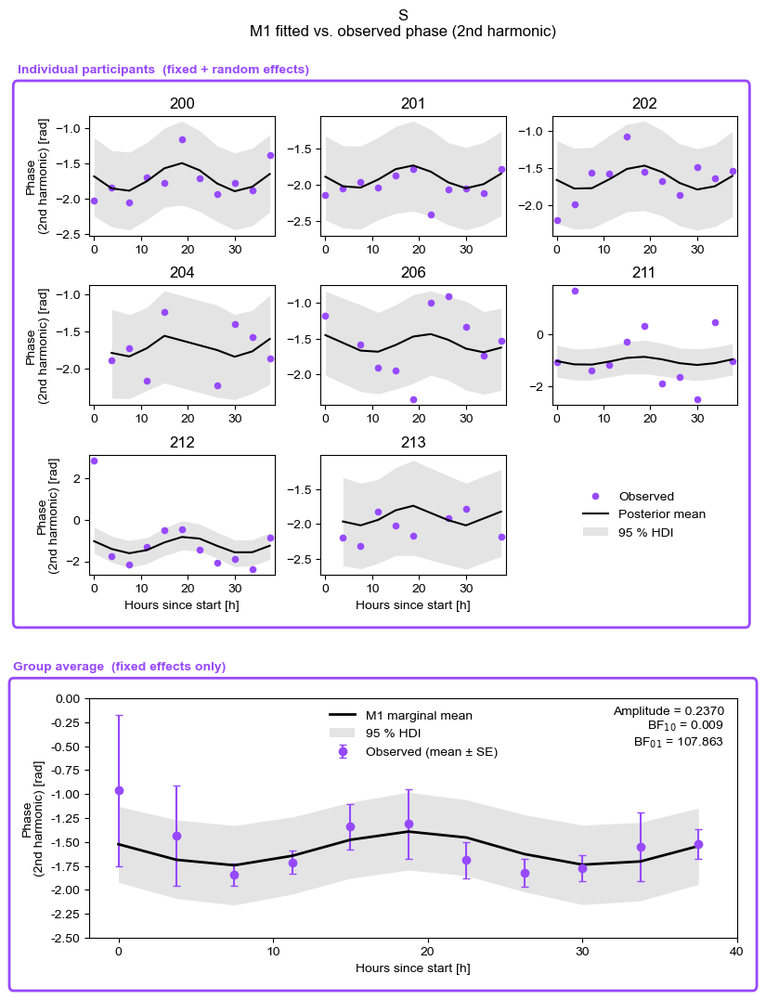

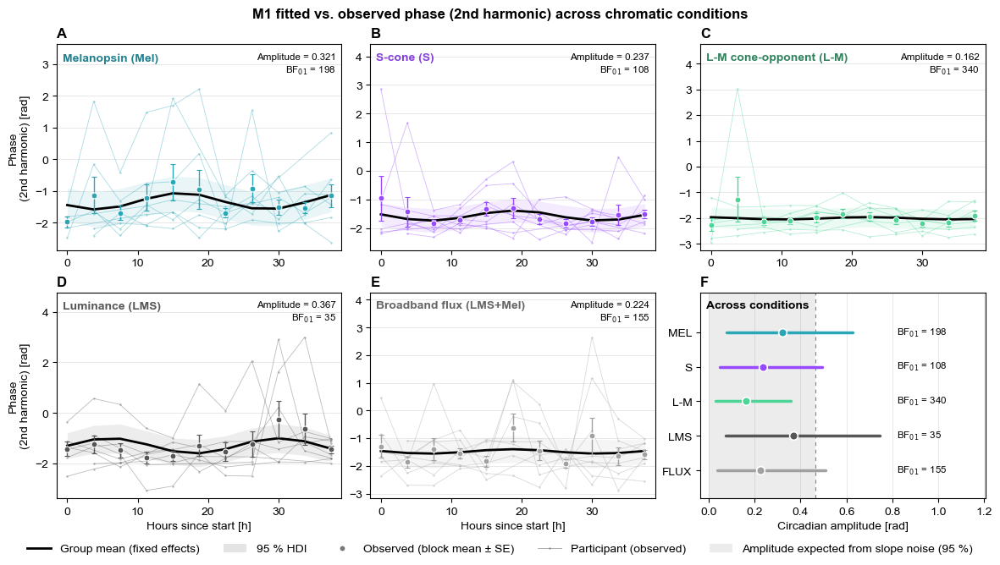

In [35]:
visualise_circadian(outcome_col="phase_2f")

## Outcome: tonic_min (main)

Minimum of the tonic (low-pass filtered) component during the stimulus window (mm, relative to baseline). It captures the slow, sustained constriction, separately from the oscillation. More negative values mean deeper constriction. Like `amplitude`, this is a revised outcome, not the protocol's registered one.

**Out:** `results/tables/circadian_cosinor/tonic_min/`, `results/figures/circadian_cosinor/tonic_min/`, `results/{tables,figures}/circadian_cosinor_diagnostics/tonic_min/`

### Step 4b -- Inspect distributions: tonic_min

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'tonic_min'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83   -0.447    0.280   -0.811    0.150   0.9389   0.0007  NO
l-m             74   -0.922    0.413   -0.077   -0.325   0.9838   0.4641  yes
lms             80   -0.532    0.365   -0.877    0.515   0.9369   0.0007  NO
mel             80   -0.438    0.355   -0.630   -0.634   0.9335   0.0004  NO
s               81   -0.594    0.360   -0.593   -0.318   0.9523   0.0043  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_tonic_min.png


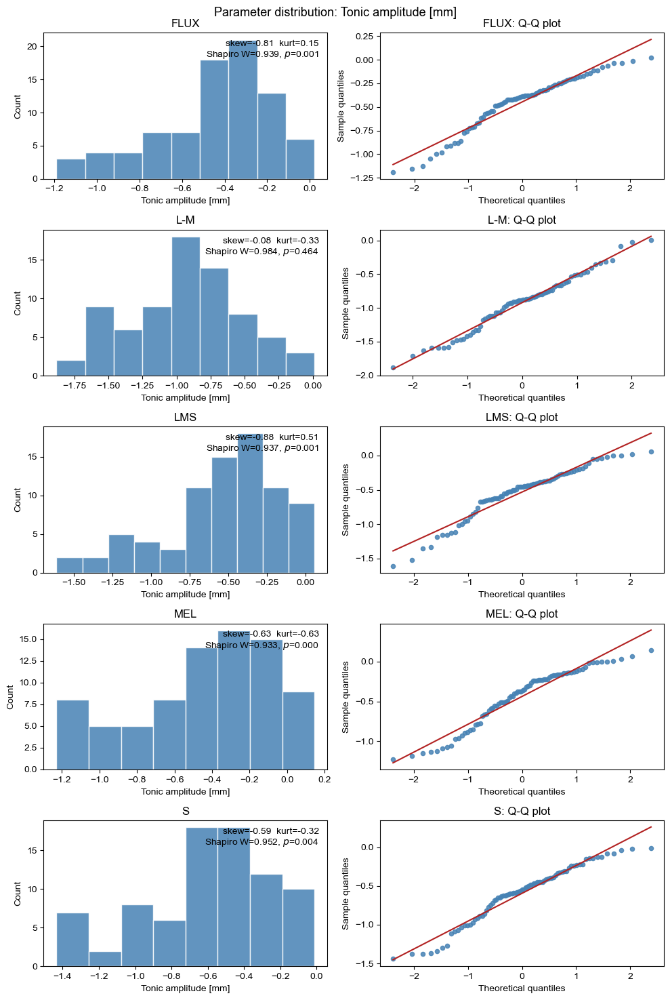

In [36]:
inspect_model(outcome_col="tonic_min")

### Step 5 -- Analyse circadian parameters: tonic_min

Loading data...
  Pupil:  398 rows  |  8 participants  |  5 conditions
  Saliva: 8 participants  |  τ range 23.07–25.17 h
\Parameter distribution check: 'tonic_min'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
flux            83   -0.447    0.280   -0.811    0.150   0.9389   0.0007  NO
l-m             74   -0.922    0.413   -0.077   -0.325   0.9838   0.4641  yes
lms             80   -0.532    0.365   -0.877    0.515   0.9369   0.0007  NO
mel             80   -0.438    0.355   -0.630   -0.634   0.9335   0.0004  NO
s               81   -0.594    0.360   -0.593   -0.318   0.9523   0.0043  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_tonic_min.png

Analysis dataframe: 398 rows
 participant_id Trial type  Block  hours_since_start  amplitude  log_amplitude     alpha      beta  saliva_tau_ho

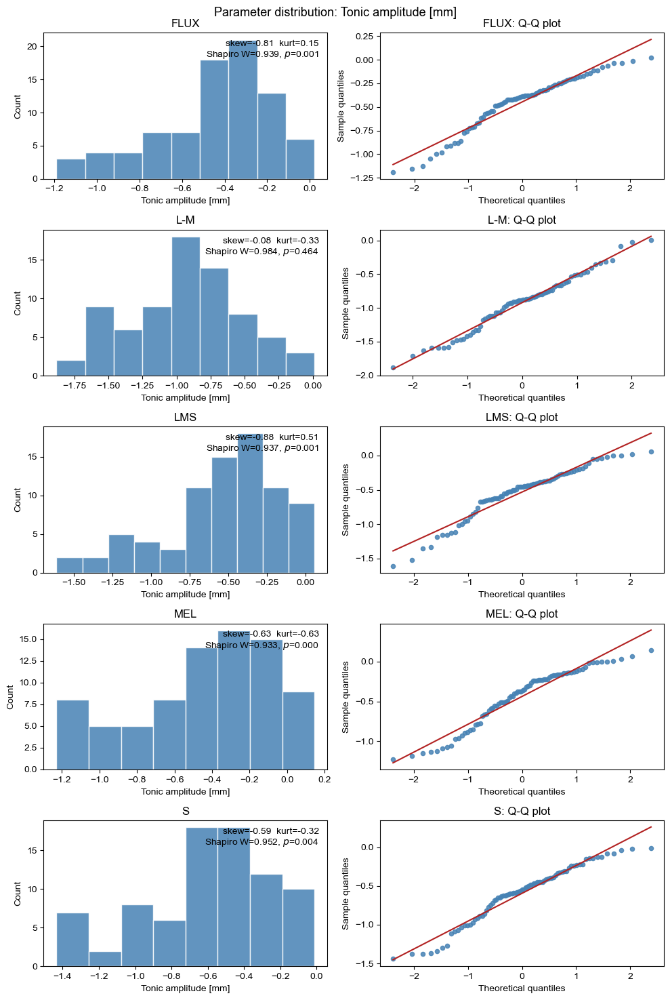

In [37]:
df_circadian_tonic_min, circadian_results["tonic_min"] = analyse_circadian(
    outcome_parameter="tonic_min",
    force=FORCE,
    dry_run=DRY_RUN,
    smc_draws=SMC_DRAWS,
    random_seed=SEED,
)

### Step 5b -- Diagnose circadian models: tonic_min

Auto-detected conditions: ['flux', 'l-m', 'lms', 'mel', 's']

── Condition: FLUX ──────────────────
  Bayesian p-value: p_B(mean)=0.349  p_B(SD)=0.581
  Saved: posterior_params_flux.csv
  r_hat  M0 max=1.0016  M1 max=1.0030
  Saved: fig_tonic_min_diagnostics_flux.png

── Condition: L-M ──────────────────
  Bayesian p-value: p_B(mean)=0.480  p_B(SD)=0.567
  Saved: posterior_params_l-m.csv
  r_hat  M0 max=1.0046  M1 max=1.0016
  Saved: fig_tonic_min_diagnostics_l-m.png

── Condition: LMS ──────────────────
  Bayesian p-value: p_B(mean)=0.533  p_B(SD)=0.568
  Saved: posterior_params_lms.csv
  r_hat  M0 max=1.0080  M1 max=1.0078
  Saved: fig_tonic_min_diagnostics_lms.png

── Condition: MEL ──────────────────
  Bayesian p-value: p_B(mean)=0.518  p_B(SD)=0.591
  Saved: posterior_params_mel.csv
  r_hat  M0 max=1.0008  M1 max=1.0028
  Saved: fig_tonic_min_diagnostics_mel.png

── Condition: S ──────────────────
  Bayesian p-value: p_B(mean)=0.490  p_B(SD)=0.587
  Saved: posterior_params_s.csv
 

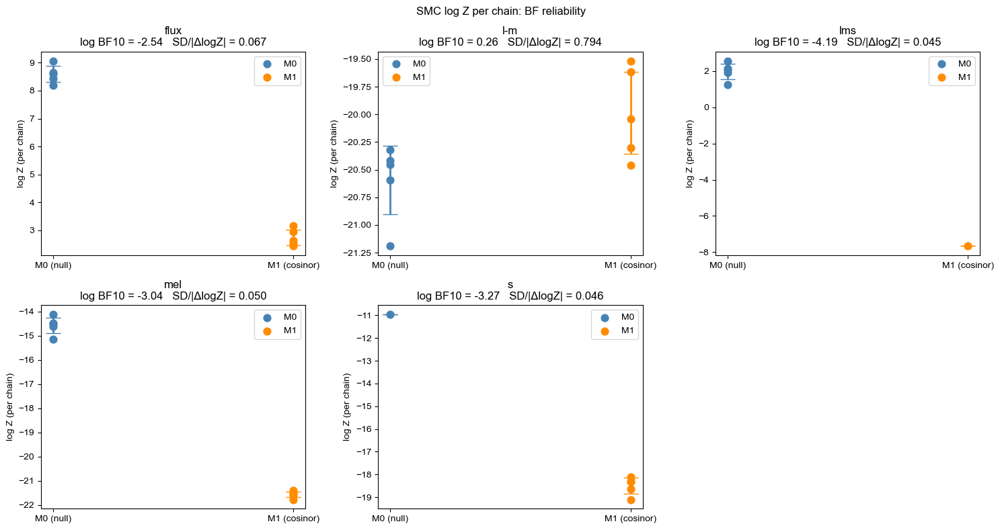

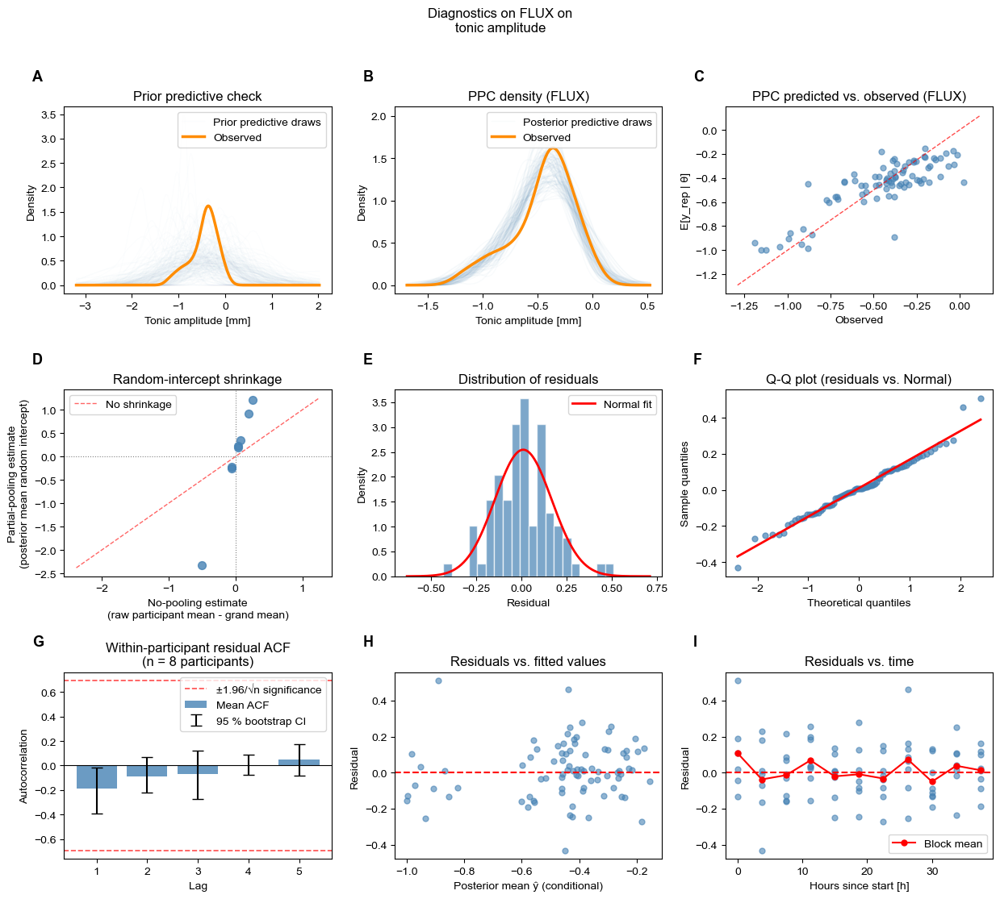

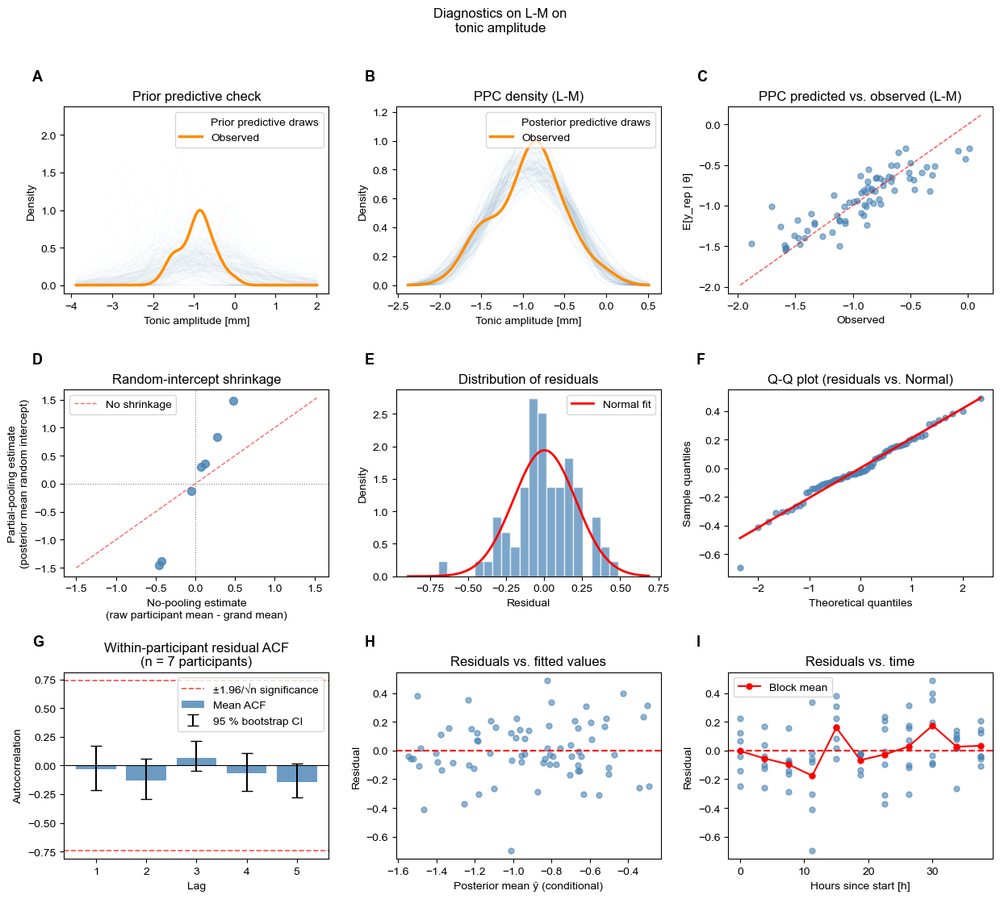

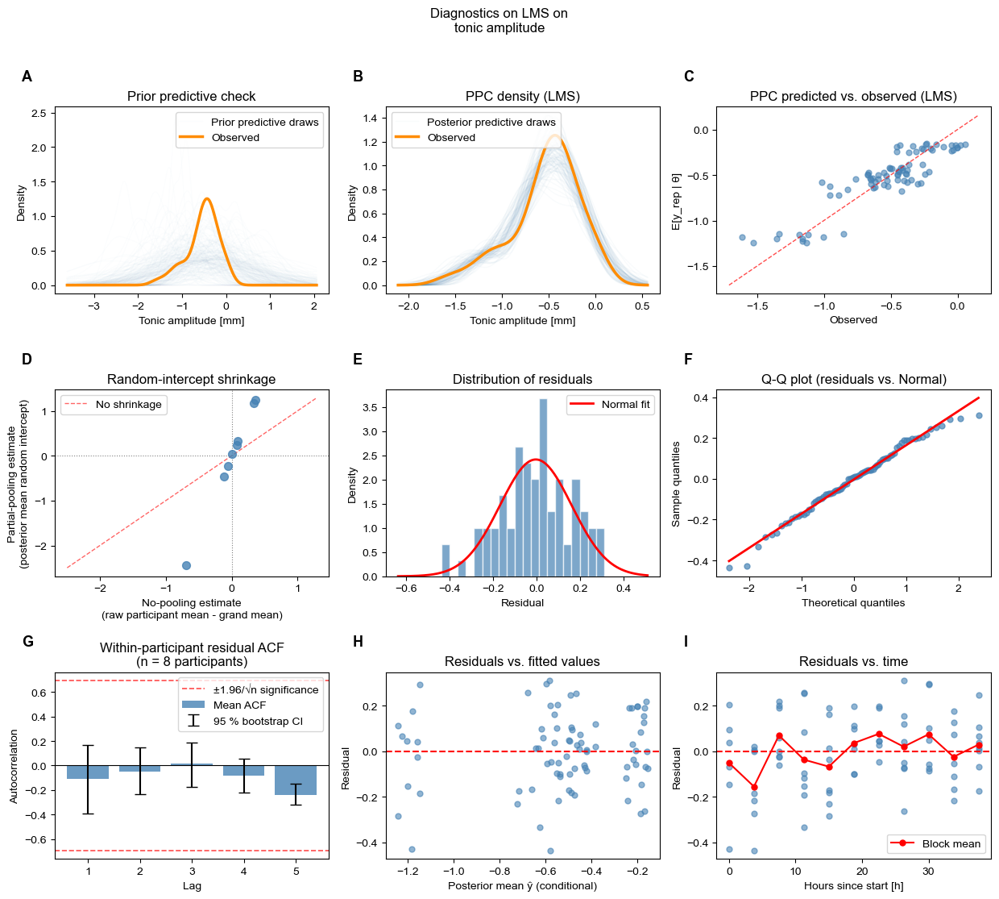

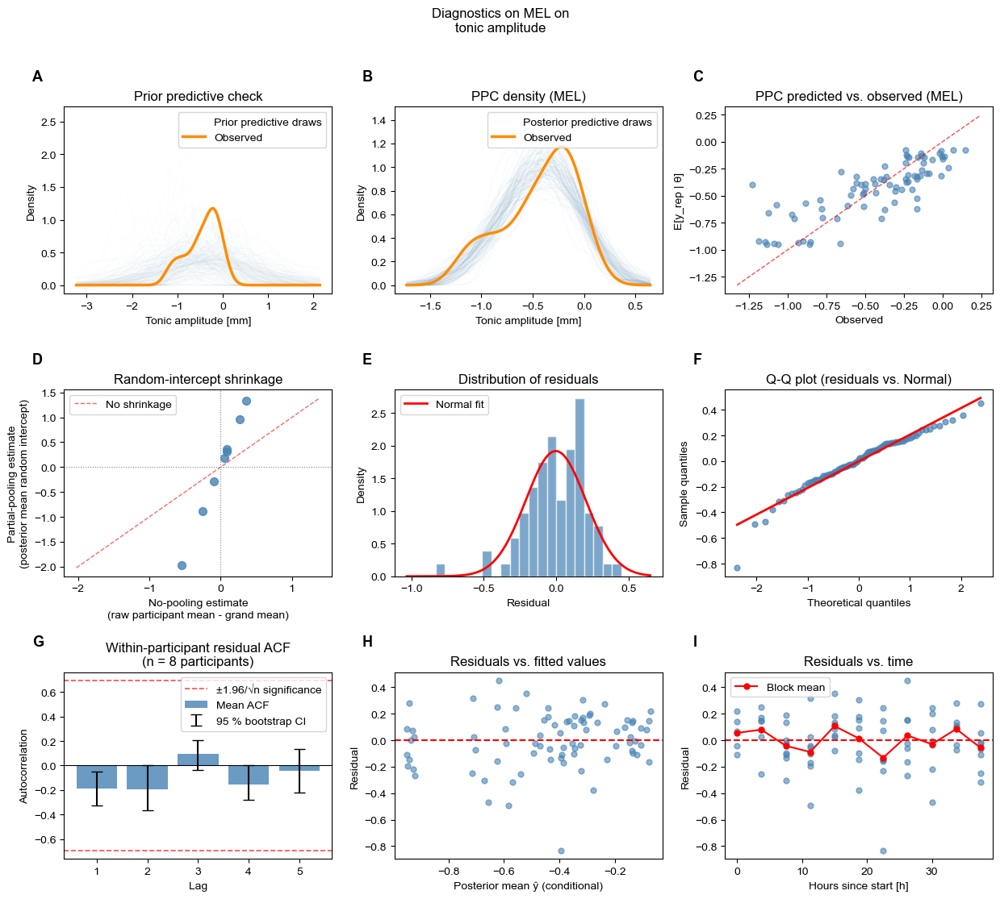

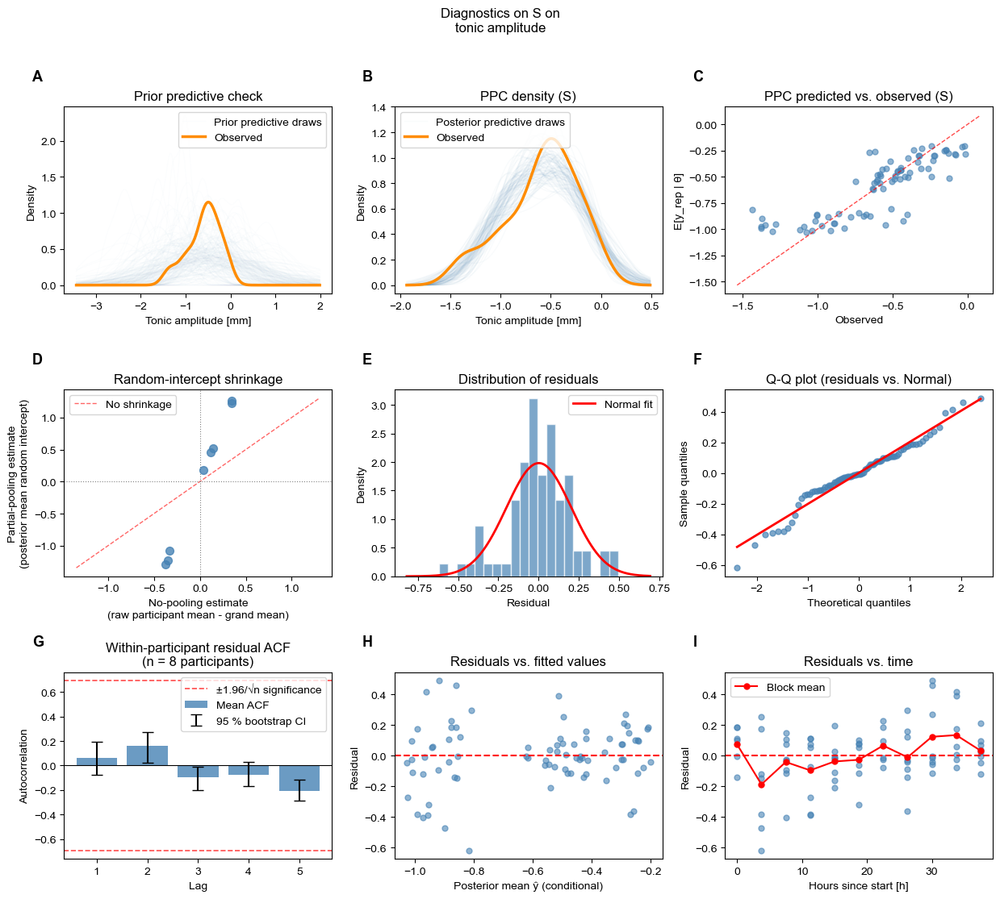

In [38]:
circadian_diag_results["tonic_min"] = diagnose_circadian(parameter_col="tonic_min")

### Step 5c -- Visualise circadian fits: tonic_min


── Condition: FLUX ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/tonic_min/fig_fitted_vs_empirical_flux.png

── Condition: L-M ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/tonic_min/fig_fitted_vs_empirical_l-m.png

── Condition: LMS ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/tonic_min/fig_fitted_vs_empirical_lms.png

── Condition: MEL ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/tonic_min/fig_fitted_vs_empirical_mel.png

── Condition: S ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/tonic_min/fig_fitted_vs_empirical_s.png

── All conditions ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometr

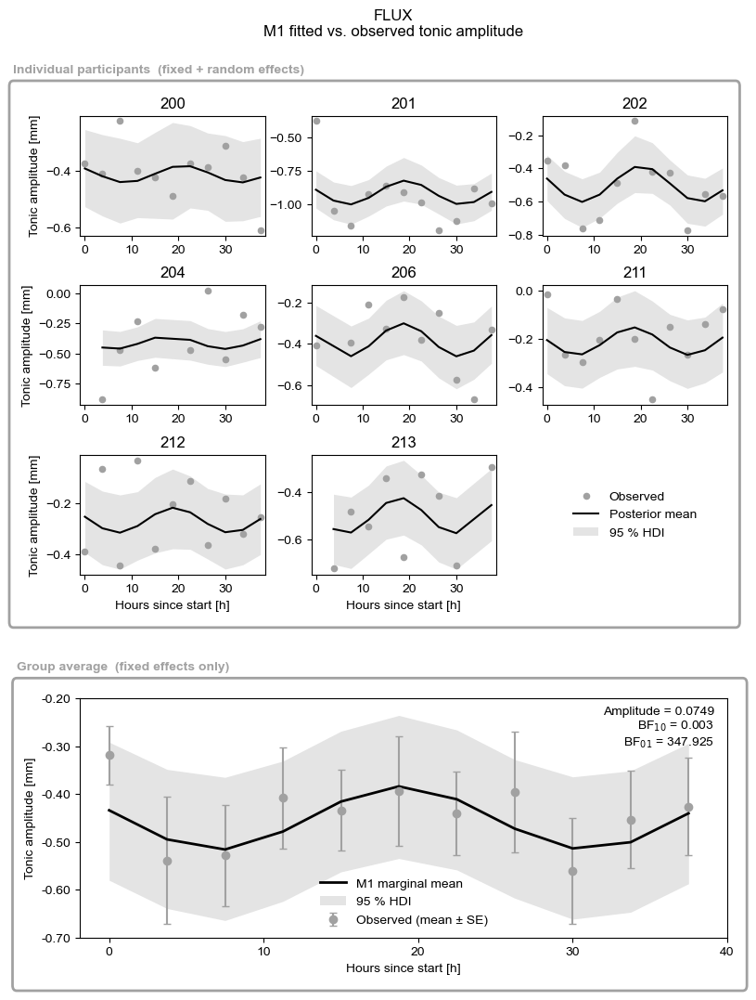

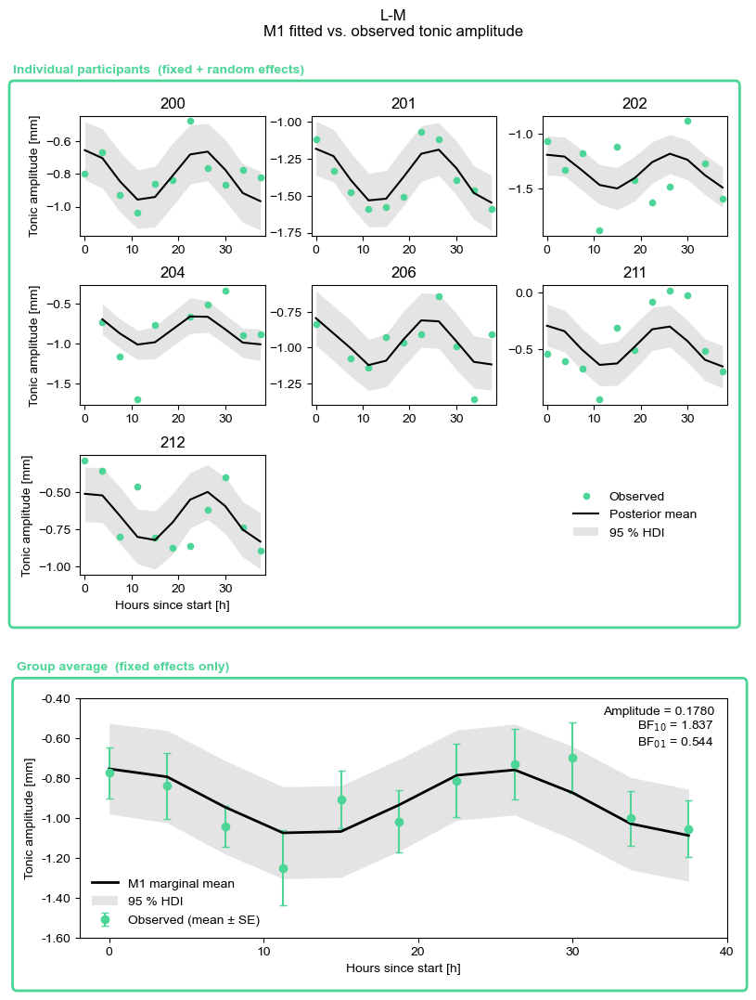

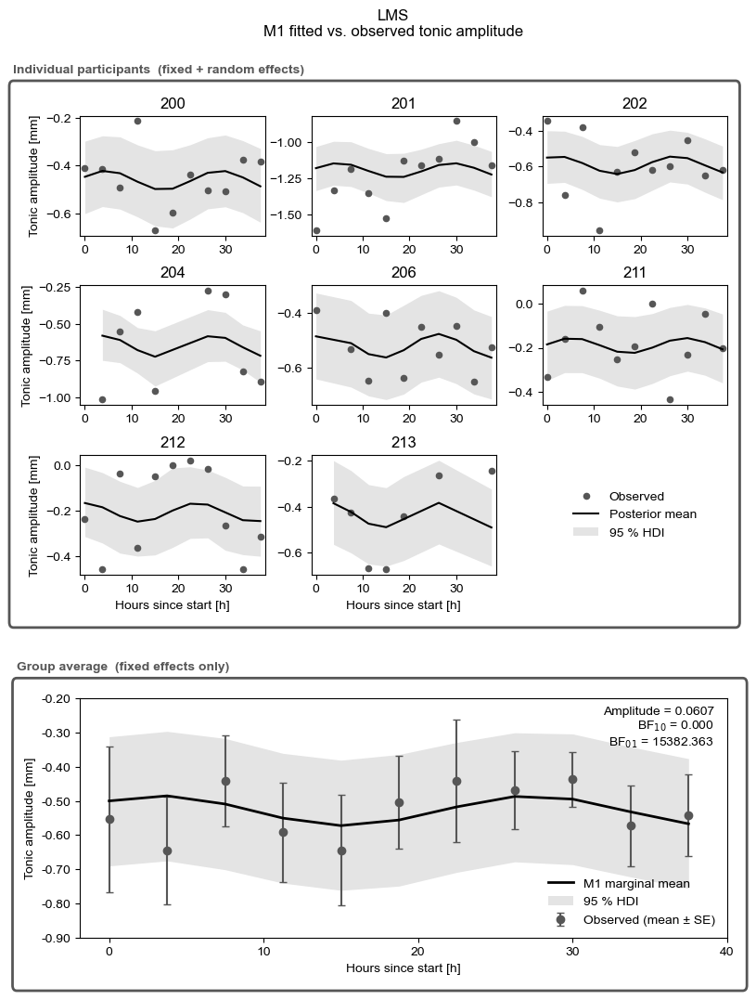

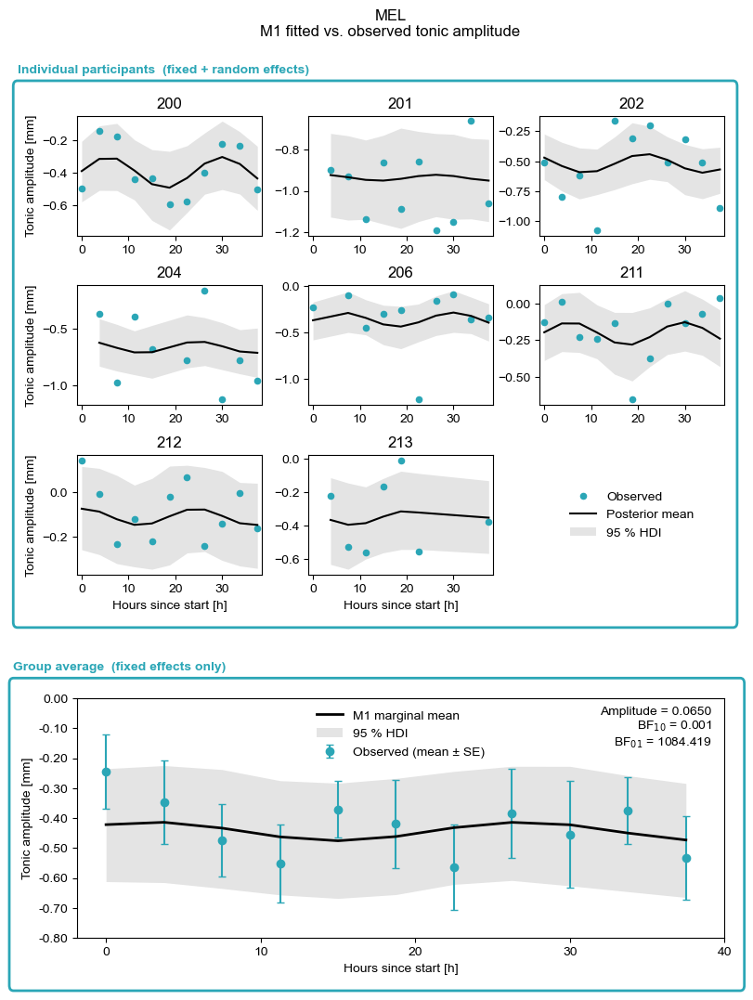

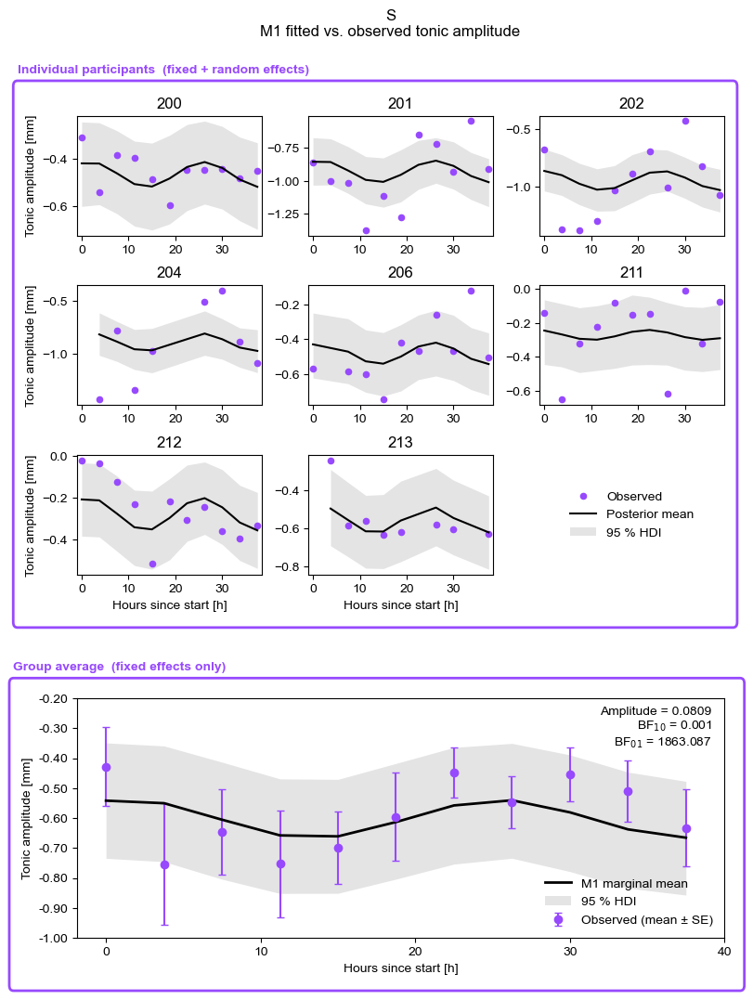

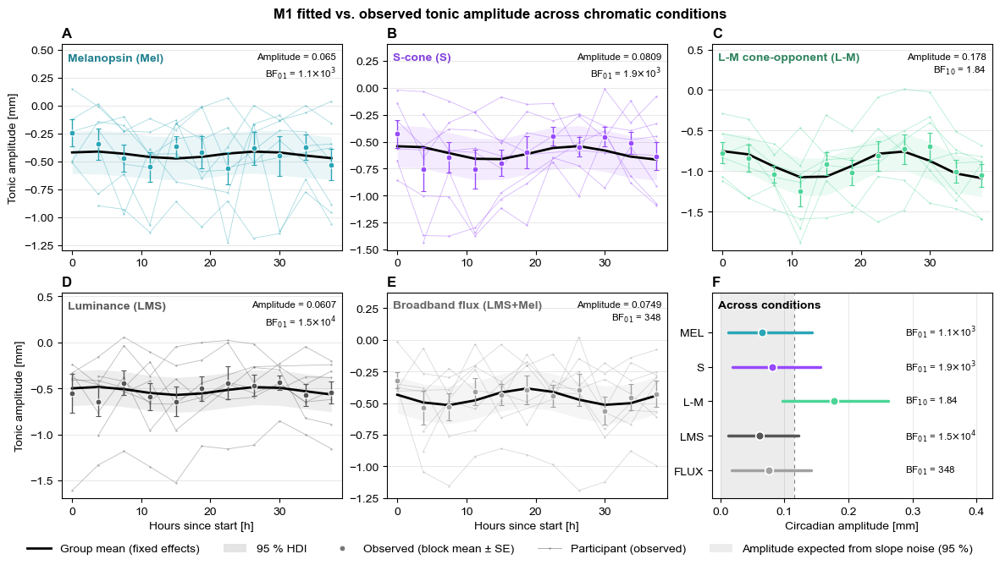

In [39]:
visualise_circadian(outcome_col="tonic_min")

#### Conclusion: constant level in four conditions; L-M favours the circadian model, but imprecisely

- Flux, LMS, Mel and S favour the constant-level model (log10 BF10 = -3.56 to -2.16).
- L-M favours the circadian model (log10 BF10 = +0.67, BF10 about 4.7), with a cosine slope interval that excludes zero. This is the only positive Bayes factor in the main analysis.
- That L-M result is the least precise Bayes factor here (SD/|dlogZ| = 0.17), and the protocol outcome does not reproduce it (`si_pipeline.ipynb`, Step 6). Treat it as fragile.
- Sampling is fine (R-hat <= 1.005). Residual normality is rejected for Mel (Shapiro p = 0.010) and borderline for S (p = 0.047).